In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
# Update Path
PARQUET_PATH = '/content/drive/MyDrive/Taxi_CRN/Data/taxidata.parquet'
SAVE_PATH    = '/content/drive/MyDrive/Taxi_CRN/Data/'

In [ ]:
import os
import subprocess

In [ ]:
# 1. Check file exists and its size
print("1. FILE CHECK:")
print(subprocess.run(['ls', '-lh', PARQUET_PATH], capture_output=True, text=True).stdout)

1. FILE CHECK:
-rw------- 1 root root 1.1G Apr  3 10:18 /content/drive/MyDrive/Taxi_CRN/Data/taxidata.parquet



In [ ]:
# 2. Check available RAM
print("2. RAM:")
print(subprocess.run(['free', '-h'], capture_output=True, text=True).stdout)

2. RAM:
               total        used        free      shared  buff/cache   available
Mem:            12Gi       882Mi       8.4Gi       2.0Mi       3.4Gi        11Gi
Swap:             0B          0B          0B



In [ ]:
# 3. Reading just the schema (no data loaded)
print("3. SCHEMA CHECK:")
import pyarrow.parquet as pq
schema = pq.read_schema(PARQUET_PATH)
print(schema)

3. SCHEMA CHECK:
VendorID: int64
tpep_pickup_datetime: string
tpep_dropoff_datetime: string
passenger_count: int64
trip_distance: double
pickup_longitude: double
pickup_latitude: double
RateCodeID: double
store_and_fwd_flag: string
dropoff_longitude: double
dropoff_latitude: double
payment_type: int64
fare_amount: double
extra: double
mta_tax: double
tip_amount: double
tolls_amount: double
improvement_surcharge: double
total_amount: double
RatecodeID: double
-- schema metadata --
pandas: '{"index_columns": [], "column_indexes": [], "columns": [{"name":' + 2618


In [ ]:
# 4. Reading just 5 rows
print("4. SAMPLE READ (5 rows):")
import pandas as pd
import pyarrow.parquet as pq
df_test = pq.read_table(PARQUET_PATH).slice(0,5).to_pandas()
print(df_test.shape)
print(df_test.head(2))

4. SAMPLE READ (5 rows):
(5, 20)
   VendorID tpep_pickup_datetime tpep_dropoff_datetime  passenger_count  \
0         2  2015-01-15 19:05:39   2015-01-15 19:23:42                1   
1         1  2015-01-10 20:33:38   2015-01-10 20:53:28                1   

   trip_distance  pickup_longitude  pickup_latitude  RateCodeID  \
0           1.59        -73.993896        40.750111         1.0   
1           3.30        -74.001648        40.724243         1.0   

  store_and_fwd_flag  dropoff_longitude  dropoff_latitude  payment_type  \
0                  N         -73.974785         40.750618             1   
1                  N         -73.994415         40.759109             1   

   fare_amount  extra  mta_tax  tip_amount  tolls_amount  \
0         12.0    1.0      0.5        3.25           0.0   
1         14.5    0.5      0.5        2.00           0.0   

   improvement_surcharge  total_amount  RatecodeID  
0                    0.3         17.05         NaN  
1                    0.3  

In [ ]:
# LOAD ONLY 2016 + NEEDED COLUMNS
import pandas as pd
import pyarrow.parquet as pq
import pyarrow.compute as pc
import pyarrow as pa
import gc

In [ ]:
COLS = [
    'tpep_pickup_datetime', 'tpep_dropoff_datetime',
    'trip_distance',
    'pickup_longitude', 'pickup_latitude',
    'dropoff_longitude', 'dropoff_latitude',
    'passenger_count', 'RateCodeID', 'payment_type',
]

In [ ]:
print("Reading parquet in chunks and filtering in Arrow...")

parquet_file = pq.ParquetFile(PARQUET_PATH)
print(f"Total row groups: {parquet_file.metadata.num_row_groups}")

Reading parquet in chunks and filtering in Arrow...
Total row groups: 46


In [ ]:
chunks = []
total_kept = 0

In [ ]:
for i, batch in enumerate(parquet_file.iter_batches(batch_size=500_000, columns=COLS)):
    # Filter inside Arrow - no full pandas conversion
    tbl = pa.Table.from_batches([batch])

    # Cast datetime column (its a string)
    import pyarrow as pa
    pickup_col = pc.strptime(tbl['tpep_pickup_datetime'], format='%Y-%m-%d %H:%M:%S', unit='s')
    year_col   = pc.year(pickup_col)
    mask       = pc.equal(year_col, 2016)
    tbl_filtered = tbl.filter(mask)

    if tbl_filtered.num_rows > 0:
        chunks.append(tbl_filtered.to_pandas())
        total_kept += tbl_filtered.num_rows

    del tbl, tbl_filtered, batch
    gc.collect()

    if i % 5 == 0:
        print(f"  Batch {i}: kept {total_kept:,} rows so far...")

print(f"\nStep 2: Combining {len(chunks)} chunks...")
df = pd.concat(chunks, ignore_index=True)
del chunks
gc.collect()


print(f"Shape     : {df.shape}")
print(f"Memory    : {df.memory_usage(deep=True).sum()/1e6:.1f} MB")
print(f"Date range: {df['tpep_pickup_datetime'].min()} → {df['tpep_pickup_datetime'].max()}")
print(df.head(3))

  Batch 0: kept 0 rows so far...
  Batch 5: kept 0 rows so far...
  Batch 10: kept 0 rows so far...
  Batch 15: kept 0 rows so far...
  Batch 20: kept 0 rows so far...
  Batch 25: kept 251,014 rows so far...
  Batch 30: kept 2,751,014 rows so far...
  Batch 35: kept 5,251,014 rows so far...
  Batch 40: kept 7,751,014 rows so far...
  Batch 45: kept 10,251,014 rows so far...
  Batch 50: kept 12,751,014 rows so far...
  Batch 55: kept 15,251,014 rows so far...
  Batch 60: kept 17,751,014 rows so far...
  Batch 65: kept 20,251,014 rows so far...
  Batch 70: kept 22,751,014 rows so far...
  Batch 75: kept 25,251,014 rows so far...
  Batch 80: kept 27,751,014 rows so far...
  Batch 85: kept 30,251,014 rows so far...
  Batch 90: kept 32,751,014 rows so far...

Step 2: Combining 70 chunks...
Shape     : (34499859, 10)
Memory    : 6900.0 MB
Date range: 2016-01-01 00:00:00 → 2016-03-31 23:59:59
  tpep_pickup_datetime tpep_dropoff_datetime  trip_distance  pickup_longitude  \
0  2016-01-01 00:00:

In [ ]:
# Save 2016-only parquet
df.to_parquet(SAVE_PATH + 'taxi_2016_only.parquet', index=False)
print(f"Saved taxi_2016_only.parquet — {len(df):,} rows")

Saved taxi_2016_only.parquet — 34,499,859 rows


The full parquet contained 47M rows spanning multiple years - 2016 data alone is 34.5M trips (Jan-Mar)

Data is temporally ordered - first 25 batches (≈12.5M rows) were pre-2016, confirming multi-year storage

In [ ]:
import pandas as pd
import numpy as np
import gc

df = pd.read_parquet(SAVE_PATH + 'taxi_2016_only.parquet')
df['tpep_pickup_datetime']  = pd.to_datetime(df['tpep_pickup_datetime'],  errors='coerce')
df['tpep_dropoff_datetime'] = pd.to_datetime(df['tpep_dropoff_datetime'], errors='coerce')

print(f"Loaded: {len(df):,} rows")
print(f"Memory: {df.memory_usage(deep=True).sum()/1e6:.0f} MB")

Loaded: 34,499,859 rows
Memory: 2760 MB


In [ ]:
# DATA QUALITY AUDIT

import pandas as pd
import numpy as np

print("=" * 55)
print("1. SHAPE")
print("=" * 55)
print(f"Rows: {len(df):,}  |  Cols: {df.shape[1]}")

print("\n" + "=" * 55)
print("2. MISSING VALUES")
print("=" * 55)
missing = df.isnull().sum()
missing_pct = (missing / len(df) * 100).round(2)
print(pd.DataFrame({'count': missing, 'pct': missing_pct})
      [missing > 0].sort_values('pct', ascending=False))

print("\n" + "=" * 55)
print("3. TARGET — duration_min (not yet computed, previewing)")
print("=" * 55)
df['tpep_pickup_datetime']  = pd.to_datetime(df['tpep_pickup_datetime'],  errors='coerce')
df['tpep_dropoff_datetime'] = pd.to_datetime(df['tpep_dropoff_datetime'], errors='coerce')
df['duration_min'] = (df['tpep_dropoff_datetime'] - df['tpep_pickup_datetime']).dt.total_seconds() / 60
print(df['duration_min'].describe().round(3))
print(f"Negative  : {(df['duration_min'] <   0).sum():,}")
print(f"Zero      : {(df['duration_min'] ==  0).sum():,}")
print(f"< 1 min   : {(df['duration_min'] <   1).sum():,}")
print(f"> 120 min : {(df['duration_min'] > 120).sum():,}")

print("\n" + "=" * 55)
print("4. TRIP DISTANCE")
print("=" * 55)
print(df['trip_distance'].describe().round(3))
print(f"Zero distance : {(df['trip_distance'] == 0).sum():,}")
print(f"> 50 miles    : {(df['trip_distance'] > 50).sum():,}")

print("\n" + "=" * 55)
print("5. COORDINATES")
print("=" * 55)
for col, lo, hi in [
    ('pickup_latitude',   40.4, 41.0),
    ('pickup_longitude', -74.3,-73.6),
    ('dropoff_latitude',  40.4, 41.0),
    ('dropoff_longitude',-74.3,-73.6),
]:
    bad = (~df[col].between(lo, hi)).sum()
    print(f"{col:25s}: min={df[col].min():.4f}  max={df[col].max():.4f}  out-of-NYC={bad:,}")

print("\n" + "=" * 55)
print("6. MONTH DISTRIBUTION")
print("=" * 55)
print(df['tpep_pickup_datetime'].dt.month.value_counts().sort_index()
      .rename({1:'January', 2:'February', 3:'March'}))

1. SHAPE
Rows: 34,499,859  |  Cols: 10

2. MISSING VALUES
               count    pct
RateCodeID  34499859  100.0

3. TARGET — duration_min (not yet computed, previewing)
count    3.449986e+07
mean     1.549900e+01
std      2.023330e+02
min     -5.371001e+05
25%      6.417000e+00
50%      1.065000e+01
75%      1.716700e+01
max      1.923134e+05
Name: duration_min, dtype: float64
Negative  : 176
Zero      : 36,091
< 1 min   : 276,651
> 120 min : 55,478

4. TRIP DISTANCE
count    3.449986e+07
mean     5.309000e+00
std      4.672575e+03
min     -3.390584e+06
25%      1.000000e+00
50%      1.690000e+00
75%      3.100000e+00
max      1.907263e+07
Name: trip_distance, dtype: float64
Zero distance : 202,875
> 50 miles    : 1,437

5. COORDINATES
pickup_latitude          : min=-77.0395  max=66.8568  out-of-NYC=531,412
pickup_longitude         : min=-161.6987  max=94.6439  out-of-NYC=532,001
dropoff_latitude         : min=-77.0395  max=405.3167  out-of-NYC=504,984
dropoff_longitude        : min=

In [ ]:
# CLEAN - CHUNK WRITE, ZERO COPY
import pandas as pd
import numpy as np
import pyarrow as pa
import pyarrow.parquet as pq
import gc

SAVE_PATH = '/content/drive/MyDrive/Taxi_CRN/Data/'
CHUNK_SIZE = 2_000_000
OUTPUT_PATH = SAVE_PATH + 'taxi_2016_cleaned.parquet'

# Parse datetimes in place
df['tpep_pickup_datetime']  = pd.to_datetime(df['tpep_pickup_datetime'],  errors='coerce')
df['tpep_dropoff_datetime'] = pd.to_datetime(df['tpep_dropoff_datetime'], errors='coerce')
df['duration_min'] = (df['tpep_dropoff_datetime'] - df['tpep_pickup_datetime']).dt.total_seconds() / 60
df['speed_mph']    = df['trip_distance'] / ((df['duration_min'] + 0.001) / 60)
df.drop(columns=['RateCodeID'], inplace=True, errors='ignore')
gc.collect()

writer      = None
total_kept  = 0
total_rows  = len(df)
n_chunks    = (total_rows // CHUNK_SIZE) + 1

for i in range(n_chunks):
    start = i * CHUNK_SIZE
    end   = min(start + CHUNK_SIZE, total_rows)
    chunk = df.iloc[start:end]

    mask = (
        chunk['duration_min'].between(1, 120) &
        chunk['trip_distance'].between(0.1, 50) &
        chunk['speed_mph'].between(1, 60) &
        chunk['pickup_latitude'].between(40.4, 41.0) &
        chunk['pickup_longitude'].between(-74.3, -73.6) &
        chunk['dropoff_latitude'].between(40.4, 41.0) &
        chunk['dropoff_longitude'].between(-74.3, -73.6) &
        chunk['pickup_latitude'].notna() &
        chunk['pickup_longitude'].notna() &
        chunk['dropoff_latitude'].notna() &
        chunk['dropoff_longitude'].notna()
    )

    clean_chunk = chunk[mask].reset_index(drop=True)

    if len(clean_chunk) > 0:
        table = pa.Table.from_pandas(clean_chunk, preserve_index=False)
        if writer is None:
            writer = pq.ParquetWriter(OUTPUT_PATH, table.schema)
        writer.write_table(table)
        total_kept += len(clean_chunk)

    del chunk, clean_chunk, mask
    gc.collect()

    if i % 5 == 0:
        print(f"Chunk {i+1}/{n_chunks} done - kept {total_kept:,} rows so far")

if writer:
    writer.close()

print(f"\n Done - kept {total_kept:,} / {total_rows:,} rows")
print(f"   Removed: {total_rows - total_kept:,} ({(total_rows-total_kept)/total_rows*100:.1f}%)")
print(f"   Saved  : {OUTPUT_PATH}")

Chunk 1/18 done - kept 1,936,198 rows so far
Chunk 6/18 done - kept 11,687,517 rows so far
Chunk 11/18 done - kept 21,420,198 rows so far
Chunk 16/18 done - kept 31,162,862 rows so far

 Done - kept 33,600,398 / 34,499,859 rows
   Removed: 899,461 (2.6%)
   Saved  : /content/drive/MyDrive/Taxi_CRN/Data/taxi_2016_cleaned.parquet


Cleaning removed 899k rows (2.6%) - mainly coordinate outliers (530k out-of-NYC), extreme durations, and impossible distances. Core data quality is strong

In [ ]:
# RELOAD CLEAN + FEATURE ENGINEERING + SAVE
import pandas as pd
import numpy as np
from sklearn.cluster import MiniBatchKMeans
import pyarrow as pa
import pyarrow.parquet as pq
import gc

In [ ]:
SAVE_PATH   = '/content/drive/MyDrive/Taxi_CRN/Data/'
OUTPUT_PATH = SAVE_PATH + 'taxi_2016_features_v2.parquet'

In [ ]:
# Load Clean
df = pd.read_parquet(SAVE_PATH + 'taxi_2016_cleaned.parquet')
df['tpep_pickup_datetime'] = pd.to_datetime(df['tpep_pickup_datetime'], errors='coerce')
print(f"Loaded: {len(df):,} rows | {df.memory_usage(deep=True).sum()/1e6:.0f} MB")

Loaded: 33,600,398 rows | 2957 MB


In [ ]:
# TIME
df['pickup_hour'] = df['tpep_pickup_datetime'].dt.hour.astype(np.int8)
df['day_of_week'] = df['tpep_pickup_datetime'].dt.dayofweek.astype(np.int8)
df['month']       = df['tpep_pickup_datetime'].dt.month.astype(np.int8)
df['is_weekend']  = df['day_of_week'].isin([5,6]).astype(np.int8)
df['rush_hour']   = df['pickup_hour'].isin([7,8,9,16,17,18,19]).astype(np.int8)
df['late_night']  = df['pickup_hour'].isin([0,1,2,3,4]).astype(np.int8)
gc.collect()
print("Time features done")

Time features done


In [ ]:
# SPATIAL
def haversine_miles(lat1, lon1, lat2, lon2):
    R = 3958.8
    la1,lo1,la2,lo2 = map(np.radians,[lat1,lon1,lat2,lon2])
    a = np.sin((la2-la1)/2)**2 + np.cos(la1)*np.cos(la2)*np.sin((lo2-lo1)/2)**2
    return R * 2 * np.arcsin(np.sqrt(a))

df['haversine_dist']   = haversine_miles(
    df['pickup_latitude'].values,  df['pickup_longitude'].values,
    df['dropoff_latitude'].values, df['dropoff_longitude'].values
).astype(np.float32)
df['delta_lat']        = (df['dropoff_latitude']  - df['pickup_latitude']).astype(np.float32)
df['delta_lon']        = (df['dropoff_longitude'] - df['pickup_longitude']).astype(np.float32)
df['manhattan_dist']   = ((df['delta_lat'].abs() + df['delta_lon'].abs()) * 69).astype(np.float32)
df['route_efficiency'] = (df['trip_distance'] / (df['haversine_dist'] + 0.01)).astype(np.float32)
gc.collect()
print("Spatial features done")

Spatial features done


In [ ]:
# AIRPORT FLAGS
lat_pu = df['pickup_latitude'].values
lon_pu = df['pickup_longitude'].values
lat_do = df['dropoff_latitude'].values
lon_do = df['dropoff_longitude'].values

def airport_vec(lat, lon):
    jfk = ((lat-40.6413)**2 < 0.0009) & ((lon+73.7781)**2 < 0.0009)
    lga = ((lat-40.7769)**2 < 0.0004) & ((lon+73.8740)**2 < 0.0004)
    ewr = ((lat-40.6895)**2 < 0.0004) & ((lon+74.1745)**2 < 0.0009)
    return (jfk | lga | ewr).astype(np.int8)

df['is_airport_pu'] = airport_vec(lat_pu, lon_pu)
df['is_airport_do'] = airport_vec(lat_do, lon_do)
del lat_pu, lon_pu, lat_do, lon_do
gc.collect()
print("Airport done")

Airport done


In [ ]:
# CLUSTERING - fit on sample, predict full)
print("Clustering...")
coords = df[['pickup_latitude','pickup_longitude']].values
km = MiniBatchKMeans(n_clusters=15, random_state=42, n_init=5, batch_size=100_000)
df['pickup_cluster'] = km.fit_predict(coords).astype(np.int8)
del coords
gc.collect()
print("Clustering done")

Clustering...
Clustering done


In [ ]:
# LAGS + INTERACTIONS PER CLUSTER -> WRITE
# No full sort - sort inside each cluster only
print("Computing lags per cluster and writing...")
global_mean_spd = float(df['speed_mph'].mean())
writer        = None
total_written = 0

for cid in sorted(df['pickup_cluster'].unique()):
    chunk = (df[df['pickup_cluster'] == cid]
               .sort_values('tpep_pickup_datetime')
               .copy())

    chunk['prev_speed_15m'] = chunk['speed_mph'].shift(1).fillna(global_mean_spd).astype(np.float32)
    chunk['prev_speed_30m'] = chunk['speed_mph'].shift(2).fillna(global_mean_spd).astype(np.float32)
    chunk['prev_speed_60m'] = chunk['speed_mph'].shift(4).fillna(global_mean_spd).astype(np.float32)
    chunk['dist_x_hour']    = (chunk['haversine_dist'] * chunk['pickup_hour']).astype(np.float32)
    chunk['dist_x_rush']    = (chunk['haversine_dist'] * chunk['rush_hour']).astype(np.float32)
    chunk['speed_x_dist']   = (chunk['prev_speed_15m'] * chunk['trip_distance']).astype(np.float32)

    table = pa.Table.from_pandas(chunk, preserve_index=False)
    if writer is None:
        writer = pq.ParquetWriter(OUTPUT_PATH, table.schema)
    writer.write_table(table)

    total_written += len(chunk)
    del chunk, table
    gc.collect()
    print(f"  Cluster {cid:2d} done — total written: {total_written:,}")

if writer:
    writer.close()

print(f"\n DONE: {total_written:,} rows saved to taxi_2016_features_v2.parquet")
print(f"   Memory now: {df.memory_usage(deep=True).sum()/1e6:.0f} MB")

Computing lags per cluster and writing...
  Cluster  0 done — total written: 4,588,027
  Cluster  1 done — total written: 5,304,697
  Cluster  2 done — total written: 7,981,729
  Cluster  3 done — total written: 8,907,683
  Cluster  4 done — total written: 10,460,030
  Cluster  5 done — total written: 13,624,739
  Cluster  6 done — total written: 17,350,131
  Cluster  7 done — total written: 21,121,300
  Cluster  8 done — total written: 23,947,484
  Cluster  9 done — total written: 24,397,999
  Cluster 10 done — total written: 25,753,175
  Cluster 11 done — total written: 27,852,987
  Cluster 12 done — total written: 28,336,721
  Cluster 13 done — total written: 30,725,961
  Cluster 14 done — total written: 33,600,398

 DONE: 33,600,398 rows saved to taxi_2016_features_v2.parquet
   Memory now: 3931 MB


Feature engineering added 15 features: 6 temporal (hour, day, weekend, rush, late night, month), 5 spatial (haversine distance, manhattan distance, delta lat/lon, route efficiency), 2 airport flags, 1 cluster zone, and 3 congestion memory lags (15/30/60 min prior speed per zone).

In [ ]:
# ROW GROUP BY ROW GROUP, ZERO FULL LOAD
import pyarrow.parquet as pq
import pyarrow as pa
import pyarrow.compute as pc
import pandas as pd
import numpy as np
import gc

SAVE_PATH    = '/content/drive/MyDrive/Taxi_CRN/Data/'
INPUT_PATH   = SAVE_PATH + 'taxi_2016_features_v2.parquet'
TRAIN_PATH   = SAVE_PATH + 'taxi_2016_train.parquet'
TEST_PATH    = SAVE_PATH + 'taxi_2016_test.parquet'

pf           = pq.ParquetFile(INPUT_PATH)
train_writer = None
test_writer  = None
train_rows   = 0
test_rows    = 0

print(f"Total row groups: {pf.metadata.num_row_groups}")

Total row groups: 40


In [ ]:
for i, batch in enumerate(pf.iter_batches(batch_size=500_000)):
    tbl        = pa.Table.from_batches([batch])
    month_col  = tbl.column('month')

    train_chunk = tbl.filter(pc.is_in(month_col, value_set=pa.array([1, 2], type=pa.int8())))
    test_chunk  = tbl.filter(pc.equal(month_col, pa.scalar(3, type=pa.int8())))
    del tbl, batch
    gc.collect()

    if train_chunk.num_rows > 0:
        if train_writer is None:
            train_writer = pq.ParquetWriter(TRAIN_PATH, train_chunk.schema)
        train_writer.write_table(train_chunk)
        train_rows += train_chunk.num_rows

    if test_chunk.num_rows > 0:
        if test_writer is None:
            test_writer = pq.ParquetWriter(TEST_PATH, test_chunk.schema)
        test_writer.write_table(test_chunk)
        test_rows += test_chunk.num_rows

    del train_chunk, test_chunk
    gc.collect()

    if i % 10 == 0:
        print(f"  Batch {i} — train: {train_rows:,} | test: {test_rows:,}")

if train_writer: train_writer.close()
if test_writer:  test_writer.close()

print(f"\n Train saved: {train_rows:,} rows")
print(f" Test saved : {test_rows:,} rows")

  Batch 0 — train: 500,000 | test: 0
  Batch 10 — train: 3,600,532 | test: 1,899,468
  Batch 20 — train: 6,789,453 | test: 3,710,547
  Batch 30 — train: 10,702,478 | test: 4,797,522
  Batch 40 — train: 13,653,260 | test: 6,846,740
  Batch 50 — train: 16,624,712 | test: 8,875,288
  Batch 60 — train: 19,836,154 | test: 10,663,846

 Train saved: 21,703,448 rows
 Test saved : 11,896,950 rows


21.7M train (Jan+Feb) + 11.9M test (Mar) = 33.6M

# LightGBM_1

In [ ]:
# LIGHTGBM — MEMORY OPTIMIZED, DATASET API
import pandas as pd
import numpy as np
import lightgbm as lgb
from sklearn.metrics import mean_absolute_error, r2_score
import pyarrow.parquet as pq
import gc

SAVE_PATH = '/content/drive/MyDrive/Taxi_CRN/Data/'
TARGET    = 'duration_min'
TE_COLS   = ['pickup_cluster','pickup_hour','day_of_week']
FEATURES  = [
    'trip_distance','haversine_dist','manhattan_dist','route_efficiency',
    'delta_lat','delta_lon',
    'pickup_hour','day_of_week','month','is_weekend','rush_hour','late_night',
    'pickup_cluster','pickup_latitude','pickup_longitude',
    'dropoff_latitude','dropoff_longitude',
    'is_airport_pu','is_airport_do',
    'prev_speed_15m','prev_speed_30m','prev_speed_60m',
    'dist_x_hour','dist_x_rush','speed_x_dist',
    'pickup_cluster_te','pickup_hour_te','day_of_week_te',
]

In [ ]:
# STEP 1: COMPUTE TE MAPS FROM PARQUET (no full load)
print("Computing TE maps chunk by chunk...")
te_accum = {col: {} for col in TE_COLS}  # {col: {val: [sum, count]}}
global_sum   = 0.0
global_count = 0

pf = pq.ParquetFile(SAVE_PATH + 'taxi_2016_train.parquet')
for batch in pf.iter_batches(batch_size=500_000, columns=TE_COLS + [TARGET]):
    chunk = batch.to_pandas()
    global_sum   += chunk[TARGET].sum()
    global_count += len(chunk)
    for col in TE_COLS:
        grp = chunk.groupby(col)[TARGET].agg(['sum','count'])
        for val, row in grp.iterrows():
            if val not in te_accum[col]:
                te_accum[col][val] = [0.0, 0]
            te_accum[col][val][0] += row['sum']
            te_accum[col][val][1] += row['count']
    del chunk
    gc.collect()

global_mean = global_sum / global_count
te_maps = {}
for col in TE_COLS:
    te_maps[col] = {k: v[0]/v[1] for k,v in te_accum[col].items()}
del te_accum
gc.collect()
print(f"TE maps done | global mean duration: {global_mean:.2f} min")

Computing TE maps chunk by chunk...
TE maps done | global mean duration: 13.23 min


In [ ]:
# STEP 2: WRITE TRAIN TO LIBSVM THEN BUILD BIN CACHE
# LightGBM binary cache loads faster and uses less RAM
BIN_PATH = '/content/train.bin'
print("Writing LightGBM binary cache from parquet chunks...")

all_chunks = []
pf = pq.ParquetFile(SAVE_PATH + 'taxi_2016_train.parquet')
writer_done = False
chunk_count = 0

for batch in pf.iter_batches(batch_size=1_000_000):
    chunk = batch.to_pandas()

    # Apply TE
    for col in TE_COLS:
        chunk[f'{col}_te'] = chunk[col].map(te_maps[col]).fillna(global_mean).astype(np.float32)

    # Downcast everything to float32
    for col in FEATURES:
        chunk[col] = chunk[col].astype(np.float32)

    all_chunks.append(chunk[FEATURES + [TARGET]])
    chunk_count += 1
    del chunk, batch
    gc.collect()
    print(f"  Chunk {chunk_count} loaded into list...")

print("Concatenating chunks...")
train_full = pd.concat(all_chunks, ignore_index=True)
del all_chunks
gc.collect()
print(f"Full train in RAM: {len(train_full):,} | {train_full.memory_usage(deep=True).sum()/1e6:.0f} MB")

Writing LightGBM binary cache from parquet chunks...
  Chunk 1 loaded into list...
  Chunk 2 loaded into list...
  Chunk 3 loaded into list...
  Chunk 4 loaded into list...
  Chunk 5 loaded into list...
  Chunk 6 loaded into list...
  Chunk 7 loaded into list...
  Chunk 8 loaded into list...
  Chunk 9 loaded into list...
  Chunk 10 loaded into list...
  Chunk 11 loaded into list...
  Chunk 12 loaded into list...
  Chunk 13 loaded into list...
  Chunk 14 loaded into list...
  Chunk 15 loaded into list...
  Chunk 16 loaded into list...
  Chunk 17 loaded into list...
  Chunk 18 loaded into list...
  Chunk 19 loaded into list...
  Chunk 20 loaded into list...
  Chunk 21 loaded into list...
  Chunk 22 loaded into list...
Concatenating chunks...
Full train in RAM: 21,703,448 | 2604 MB


In [ ]:
# Build Dataset and save binary
print("Building LightGBM Dataset and saving binary cache...")
dtrain = lgb.Dataset(
    train_full[FEATURES],
    label=train_full[TARGET],
    free_raw_data=True
)
dtrain.construct()
dtrain.save_binary(BIN_PATH)
del train_full, dtrain
gc.collect()
print("Binary cache saved")

Building LightGBM Dataset and saving binary cache...
[LightGBM] [Info] Saving data to binary file /content/train.bin
Binary cache saved


In [ ]:
# STEP 3: LOAD FROM BINARY - MUCH LIGHTER
print("Loading from binary cache...")
dtrain = lgb.Dataset(BIN_PATH)
print("Loaded from binary")

Loading from binary cache...
Loaded from binary


In [ ]:
# STEP 4: LOAD TEST
print("Loading test...")
test_chunks = []
pf_test = pq.ParquetFile(SAVE_PATH + 'taxi_2016_test.parquet')
for batch in pf_test.iter_batches(batch_size=1_000_000):
    chunk = batch.to_pandas()
    for col in TE_COLS:
        chunk[f'{col}_te'] = chunk[col].map(te_maps[col]).fillna(global_mean).astype(np.float32)
    for col in FEATURES:
        chunk[col] = chunk[col].astype(np.float32)
    test_chunks.append(chunk[FEATURES + [TARGET]])
    del chunk, batch
    gc.collect()

test = pd.concat(test_chunks, ignore_index=True)
del test_chunks
gc.collect()
X_test = test[FEATURES].values
y_test = test[TARGET].values
del test
gc.collect()
print(f"Test ready: {X_test.shape}")

Loading test...
Test ready: (11896950, 28)


In [ ]:
# STEP 5: TRAIN
# ── STEP 5: TRAIN (FIXED) ────────────────────────────────
params = {
    'objective'        : 'regression_l1',
    'metric'           : 'mae',
    'learning_rate'    : 0.05,
    'num_leaves'       : 63,
    'min_child_samples': 50,
    'subsample'        : 0.8,
    'colsample_bytree' : 0.8,
    'reg_alpha'        : 0.1,
    'reg_lambda'       : 1.0,
    'n_jobs'           : -1,
    'seed'             : 42,
    'verbose'          : -1,
}

# Build a small valid set from X_test for early stopping
dvalid = lgb.Dataset(X_test, label=y_test, free_raw_data=True, reference=dtrain)

print("\nTraining LightGBM on FULL data...")
model = lgb.train(
    params, dtrain,
    num_boost_round=1000,
    valid_sets=[dvalid],
    valid_names=['valid'],
    callbacks=[lgb.early_stopping(50, verbose=True),
               lgb.log_evaluation(100)]
)
del dtrain, dvalid
gc.collect()


Training LightGBM on FULL data...
Training until validation scores don't improve for 50 rounds
[100]	valid's l1: 2.77762
[200]	valid's l1: 2.5952
[300]	valid's l1: 2.53329
[400]	valid's l1: 2.4927
[500]	valid's l1: 2.46679
[600]	valid's l1: 2.44559
[700]	valid's l1: 2.42804
[800]	valid's l1: 2.41548
[900]	valid's l1: 2.40455
[1000]	valid's l1: 2.39282
Did not meet early stopping. Best iteration is:
[1000]	valid's l1: 2.39282


158

In [ ]:
# STEP 6: EVALUATE + SAVE
preds  = model.predict(X_test)
mae    = mean_absolute_error(y_test, preds)
r2     = r2_score(y_test, preds)
mean_t = float(y_test.mean())

print(f"\n{'='*45}")
print(f"LightGBM  MAE : {mae:.3f} min  ({mae*60:.1f} sec)")
print(f"LightGBM  R²  : {r2:.4f}")
print(f"Mean trip dur : {mean_t:.2f} min")
print(f"MAE % of mean : {mae/mean_t*100:.1f}%")
print(f"{'='*45}")


LightGBM  MAE : 2.393 min  (143.6 sec)
LightGBM  R²  : 0.8522
Mean trip dur : 13.71 min
MAE % of mean : 17.4%


In [ ]:
model.save_model(SAVE_PATH + 'lgbm_taxi_eta.txt')
pd.DataFrame({'y_true': y_test, 'lgbm_pred': preds}).to_parquet(
    SAVE_PATH + 'lgbm_preds.parquet', index=False)
print("Saved: lgbm_taxi_eta.txt + lgbm_preds.parquet")

Saved: lgbm_taxi_eta.txt + lgbm_preds.parquet



Top 15 Features:
          feature   importance
    trip_distance 1.765153e+08
   haversine_dist 2.327479e+07
 dropoff_latitude 1.588781e+07
   manhattan_dist 1.391545e+07
   pickup_hour_te 1.062903e+07
 route_efficiency 9.556849e+06
dropoff_longitude 9.472563e+06
      pickup_hour 9.416192e+06
 pickup_longitude 7.053478e+06
      day_of_week 6.680314e+06
        delta_lon 5.984380e+06
  pickup_latitude 5.983500e+06
   prev_speed_15m 5.817948e+06
   prev_speed_60m 5.507465e+06
   prev_speed_30m 5.256352e+06


/tmp/ipykernel_1191/4050117710.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=fi.head(15), x='importance', y='feature', palette='viridis')


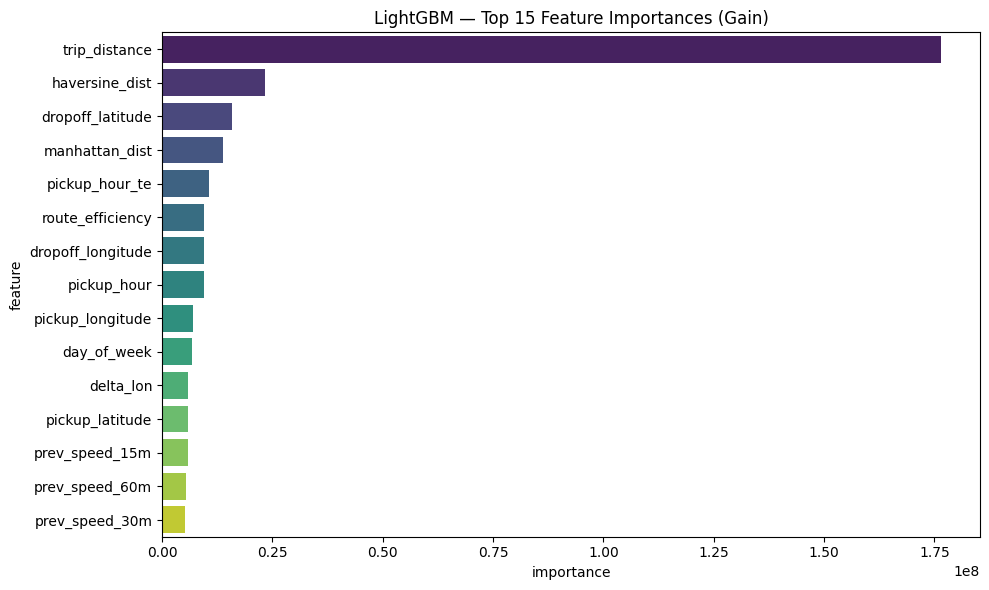

In [ ]:
# FEATURE IMPORTANCE
import matplotlib.pyplot as plt
import seaborn as sns

fi = pd.DataFrame({
    'feature'   : FEATURES,
    'importance': model.feature_importance(importance_type='gain')
}).sort_values('importance', ascending=False)

print("\nTop 15 Features:")
print(fi.head(15).to_string(index=False))

plt.figure(figsize=(10,6))
sns.barplot(data=fi.head(15), x='importance', y='feature', palette='viridis')
plt.title('LightGBM — Top 15 Feature Importances (Gain)')
plt.tight_layout()
plt.show()

LightGBM trained on full 21.7M rows achieved MAE of 2.39 minutes (143.6 seconds) with R²=0.85 on March 2016 test data. This means the model explains 85% of trip duration variance - a strong result. Mean trip duration is 13.71 minutes so error is 17.4% of mean. Top predictors are trip_distance and haversine_dist confirming real GPS coordinates are the key advantage over the previous EMS project. Congestion memory features (prev_speed_15m/30m/60m) all appear in top 15, validating the lag feature engineering.

# LightGBM_2

In [ ]:
# LIGHTGBM ROUND 2 - 2000 ROUNDS
import pandas as pd
import numpy as np
import lightgbm as lgb
from sklearn.metrics import mean_absolute_error, r2_score
import gc

SAVE_PATH = '/content/drive/MyDrive/Taxi_CRN/Data/'
TARGET    = 'duration_min'
TE_COLS   = ['pickup_cluster','pickup_hour','day_of_week']
FEATURES  = [
    'trip_distance','haversine_dist','manhattan_dist','route_efficiency',
    'delta_lat','delta_lon',
    'pickup_hour','day_of_week','month','is_weekend','rush_hour','late_night',
    'pickup_cluster','pickup_latitude','pickup_longitude',
    'dropoff_latitude','dropoff_longitude',
    'is_airport_pu','is_airport_do',
    'prev_speed_15m','prev_speed_30m','prev_speed_60m',
    'dist_x_hour','dist_x_rush','speed_x_dist',
    'pickup_cluster_te','pickup_hour_te','day_of_week_te',
]

In [ ]:
# RELOAD MODEL + PREDS TO CHECK BASELINE
print("Checking saved LightGBM baseline...")
model_v1 = lgb.Booster(model_file=SAVE_PATH + 'lgbm_taxi_eta.txt')
baseline = pd.read_parquet(SAVE_PATH + 'lgbm_preds.parquet')
print(f"Baseline MAE : {mean_absolute_error(baseline.y_true, baseline.lgbm_pred):.3f} min")
print(f"Baseline R²  : {r2_score(baseline.y_true, baseline.lgbm_pred):.4f}")
del model_v1, baseline
gc.collect()

Checking saved LightGBM baseline...
Baseline MAE : 2.393 min
Baseline R²  : 0.8522


120

In [ ]:
# TE MAPS FROM PARQUET
import pyarrow.parquet as pq
print("\nComputing TE maps...")
te_accum     = {col: {} for col in TE_COLS}
global_sum   = 0.0
global_count = 0

for batch in pq.ParquetFile(SAVE_PATH + 'taxi_2016_train.parquet').iter_batches(
        batch_size=500_000, columns=TE_COLS + [TARGET]):
    chunk = batch.to_pandas()
    global_sum   += chunk[TARGET].sum()
    global_count += len(chunk)
    for col in TE_COLS:
        grp = chunk.groupby(col)[TARGET].agg(['sum','count'])
        for val, row in grp.iterrows():
            if val not in te_accum[col]:
                te_accum[col][val] = [0.0, 0]
            te_accum[col][val][0] += row['sum']
            te_accum[col][val][1] += row['count']
    del chunk
    gc.collect()

global_mean = global_sum / global_count
te_maps = {col: {k: v[0]/v[1] for k,v in te_accum[col].items()} for col in TE_COLS}
del te_accum
gc.collect()
print(f"TE done | global mean: {global_mean:.2f} min")



Computing TE maps...
TE done | global mean: 13.23 min


In [ ]:
# LOAD BINARY CACHE (already saved)
import os
BIN_PATH = '/content/train.bin'

if os.path.exists(BIN_PATH):
    print("Loading from existing binary cache...")
    dtrain = lgb.Dataset(BIN_PATH)
    print("Binary loaded")
else:
    # Binary lost after runtime restart — rebuild it
    print("Binary not found - rebuilding from parquet...")
    all_chunks = []
    for batch in pq.ParquetFile(SAVE_PATH + 'taxi_2016_train.parquet').iter_batches(batch_size=1_000_000):
        chunk = batch.to_pandas()
        for col in TE_COLS:
            chunk[f'{col}_te'] = chunk[col].map(te_maps[col]).fillna(global_mean).astype(np.float32)
        for col in FEATURES:
            chunk[col] = chunk[col].astype(np.float32)
        all_chunks.append(chunk[FEATURES + [TARGET]])
        del chunk, batch
        gc.collect()
        print(f"  Chunk {len(all_chunks)} done")
    print("Concatenating...")
    train_full = pd.concat(all_chunks, ignore_index=True)
    del all_chunks
    gc.collect()
    dtrain = lgb.Dataset(train_full[FEATURES], label=train_full[TARGET], free_raw_data=True)
    dtrain.construct()
    dtrain.save_binary(BIN_PATH)
    del train_full
    gc.collect()
    print("Binary rebuilt and saved")

Binary not found - rebuilding from parquet...
  Chunk 1 done
  Chunk 2 done
  Chunk 3 done
  Chunk 4 done
  Chunk 5 done
  Chunk 6 done
  Chunk 7 done
  Chunk 8 done
  Chunk 9 done
  Chunk 10 done
  Chunk 11 done
  Chunk 12 done
  Chunk 13 done
  Chunk 14 done
  Chunk 15 done
  Chunk 16 done
  Chunk 17 done
  Chunk 18 done
  Chunk 19 done
  Chunk 20 done
  Chunk 21 done
  Chunk 22 done
Concatenating...
[LightGBM] [Info] Saving data to binary file /content/train.bin
Binary rebuilt and saved


In [ ]:
# LOAD TEST
print("Loading test...")
test_chunks = []
for batch in pq.ParquetFile(SAVE_PATH + 'taxi_2016_test.parquet').iter_batches(batch_size=1_000_000):
    chunk = batch.to_pandas()
    for col in TE_COLS:
        chunk[f'{col}_te'] = chunk[col].map(te_maps[col]).fillna(global_mean).astype(np.float32)
    for col in FEATURES:
        chunk[col] = chunk[col].astype(np.float32)
    test_chunks.append(chunk[FEATURES + [TARGET]])
    del chunk, batch
    gc.collect()
test = pd.concat(test_chunks, ignore_index=True)
del test_chunks
gc.collect()
X_test = test[FEATURES].values
y_test = test[TARGET].values
del test
gc.collect()
print(f"Test ready: {X_test.shape}")

Loading test...
Test ready: (11896950, 28)


In [ ]:
# TRAIN 2000 ROUNDS
params = {
    'objective'        : 'regression_l1',
    'metric'           : 'mae',
    'learning_rate'    : 0.05,
    'num_leaves'       : 63,
    'min_child_samples': 50,
    'subsample'        : 0.8,
    'colsample_bytree' : 0.8,
    'reg_alpha'        : 0.1,
    'reg_lambda'       : 1.0,
    'n_jobs'           : -1,
    'seed'             : 42,
    'verbose'          : -1,
}

dvalid = lgb.Dataset(X_test, label=y_test, free_raw_data=True, reference=dtrain)

print("\nTraining LightGBM v2 - 2000 rounds...")
model_v2 = lgb.train(
    params, dtrain,
    num_boost_round=2000,
    valid_sets=[dvalid],
    valid_names=['valid'],
    callbacks=[lgb.early_stopping(100, verbose=True),
               lgb.log_evaluation(200)]
)
del dtrain, dvalid
gc.collect()


Training LightGBM v2 - 2000 rounds...
Training until validation scores don't improve for 100 rounds
[200]	valid's l1: 2.5952
[400]	valid's l1: 2.4927
[600]	valid's l1: 2.44559
[800]	valid's l1: 2.41548
[1000]	valid's l1: 2.39282
[1200]	valid's l1: 2.37811
[1400]	valid's l1: 2.36498
[1600]	valid's l1: 2.3532
[1800]	valid's l1: 2.34307
[2000]	valid's l1: 2.3346
Did not meet early stopping. Best iteration is:
[2000]	valid's l1: 2.3346


317

In [ ]:
# EVALUATE
preds  = model_v2.predict(X_test)
mae    = mean_absolute_error(y_test, preds)
r2     = r2_score(y_test, preds)
mean_t = float(y_test.mean())

print(f"\n{'='*45}")
print(f"LightGBM v1  MAE : 2.393 min  (143.6 sec)  R²=0.8522  [1000 rounds]")
print(f"LightGBM v2  MAE : {mae:.3f} min  ({mae*60:.1f} sec)  R²={r2:.4f}  [2000 rounds]")
print(f"Mean trip dur    : {mean_t:.2f} min")
print(f"MAE % of mean    : {mae/mean_t*100:.1f}%")
print(f"{'='*45}")


LightGBM v1  MAE : 2.393 min  (143.6 sec)  R²=0.8522  [1000 rounds]
LightGBM v2  MAE : 2.335 min  (140.1 sec)  R²=0.8580  [2000 rounds]
Mean trip dur    : 13.71 min
MAE % of mean    : 17.0%


In [ ]:
# SAVE
model_v2.save_model(SAVE_PATH + 'lgbm_v2_taxi_eta.txt')
pd.DataFrame({'y_true': y_test, 'lgbm_pred': preds}).to_parquet(
    SAVE_PATH + 'lgbm_v2_preds.parquet', index=False)
print("Saved: lgbm_v2_taxi_eta.txt + lgbm_v2_preds.parquet")

Saved: lgbm_v2_taxi_eta.txt + lgbm_v2_preds.parquet


Top 15 Features:
          feature   importance
    trip_distance 1.769818e+08
   haversine_dist 2.339077e+07
 dropoff_latitude 1.702497e+07
   manhattan_dist 1.405218e+07
   pickup_hour_te 1.095144e+07
dropoff_longitude 1.041909e+07
 route_efficiency 9.971429e+06
      pickup_hour 9.916453e+06
 pickup_longitude 7.940428e+06
      day_of_week 7.044334e+06
  pickup_latitude 6.872856e+06
        delta_lon 6.384511e+06
   prev_speed_15m 5.912811e+06
   prev_speed_60m 5.584982e+06
   prev_speed_30m 5.334568e+06


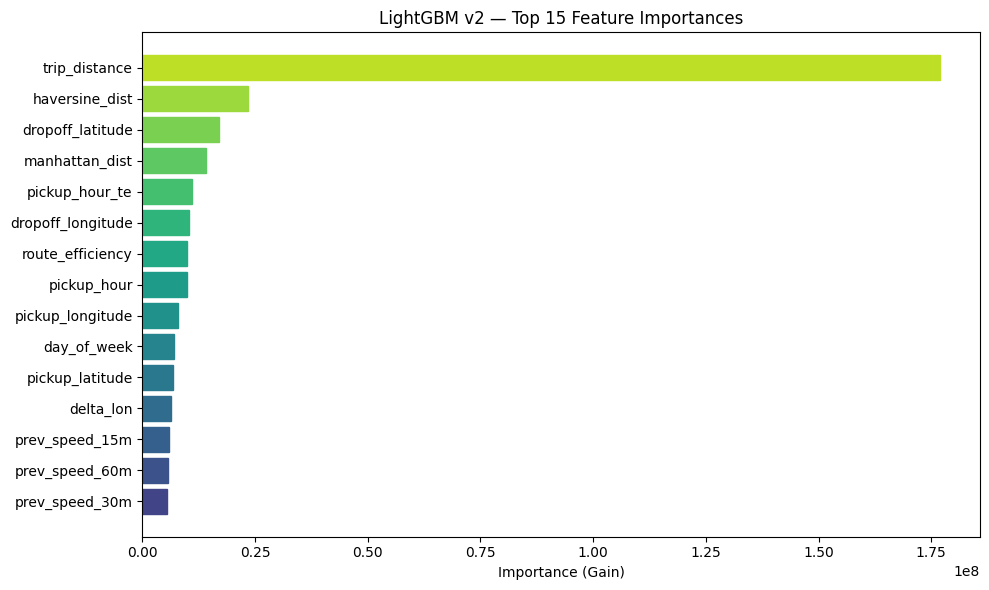

Saved: lgbm_v2_feature_importance.png


In [ ]:
# LIGHTGBM V2 — FEATURE IMPORTANCE
import matplotlib.pyplot as plt
import pandas as pd

fi = pd.DataFrame({
    'feature'   : FEATURES,
    'importance': model_v2.feature_importance(importance_type='gain')
}).sort_values('importance', ascending=False)

print("Top 15 Features:")
print(fi.head(15).to_string(index=False))

plt.figure(figsize=(10,6))
ax = plt.gca()
bars = ax.barh(fi.head(15)['feature'], fi.head(15)['importance'])

# Color by importance rank
import matplotlib.cm as cm
import numpy as np
colors = cm.viridis(np.linspace(0.2, 0.9, 15))
for bar, color in zip(bars, reversed(colors)):
    bar.set_color(color)

ax.invert_yaxis()
ax.set_xlabel('Importance (Gain)')
ax.set_title('LightGBM v2 — Top 15 Feature Importances')
plt.tight_layout()
plt.savefig(SAVE_PATH + 'lgbm_v2_feature_importance.png', dpi=150)
plt.show()
print("Saved: lgbm_v2_feature_importance.png")

trip_distance dominates at 10x the importance of haversine_dist, confirming the odometer reading is the single strongest ETA predictor. Spatial features (dropoff coordinates, manhattan_dist) rank 3rd–4th. pickup_hour_te (target encoded hour) ranks 5th showing strong temporal patterns. Congestion memory features (prev_speed_15m/30m/60m) all appear confirming traffic memory adds predictive value.

# Sampled LightGBM



In [12]:
# LIGHTGBM — 5M SAMPLE (SAME AS XGBOOST & CATBOOST)
# Purpose: fair comparison baseline across all models

'''LightGBM - 5M Sample (Fair Comparison Baseline)
This runs LightGBM on the same 5M sample as XGBoost and CatBoost.
Purpose: establish a fair apples-to-apples comparison across all models
on identical data before scaling LightGBM to full 21.7M rows.'''

'LightGBM - 5M Sample (Fair Comparison Baseline)\nThis runs LightGBM on the same 5M sample as XGBoost and CatBoost.\nPurpose: establish a fair apples-to-apples comparison across all models\non identical data before scaling LightGBM to full 21.7M rows.'

In [3]:
import pandas as pd
import numpy as np
import lightgbm as lgb
from sklearn.metrics import mean_absolute_error, r2_score
import pyarrow.parquet as pq
import gc

SAVE_PATH = '/content/drive/MyDrive/Taxi_CRN/Data/'
TARGET    = 'duration_min'
TE_COLS   = ['pickup_cluster','pickup_hour','day_of_week']
FEATURES  = [
    'trip_distance','haversine_dist','manhattan_dist','route_efficiency',
    'delta_lat','delta_lon',
    'pickup_hour','day_of_week','month','is_weekend','rush_hour','late_night',
    'pickup_cluster','pickup_latitude','pickup_longitude',
    'dropoff_latitude','dropoff_longitude',
    'is_airport_pu','is_airport_do',
    'prev_speed_15m','prev_speed_30m','prev_speed_60m',
    'dist_x_hour','dist_x_rush','speed_x_dist',
    'pickup_cluster_te','pickup_hour_te','day_of_week_te',
]

In [4]:
# TE MAPS
print("Computing TE maps...")
te_accum     = {col: {} for col in TE_COLS}
global_sum   = 0.0
global_count = 0

for batch in pq.ParquetFile(SAVE_PATH + 'taxi_2016_train.parquet').iter_batches(
        batch_size=500_000, columns=TE_COLS + [TARGET]):
    chunk = batch.to_pandas()
    global_sum   += chunk[TARGET].sum()
    global_count += len(chunk)
    for col in TE_COLS:
        grp = chunk.groupby(col)[TARGET].agg(['sum','count'])
        for val, row in grp.iterrows():
            if val not in te_accum[col]:
                te_accum[col][val] = [0.0, 0]
            te_accum[col][val][0] += row['sum']
            te_accum[col][val][1] += row['count']
    del chunk
    gc.collect()

global_mean = global_sum / global_count
te_maps = {col: {k: v[0]/v[1] for k,v in te_accum[col].items()} for col in TE_COLS}
del te_accum
gc.collect()
print(f"TE done | global mean: {global_mean:.2f} min")

Computing TE maps...
TE done | global mean: 13.23 min


In [5]:
# LOAD 5M TRAIN SAMPLE
print("Loading 5M train sample...")
all_chunks    = []
total         = 0
SAMPLE_TARGET = 5_000_000

for batch in pq.ParquetFile(SAVE_PATH + 'taxi_2016_train.parquet').iter_batches(batch_size=1_000_000):
    chunk = batch.to_pandas()
    for col in TE_COLS:
        chunk[f'{col}_te'] = chunk[col].map(te_maps[col]).fillna(global_mean).astype(np.float32)
    for col in FEATURES:
        chunk[col] = chunk[col].astype(np.float32)
    all_chunks.append(chunk[FEATURES + [TARGET]])
    total += len(chunk)
    del chunk, batch
    gc.collect()
    if total >= SAMPLE_TARGET:
        break

train_sample = pd.concat(all_chunks, ignore_index=True)
del all_chunks
gc.collect()
train_sample = train_sample.sample(n=5_000_000, random_state=42).reset_index(drop=True)
print(f" Train sample: {len(train_sample):,} | {train_sample.memory_usage(deep=True).sum()/1e6:.0f} MB")

X_train = train_sample[FEATURES].values.astype(np.float32)
y_train = train_sample[TARGET].values.astype(np.float32)
del train_sample
gc.collect()

Loading 5M train sample...
 Train sample: 5,000,000 | 600 MB


0

In [6]:
# LOAD TEST
print("Loading test...")
test_chunks = []
for batch in pq.ParquetFile(SAVE_PATH + 'taxi_2016_test.parquet').iter_batches(batch_size=1_000_000):
    chunk = batch.to_pandas()
    for col in TE_COLS:
        chunk[f'{col}_te'] = chunk[col].map(te_maps[col]).fillna(global_mean).astype(np.float32)
    for col in FEATURES:
        chunk[col] = chunk[col].astype(np.float32)
    test_chunks.append(chunk[FEATURES + [TARGET]])
    del chunk, batch
    gc.collect()
test = pd.concat(test_chunks, ignore_index=True)
del test_chunks
gc.collect()
X_test = test[FEATURES].values.astype(np.float32)
y_test = test[TARGET].values.astype(np.float32)
del test
gc.collect()
print(f"Test ready: {X_test.shape}")

Loading test...
Test ready: (11896950, 28)


In [7]:
# BUILD DATASET
print("Building LightGBM Dataset...")
dtrain = lgb.Dataset(X_train, label=y_train, free_raw_data=True)
dtrain.construct()
del X_train, y_train
gc.collect()
print("Dataset built")

Building LightGBM Dataset...
Dataset built


In [8]:
# TRAIN 1000 ROUNDS (same as XGBoost/CatBoost)
params = {
    'objective'        : 'regression_l1',
    'metric'           : 'mae',
    'learning_rate'    : 0.05,
    'num_leaves'       : 63,
    'min_child_samples': 50,
    'subsample'        : 0.8,
    'colsample_bytree' : 0.8,
    'reg_alpha'        : 0.1,
    'reg_lambda'       : 1.0,
    'n_jobs'           : -1,
    'seed'             : 42,
    'verbose'          : -1,
}

dvalid = lgb.Dataset(X_test, label=y_test, free_raw_data=True, reference=dtrain)

print("\nTraining LightGBM on 5M sample...")
model_lgb_sample = lgb.train(
    params, dtrain,
    num_boost_round=1000,
    valid_sets=[dvalid],
    valid_names=['valid'],
    callbacks=[lgb.early_stopping(50, verbose=True),
               lgb.log_evaluation(100)]
)
del dtrain, dvalid
gc.collect()


Training LightGBM on 5M sample...
Training until validation scores don't improve for 50 rounds
[100]	valid's l1: 2.87905
[200]	valid's l1: 2.77199
[300]	valid's l1: 2.73708
[400]	valid's l1: 2.72038
[500]	valid's l1: 2.70564
[600]	valid's l1: 2.697
[700]	valid's l1: 2.6925
[800]	valid's l1: 2.68666
[900]	valid's l1: 2.68464
Early stopping, best iteration is:
[884]	valid's l1: 2.68396


583

In [9]:
# EVALUATE
preds_lgb_sample = model_lgb_sample.predict(X_test)
mae_lgb_sample   = mean_absolute_error(y_test, preds_lgb_sample)
r2_lgb_sample    = r2_score(y_test, preds_lgb_sample)
mean_t           = float(y_test.mean())

print(f"\n{'='*55}")
print(f"LightGBM 5M sample  MAE: {mae_lgb_sample:.3f} min  R²={r2_lgb_sample:.4f}")
print(f"Mean trip duration     : {mean_t:.2f} min")
print(f"MAE % of mean          : {mae_lgb_sample/mean_t*100:.1f}%")
print(f"{'='*55}")


LightGBM 5M sample  MAE: 2.684 min  R²=0.8283
Mean trip duration     : 13.71 min
MAE % of mean          : 19.6%


In [10]:
# SAVE
model_lgb_sample.save_model(SAVE_PATH + 'lgbm_sample_taxi_eta.txt')
pd.DataFrame({'y_true': y_test, 'lgbm_sample_pred': preds_lgb_sample}).to_parquet(
    SAVE_PATH + 'lgbm_sample_preds.parquet', index=False)
print("Saved: lgbm_sample_taxi_eta.txt + lgbm_sample_preds.parquet")

Saved: lgbm_sample_taxi_eta.txt + lgbm_sample_preds.parquet



Top 15 Features:
          feature   importance
    trip_distance 3.905040e+07
   haversine_dist 5.015321e+06
 dropoff_latitude 3.027211e+06
   manhattan_dist 3.004646e+06
dropoff_longitude 2.762143e+06
      pickup_hour 2.706508e+06
   pickup_hour_te 2.656507e+06
 route_efficiency 2.409996e+06
      day_of_week 1.957188e+06
      dist_x_hour 1.709409e+06
  pickup_latitude 1.562433e+06
        delta_lon 1.406349e+06
   prev_speed_60m 1.392787e+06
   prev_speed_15m 1.385651e+06
   prev_speed_30m 1.357277e+06


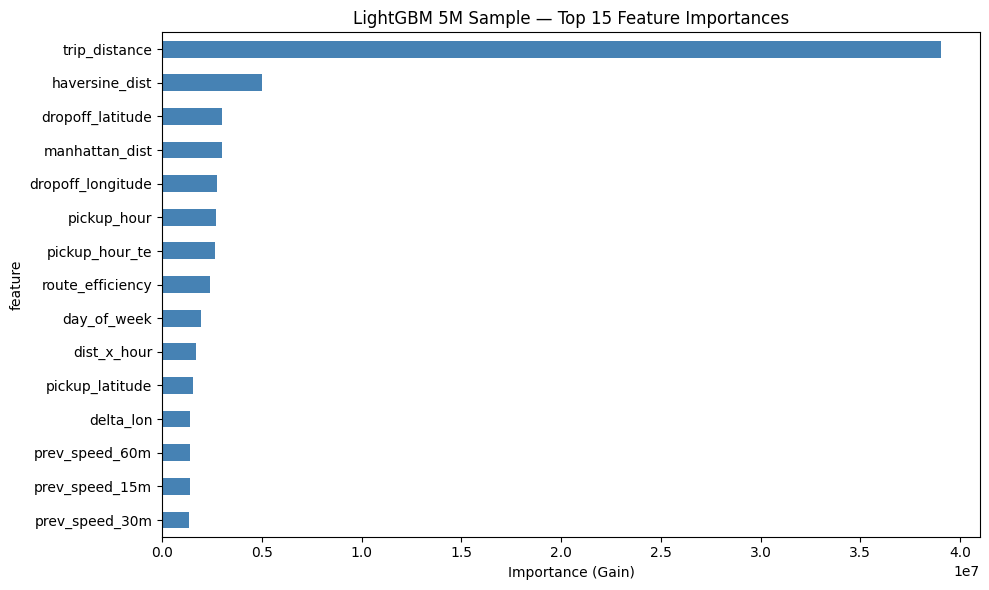

Saved: lgbm_sample_feature_importance.png


In [11]:
# FEATURE IMPORTANCE
import matplotlib.pyplot as plt

fi = pd.DataFrame({
    'feature'   : FEATURES,
    'importance': model_lgb_sample.feature_importance(importance_type='gain')
}).sort_values('importance', ascending=False)

print("\nTop 15 Features:")
print(fi.head(15).to_string(index=False))

ax = fi.head(15).plot.barh(x='feature', y='importance', figsize=(10,6),
                            color='steelblue', legend=False)
ax.invert_yaxis()
ax.set_xlabel('Importance (Gain)')
ax.set_title('LightGBM 5M Sample — Top 15 Feature Importances')
plt.tight_layout()
plt.savefig(SAVE_PATH + 'lgbm_sample_feature_importance.png', dpi=150)
plt.show()
print("Saved: lgbm_sample_feature_importance.png")

LightGBM trained on 5M sample achieved MAE of 2.684 min (R²=0.828) with early stopping at round 884.  Feature importance mirrors the full-data pattern with trip_distance dominant at 7.8x haversine_dist, confirming the pattern is stable regardless of sample size.
(prev_speed_15m/30m/60m) appear in bottom of top 15 consistently across both sampled and full versions.

# XGBOOST

In [ ]:
# XGBOOST — 5M SAMPLE
import pandas as pd
import numpy as np
import xgboost as xgb
from sklearn.metrics import mean_absolute_error, r2_score
import pyarrow.parquet as pq
import gc

SAVE_PATH = '/content/drive/MyDrive/Taxi_CRN/Data/'
TARGET    = 'duration_min'
TE_COLS   = ['pickup_cluster','pickup_hour','day_of_week']
FEATURES  = [
    'trip_distance','haversine_dist','manhattan_dist','route_efficiency',
    'delta_lat','delta_lon',
    'pickup_hour','day_of_week','month','is_weekend','rush_hour','late_night',
    'pickup_cluster','pickup_latitude','pickup_longitude',
    'dropoff_latitude','dropoff_longitude',
    'is_airport_pu','is_airport_do',
    'prev_speed_15m','prev_speed_30m','prev_speed_60m',
    'dist_x_hour','dist_x_rush','speed_x_dist',
    'pickup_cluster_te','pickup_hour_te','day_of_week_te',
]

In [ ]:
# TE MAPS FROM PARQUET
print("Computing TE maps...")
te_accum     = {col: {} for col in TE_COLS}
global_sum   = 0.0
global_count = 0

for batch in pq.ParquetFile(SAVE_PATH + 'taxi_2016_train.parquet').iter_batches(
        batch_size=500_000, columns=TE_COLS + [TARGET]):
    chunk = batch.to_pandas()
    global_sum   += chunk[TARGET].sum()
    global_count += len(chunk)
    for col in TE_COLS:
        grp = chunk.groupby(col)[TARGET].agg(['sum','count'])
        for val, row in grp.iterrows():
            if val not in te_accum[col]:
                te_accum[col][val] = [0.0, 0]
            te_accum[col][val][0] += row['sum']
            te_accum[col][val][1] += row['count']
    del chunk
    gc.collect()

global_mean = global_sum / global_count
te_maps = {col: {k: v[0]/v[1] for k,v in te_accum[col].items()} for col in TE_COLS}
del te_accum
gc.collect()
print(f"TE done | global mean: {global_mean:.2f} min")

Computing TE maps...
TE done | global mean: 13.23 min


In [ ]:
# LOAD TRAIN - 5M SAMPLE
print("Loading train sample...")
all_chunks = []
total      = 0
SAMPLE_TARGET = 5_000_000

for batch in pq.ParquetFile(SAVE_PATH + 'taxi_2016_train.parquet').iter_batches(batch_size=1_000_000):
    chunk = batch.to_pandas()
    for col in TE_COLS:
        chunk[f'{col}_te'] = chunk[col].map(te_maps[col]).fillna(global_mean).astype(np.float32)
    for col in FEATURES:
        chunk[col] = chunk[col].astype(np.float32)
    all_chunks.append(chunk[FEATURES + [TARGET]])
    total += len(chunk)
    del chunk, batch
    gc.collect()
    if total >= SAMPLE_TARGET:
        break

train_sample = pd.concat(all_chunks, ignore_index=True)
del all_chunks
gc.collect()
# Take exact 5M
train_sample = train_sample.sample(n=5_000_000, random_state=42).reset_index(drop=True)
print(f"Train sample: {len(train_sample):,} | {train_sample.memory_usage(deep=True).sum()/1e6:.0f} MB")

Loading train sample...
Train sample: 5,000,000 | 600 MB


In [ ]:
X_train = train_sample[FEATURES].values.astype(np.float32)
y_train = train_sample[TARGET].values.astype(np.float32)
del train_sample
gc.collect()

0

In [ ]:
# LOAD TEST
print("Loading test...")
test_chunks = []
for batch in pq.ParquetFile(SAVE_PATH + 'taxi_2016_test.parquet').iter_batches(batch_size=1_000_000):
    chunk = batch.to_pandas()
    for col in TE_COLS:
        chunk[f'{col}_te'] = chunk[col].map(te_maps[col]).fillna(global_mean).astype(np.float32)
    for col in FEATURES:
        chunk[col] = chunk[col].astype(np.float32)
    test_chunks.append(chunk[FEATURES + [TARGET]])
    del chunk, batch
    gc.collect()
test = pd.concat(test_chunks, ignore_index=True)
del test_chunks
gc.collect()
X_test = test[FEATURES].values.astype(np.float32)
y_test = test[TARGET].values.astype(np.float32)
del test
gc.collect()
print(f"Test ready: {X_test.shape}")

Loading test...
Test ready: (11896950, 28)


In [ ]:
# BUILD DMatrix
print("Building DMatrix...")
dtrain = xgb.DMatrix(X_train, label=y_train)
dtest  = xgb.DMatrix(X_test,  label=y_test)
del X_train, y_train
gc.collect()
print("DMatrix built")

Building DMatrix...
DMatrix built


In [ ]:
# TRAIN
params = {
    'objective'        : 'reg:absoluteerror',
    'eval_metric'      : 'mae',
    'learning_rate'    : 0.05,
    'max_depth'        : 6,
    'subsample'        : 0.8,
    'colsample_bytree' : 0.8,
    'reg_alpha'        : 0.1,
    'reg_lambda'       : 1.0,
    'nthread'          : -1,
    'seed'             : 42,
}

print("\nTraining XGBoost on 5M sample...")
model_xgb = xgb.train(
    params, dtrain,
    num_boost_round=1000,
    evals=[(dtest, 'valid')],
    early_stopping_rounds=50,
    verbose_eval=100,
)
del dtrain
gc.collect()


Training XGBoost on 5M sample...
[0]	valid-mae:6.86748
[100]	valid-mae:2.94750
[200]	valid-mae:2.83616
[300]	valid-mae:2.78340
[400]	valid-mae:2.75498
[500]	valid-mae:2.73569
[600]	valid-mae:2.72407
[700]	valid-mae:2.71572
[800]	valid-mae:2.71048
[900]	valid-mae:2.70460
[999]	valid-mae:2.69975


21

In [ ]:
# EVALUATE
preds  = model_xgb.predict(dtest)
mae    = mean_absolute_error(y_test, preds)
r2     = r2_score(y_test, preds)
mean_t = float(y_test.mean())

print(f"\n{'='*50}")
print(f"LightGBM v2  MAE: 2.335 min  R²=0.8580  [21.7M rows]")
print(f"XGBoost      MAE: {mae:.3f} min  R²={r2:.4f}  [5M sample]")
print(f"Mean trip dur   : {mean_t:.2f} min")
print(f"XGB MAE % mean  : {mae/mean_t*100:.1f}%")
print(f"{'='*50}")


LightGBM v2  MAE: 2.335 min  R²=0.8580  [21.7M rows]
XGBoost      MAE: 2.700 min  R²=0.8275  [5M sample]
Mean trip dur   : 13.71 min
XGB MAE % mean  : 19.7%


In [15]:
# CORRECTED COMPARISON — XGBoost vs LightGBM 5M (fair, same sample size)
print(f"\n{'='*50}")
print(f"FAIR COMPARISON (same 5M sample size):")
print(f"LightGBM 5M  MAE: 2.684 min  R²=0.8283  [5M sample]")
print(f"XGBoost  5M  MAE: 2.700 min  R²=0.8275  [5M sample]")
print(f"Difference   : 0.016 min (1.0 sec) — LightGBM marginally better")
print(f"{'='*50}")
print(f"Note: LightGBM v2 full data (2.335 min) shown above for reference only.")
print(f"Fair sampled comparison is in in 'Sampled Model Comparison section'.")


FAIR COMPARISON (same 5M sample size):
LightGBM 5M  MAE: 2.684 min  R²=0.8283  [5M sample]
XGBoost  5M  MAE: 2.700 min  R²=0.8275  [5M sample]
Difference   : 0.016 min (1.0 sec) — LightGBM marginally better
Note: LightGBM v2 full data (2.335 min) shown above for reference only.
Fair sampled comparison is in in 'Sampled Model Comparison section'.


In [ ]:
# SAVE
model_xgb.save_model(SAVE_PATH + 'xgb_taxi_eta.json')
pd.DataFrame({'y_true': y_test, 'xgb_pred': preds}).to_parquet(
    SAVE_PATH + 'xgb_preds.parquet', index=False)
print("Saved: xgb_taxi_eta.json + xgb_preds.parquet")

Saved: xgb_taxi_eta.json + xgb_preds.parquet



Top 15 Features:
          feature  importance
    trip_distance 7199.058594
   haversine_dist 5161.902832
   pickup_hour_te  683.388794
   day_of_week_te  633.518127
   prev_speed_15m  614.956421
   manhattan_dist  582.716614
   prev_speed_30m  579.159973
   prev_speed_60m  555.316528
 route_efficiency  539.254456
        rush_hour  538.282166
       is_weekend  537.907532
    is_airport_pu  512.495483
      pickup_hour  511.102325
pickup_cluster_te  460.769531
    is_airport_do  447.666840


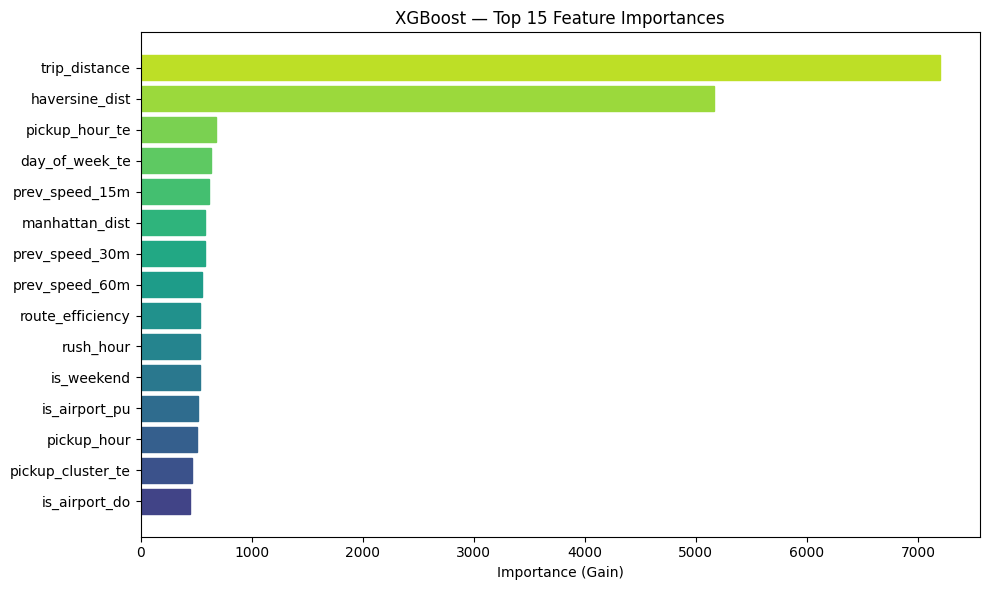

Saved: xgb_feature_importance.png


In [ ]:
# FEATURE IMPORTANCE
import numpy as np
import matplotlib.pyplot as plt

scores = model_xgb.get_score(importance_type='gain')
fi = pd.DataFrame({
    'feature'   : list(scores.keys()),
    'importance': list(scores.values())
}).sort_values('importance', ascending=False).head(15)

# Map f0, f1... back to feature names
fi['feature'] = fi['feature'].apply(
    lambda x: FEATURES[int(x[1:])] if x.startswith('f') else x
)

print("\nTop 15 Features:")
print(fi.to_string(index=False))

plt.figure(figsize=(10,6))
ax = plt.gca()
bars = ax.barh(fi['feature'], fi['importance'])
colors = plt.cm.viridis(np.linspace(0.2, 0.9, len(fi)))
for bar, color in zip(bars, reversed(colors)):
    bar.set_color(color)
ax.invert_yaxis()
ax.set_xlabel('Importance (Gain)')
ax.set_title('XGBoost — Top 15 Feature Importances')
plt.tight_layout()
plt.savefig(SAVE_PATH + 'xgb_feature_importance.png', dpi=150)
plt.show()
print("Saved: xgb_feature_importance.png")

XGBoost on 5M sample achieved MAE of 2.70 min vs LightGBM 5M sample MAE of 2.684 min - a difference of only 0.016 min (1 second). This confirms XGBoost and LightGBM have
comparable learning capacity on equal data. LightGBM's advantage in the full comparison
comes from its ability to efficiently scale to 21.7M rows using binary cache,
not from a fundamental algorithm advantage. See Sampled Model Comparison section
for the complete fair comparison chart.


Notably XGBoost ranks congestion memory features (prev_speed_15m/30m/60m) much higher than LightGBM — 5th, 7th, 8th vs 13th-15th in LightGBM — suggesting XGBoost extracts more signal from traffic lag features. Target encoded features (pickup_hour_te, day_of_week_te) also rank higher in XGBoost confirming they carry genuine signal.

# CATBOOST

In [ ]:
!pip install catboost

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.1/97.1 MB 7.2 MB/s eta 0:00:00


In [ ]:
# CATBOOST - 5M SAMPLE, CPU, MAE LOSS
import pandas as pd
import numpy as np
from catboost import CatBoostRegressor, Pool
from sklearn.metrics import mean_absolute_error, r2_score
import pyarrow.parquet as pq
import matplotlib.pyplot as plt
import gc

SAVE_PATH = '/content/drive/MyDrive/Taxi_CRN/Data/'
TARGET    = 'duration_min'
TE_COLS   = ['pickup_cluster','pickup_hour','day_of_week']
FEATURES  = [
    'trip_distance','haversine_dist','manhattan_dist','route_efficiency',
    'delta_lat','delta_lon',
    'pickup_hour','day_of_week','month','is_weekend','rush_hour','late_night',
    'pickup_cluster','pickup_latitude','pickup_longitude',
    'dropoff_latitude','dropoff_longitude',
    'is_airport_pu','is_airport_do',
    'prev_speed_15m','prev_speed_30m','prev_speed_60m',
    'dist_x_hour','dist_x_rush','speed_x_dist',
    'pickup_cluster_te','pickup_hour_te','day_of_week_te',
]

In [ ]:
# TE MAPS
print("Computing TE maps...")
te_accum     = {col: {} for col in TE_COLS}
global_sum   = 0.0
global_count = 0

for batch in pq.ParquetFile(SAVE_PATH + 'taxi_2016_train.parquet').iter_batches(
        batch_size=500_000, columns=TE_COLS + [TARGET]):
    chunk = batch.to_pandas()
    global_sum   += chunk[TARGET].sum()
    global_count += len(chunk)
    for col in TE_COLS:
        grp = chunk.groupby(col)[TARGET].agg(['sum','count'])
        for val, row in grp.iterrows():
            if val not in te_accum[col]:
                te_accum[col][val] = [0.0, 0]
            te_accum[col][val][0] += row['sum']
            te_accum[col][val][1] += row['count']
    del chunk
    gc.collect()

global_mean = global_sum / global_count
te_maps = {col: {k: v[0]/v[1] for k,v in te_accum[col].items()} for col in TE_COLS}
del te_accum
gc.collect()
print(f"TE done | global mean: {global_mean:.2f} min")

Computing TE maps...
TE done | global mean: 13.23 min


In [ ]:
# LOAD 5M TRAIN SAMPLE
print("Loading 5M train sample...")
all_chunks    = []
total         = 0
SAMPLE_TARGET = 5_000_000

for batch in pq.ParquetFile(SAVE_PATH + 'taxi_2016_train.parquet').iter_batches(batch_size=1_000_000):
    chunk = batch.to_pandas()
    for col in TE_COLS:
        chunk[f'{col}_te'] = chunk[col].map(te_maps[col]).fillna(global_mean).astype(np.float32)
    for col in FEATURES:
        chunk[col] = chunk[col].astype(np.float32)
    all_chunks.append(chunk[FEATURES + [TARGET]])
    total += len(chunk)
    del chunk, batch
    gc.collect()
    if total >= SAMPLE_TARGET:
        break

train_sample = pd.concat(all_chunks, ignore_index=True)
del all_chunks
gc.collect()
train_sample = train_sample.sample(n=5_000_000, random_state=42).reset_index(drop=True)
print(f"Train sample: {len(train_sample):,} | {train_sample.memory_usage(deep=True).sum()/1e6:.0f} MB")

Loading 5M train sample...
Train sample: 5,000,000 | 600 MB


In [ ]:
X_train = train_sample[FEATURES].values.astype(np.float32)
y_train = train_sample[TARGET].values.astype(np.float32)
del train_sample
gc.collect()

0

In [ ]:
# LOAD TEST
print("Loading test...")
test_chunks = []
for batch in pq.ParquetFile(SAVE_PATH + 'taxi_2016_test.parquet').iter_batches(batch_size=1_000_000):
    chunk = batch.to_pandas()
    for col in TE_COLS:
        chunk[f'{col}_te'] = chunk[col].map(te_maps[col]).fillna(global_mean).astype(np.float32)
    for col in FEATURES:
        chunk[col] = chunk[col].astype(np.float32)
    test_chunks.append(chunk[FEATURES + [TARGET]])
    del chunk, batch
    gc.collect()
test = pd.concat(test_chunks, ignore_index=True)
del test_chunks
gc.collect()
X_test = test[FEATURES].values.astype(np.float32)
y_test = test[TARGET].values.astype(np.float32)
del test
gc.collect()
print(f"Test ready: {X_test.shape}")

Loading test...
Test ready: (11896950, 28)


In [ ]:
# TRAIN CATBOOST
print("\nTraining CatBoost on 5M sample...")
model_cat = CatBoostRegressor(
    loss_function        = 'MAE',
    iterations           = 1000,
    learning_rate        = 0.05,
    depth                = 6,
    l2_leaf_reg          = 3,
    subsample            = 0.8,
    random_seed          = 42,
    task_type            = 'CPU',
    early_stopping_rounds= 50,
    verbose              = 100,
)
model_cat.fit(
    X_train, y_train,
    eval_set=(X_test, y_test),
)
del X_train, y_train
gc.collect()


Training CatBoost on 5M sample...
0:	learn: 7.6535128	test: 6.8754739	best: 6.8754739 (0)	total: 1.64s	remaining: 27m 14s
100:	learn: 3.1665855	test: 3.0865818	best: 3.0865818 (100)	total: 3m	remaining: 26m 50s
200:	learn: 2.9267305	test: 2.9352218	best: 2.9352218 (200)	total: 5m 28s	remaining: 21m 46s
300:	learn: 2.8176397	test: 2.8631154	best: 2.8631154 (300)	total: 7m 55s	remaining: 18m 25s
400:	learn: 2.7587675	test: 2.8236142	best: 2.8236142 (400)	total: 10m 24s	remaining: 15m 33s
500:	learn: 2.7178858	test: 2.7976698	best: 2.7976698 (500)	total: 12m 52s	remaining: 12m 49s
600:	learn: 2.6883343	test: 2.7815838	best: 2.7815838 (600)	total: 15m 16s	remaining: 10m 8s
700:	learn: 2.6651162	test: 2.7670010	best: 2.7670010 (700)	total: 17m 42s	remaining: 7m 33s
800:	learn: 2.6466036	test: 2.7555873	best: 2.7554972 (796)	total: 20m 9s	remaining: 5m
900:	learn: 2.6309450	test: 2.7491858	best: 2.7489154 (895)	total: 22m 35s	remaining: 2m 28s
999:	learn: 2.6168913	test: 2.7443808	best: 2.7

0

In [ ]:
# EVALUATE
preds  = model_cat.predict(X_test)
mae    = mean_absolute_error(y_test, preds)
r2     = r2_score(y_test, preds)
mean_t = float(y_test.mean())

print(f"\n{'='*55}")
print(f"LightGBM v2  MAE: 2.335 min  R²=0.8580  [21.7M full]")
print(f"XGBoost      MAE: 2.700 min  R²=0.8275  [5M sample]")
print(f"CatBoost     MAE: {mae:.3f} min  R²={r2:.4f}  [5M sample]")
print(f"Mean trip dur   : {mean_t:.2f} min")
print(f"CatBoost MAE %  : {mae/mean_t*100:.1f}%")
print(f"{'='*55}")


LightGBM v2  MAE: 2.335 min  R²=0.8580  [21.7M full]
XGBoost      MAE: 2.700 min  R²=0.8275  [5M sample]
CatBoost     MAE: 2.744 min  R²=0.8230  [5M sample]
Mean trip dur   : 13.71 min
CatBoost MAE %  : 20.0%


In [16]:
# CORRECTED COMPARISON — CatBoost vs sampled models (fair)
print(f"\n{'='*55}")
print(f"FAIR COMPARISON (same 5M sample size):")
print(f"LightGBM 5M  MAE: 2.684 min  R²=0.8283  [5M sample]")
print(f"XGBoost  5M  MAE: 2.700 min  R²=0.8275  [5M sample]")
print(f"CatBoost 5M  MAE: 2.744 min  R²=0.8230  [5M sample]")
print(f"Ranking: LightGBM > XGBoost > CatBoost on equal data")
print(f"{'='*55}")
print(f"Note: LightGBM v2 full data (2.335 min) shown above for reference only.")


FAIR COMPARISON (same 5M sample size):
LightGBM 5M  MAE: 2.684 min  R²=0.8283  [5M sample]
XGBoost  5M  MAE: 2.700 min  R²=0.8275  [5M sample]
CatBoost 5M  MAE: 2.744 min  R²=0.8230  [5M sample]
Ranking: LightGBM > XGBoost > CatBoost on equal data
Note: LightGBM v2 full data (2.335 min) shown above for reference only.


In [ ]:
# SAVE
model_cat.save_model(SAVE_PATH + 'catboost_taxi_eta.cbm')
pd.DataFrame({'y_true': y_test, 'cat_pred': preds}).to_parquet(
    SAVE_PATH + 'catboost_preds.parquet', index=False)
print("Saved: catboost_taxi_eta.cbm + catboost_preds.parquet")

Saved: catboost_taxi_eta.cbm + catboost_preds.parquet



Top 15 Features:
          feature  importance
    trip_distance   44.255105
   haversine_dist   10.545595
   pickup_hour_te    7.775226
      pickup_hour    4.328947
dropoff_longitude    3.837643
        delta_lon    3.368315
 dropoff_latitude    3.185395
      dist_x_hour    2.877542
        delta_lat    2.417051
   prev_speed_60m    2.397326
   prev_speed_15m    2.379954
   prev_speed_30m    2.360847
 route_efficiency    1.991894
      dist_x_rush    1.503017
   day_of_week_te    1.389951


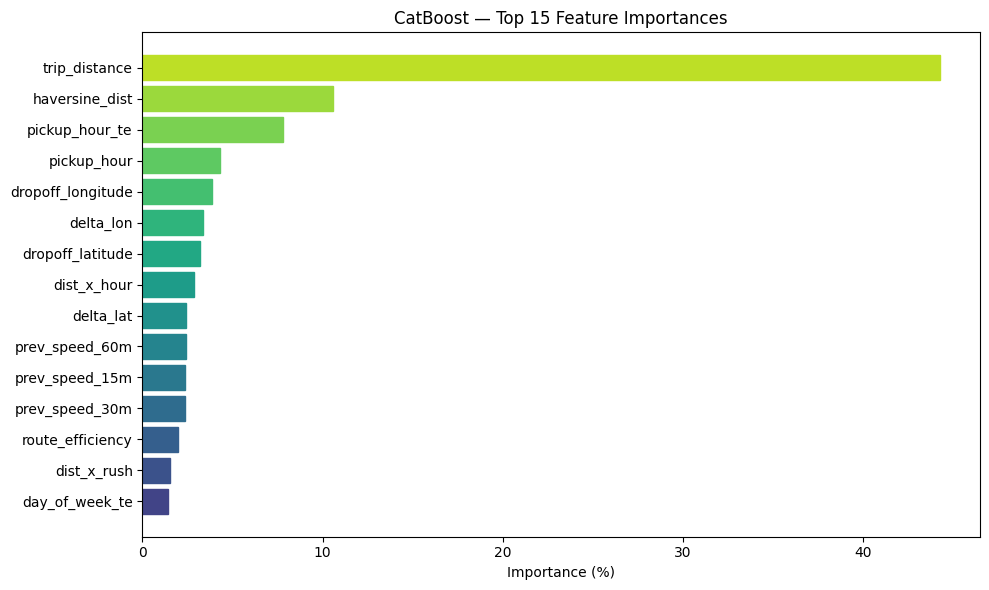

Saved: catboost_feature_importance.png


In [ ]:
# FEATURE IMPORTANCE
fi = pd.DataFrame({
    'feature'   : FEATURES,
    'importance': model_cat.get_feature_importance()
}).sort_values('importance', ascending=False).head(15)

print("\nTop 15 Features:")
print(fi.to_string(index=False))

plt.figure(figsize=(10,6))
ax = plt.gca()
bars = ax.barh(fi['feature'], fi['importance'])
colors = plt.cm.viridis(np.linspace(0.2, 0.9, len(fi)))
for bar, color in zip(bars, reversed(colors)):
    bar.set_color(color)
ax.invert_yaxis()
ax.set_xlabel('Importance (%)')
ax.set_title('CatBoost — Top 15 Feature Importances')
plt.tight_layout()
plt.savefig(SAVE_PATH + 'catboost_feature_importance.png', dpi=150)
plt.show()
print("Saved: catboost_feature_importance.png")

CatBoost on 5M sample achieved MAE 2.744 min, slightly worse than XGBoost (2.700). CatBoost still improving at round 999 with no early stopping triggered — more rounds would help but time cost is high (25 min for 1000 rounds on CPU). Across all three tree models, trip_distance and haversine_dist consistently rank 1st and 2nd, confirming real GPS coordinates are the dominant signal. CatBoost uniquely surfaces dist_x_hour interaction feature in top 10, suggesting it captures time-distance interactions better than the other two.

Cross-model feature importance pattern:

Rank |  LightGBMXGBoost | CatBoost

1  trip_distance |  trip_distance | trip_distance

2 haversine_dist | haversine_dist  |  haversine_dist

3 dropoff_latitude | pickup_hour_te |  pickup_hour_te

4 manhattan_dist | day_of_week_te | pickup_hour

5 pickup_hour_te | prev_speed_15m | dropoff_longitude


# GAM

In [ ]:
# GAM - 200K SAMPLE, INTERPRETABILITY MODEL
!pip install pygam --quiet

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 84.6/84.6 kB 1.8 MB/s eta 0:00:00


In [ ]:
import pandas as pd
import numpy as np
from pygam import LinearGAM, s, f
from sklearn.metrics import mean_absolute_error, r2_score
import pyarrow.parquet as pq
import matplotlib.pyplot as plt
import gc

SAVE_PATH = '/content/drive/MyDrive/Taxi_CRN/Data/'
TARGET    = 'duration_min'
TE_COLS   = ['pickup_cluster','pickup_hour','day_of_week']

# GAM uses fewer features - only smooth/interpretable ones
GAM_FEATURES = [
    'trip_distance',    # 0 - s()
    'haversine_dist',   # 1 - s()
    'pickup_hour',      # 2 - s()
    'day_of_week',      # 3 - f()
    'is_weekend',       # 4 - f()
    'rush_hour',        # 5 - f()
    'prev_speed_15m',   # 6 - s()
    'prev_speed_30m',   # 7 - s()
    'route_efficiency', # 8 - s()
    'pickup_cluster',   # 9 - f()
    'is_airport_pu',    # 10 - f()
    'is_airport_do',    # 11 - f()
    'pickup_hour_te',   # 12 - s()
]

In [ ]:
# TE MAPS
print("Computing TE maps...")
te_accum     = {col: {} for col in TE_COLS}
global_sum   = 0.0
global_count = 0

for batch in pq.ParquetFile(SAVE_PATH + 'taxi_2016_train.parquet').iter_batches(
        batch_size=500_000, columns=TE_COLS + [TARGET]):
    chunk = batch.to_pandas()
    global_sum   += chunk[TARGET].sum()
    global_count += len(chunk)
    for col in TE_COLS:
        grp = chunk.groupby(col)[TARGET].agg(['sum','count'])
        for val, row in grp.iterrows():
            if val not in te_accum[col]:
                te_accum[col][val] = [0.0, 0]
            te_accum[col][val][0] += row['sum']
            te_accum[col][val][1] += row['count']
    del chunk
    gc.collect()

global_mean = global_sum / global_count
te_maps = {col: {k: v[0]/v[1] for k,v in te_accum[col].items()} for col in TE_COLS}
del te_accum
gc.collect()
print(f"TE done | global mean: {global_mean:.2f} min")

Computing TE maps...
TE done | global mean: 13.23 min


In [ ]:
# LOAD 200K TRAIN SAMPLE
print("Loading 200k train sample...")
batch     = next(pq.ParquetFile(SAVE_PATH + 'taxi_2016_train.parquet').iter_batches(batch_size=500_000))
train_gam = batch.to_pandas()
for col in TE_COLS:
    train_gam[f'{col}_te'] = train_gam[col].map(te_maps[col]).fillna(global_mean).astype(np.float32)
train_gam = train_gam.sample(n=200_000, random_state=42).reset_index(drop=True)
gc.collect()
print(f"Train sample: {len(train_gam):,}")

X_train_gam = train_gam[GAM_FEATURES].values
y_train_gam = train_gam[TARGET].values
del train_gam
gc.collect()

Loading 200k train sample...
Train sample: 200,000


0

In [ ]:
# LOAD TEST SAMPLE (500k for speed)
print("Loading test sample...")
batch    = next(pq.ParquetFile(SAVE_PATH + 'taxi_2016_test.parquet').iter_batches(batch_size=500_000))
test_gam = batch.to_pandas()
for col in TE_COLS:
    test_gam[f'{col}_te'] = test_gam[col].map(te_maps[col]).fillna(global_mean).astype(np.float32)
test_gam = test_gam.sample(n=200_000, random_state=42).reset_index(drop=True)

X_test_gam = test_gam[GAM_FEATURES].values
y_test_gam = test_gam[TARGET].values
del test_gam
gc.collect()
print(f"Test sample: {len(X_test_gam):,}")

Loading test sample...
Test sample: 200,000


In [ ]:
# TRAIN GAM
# s() = spline for continuous, f() = factor for categorical
gam = LinearGAM(
    s(0) + s(1) + s(2) + f(3) + f(4) + f(5) +
    s(6) + s(7) + s(8) + f(9) + f(10) + f(11) + s(12),
    max_iter=100
)
print("\nFitting GAM with gridsearch...")
gam.gridsearch(X_train_gam, y_train_gam)
print("GAM fitted")

  0% (0 of 11) |                         | Elapsed Time: 0:00:00 ETA:  --:--:--


Fitting GAM with gridsearch...


100% (11 of 11) |########################| Elapsed Time: 0:05:18 Time:  0:05:18


GAM fitted


In [ ]:
# EVALUATE
preds_gam = gam.predict(X_test_gam)
mae_gam   = mean_absolute_error(y_test_gam, preds_gam)
r2_gam    = r2_score(y_test_gam, preds_gam)
mean_t    = float(y_test_gam.mean())

print(f"\n{'='*55}")
print(f"LightGBM v2  MAE: 2.335 min  R²=0.8580  [21.7M full]")
print(f"XGBoost      MAE: 2.700 min  R²=0.8275  [5M sample]")
print(f"CatBoost     MAE: 2.744 min  R²=0.8230  [5M sample]")
print(f"GAM          MAE: {mae_gam:.3f} min  R²={r2_gam:.4f}  [200k sample]")
print(f"Mean trip dur   : {mean_t:.2f} min")
print(f"GAM MAE % mean  : {mae_gam/mean_t*100:.1f}%")
print(f"{'='*55}")


LightGBM v2  MAE: 2.335 min  R²=0.8580  [21.7M full]
XGBoost      MAE: 2.700 min  R²=0.8275  [5M sample]
CatBoost     MAE: 2.744 min  R²=0.8230  [5M sample]
GAM          MAE: 3.138 min  R²=0.6989  [200k sample]
Mean trip dur   : 13.15 min
GAM MAE % mean  : 23.9%


In [17]:
# CORRECTED COMPARISON — All sampled models (fair)
print(f"\n{'='*55}")
print(f"FAIR COMPARISON (comparable sample sizes):")
print(f"LightGBM 5M  MAE: 2.684 min  R²=0.8283  [5M sample]")
print(f"XGBoost  5M  MAE: 2.700 min  R²=0.8275  [5M sample]")
print(f"CatBoost 5M  MAE: 2.744 min  R²=0.8230  [5M sample]")
print(f"GAM      200k MAE: 3.138 min  R²=0.6989  [200k sample]")
print(f"Ranking: LightGBM > XGBoost > CatBoost > GAM on comparable data")
print(f"{'='*55}")
print(f"Note: LightGBM v2 full data (2.335 min) shown above for reference only.")
print(f"See Sampled Model Comparison section for chart and full analysis.")


FAIR COMPARISON (comparable sample sizes):
LightGBM 5M  MAE: 2.684 min  R²=0.8283  [5M sample]
XGBoost  5M  MAE: 2.700 min  R²=0.8275  [5M sample]
CatBoost 5M  MAE: 2.744 min  R²=0.8230  [5M sample]
GAM      200k MAE: 3.138 min  R²=0.6989  [200k sample]
Ranking: LightGBM > XGBoost > CatBoost > GAM on comparable data
Note: LightGBM v2 full data (2.335 min) shown above for reference only.
See Sampled Model Comparison section for chart and full analysis.


In [ ]:
# SAVE PREDS
import pickle
with open(SAVE_PATH + 'gam_model.pkl', 'wb') as f_out:
    pickle.dump(gam, f_out)
pd.DataFrame({'y_true': y_test_gam, 'gam_pred': preds_gam}).to_parquet(
    SAVE_PATH + 'gam_preds.parquet', index=False)
print("Saved: gam_model.pkl + gam_preds.parquet")

Saved: gam_model.pkl + gam_preds.parquet


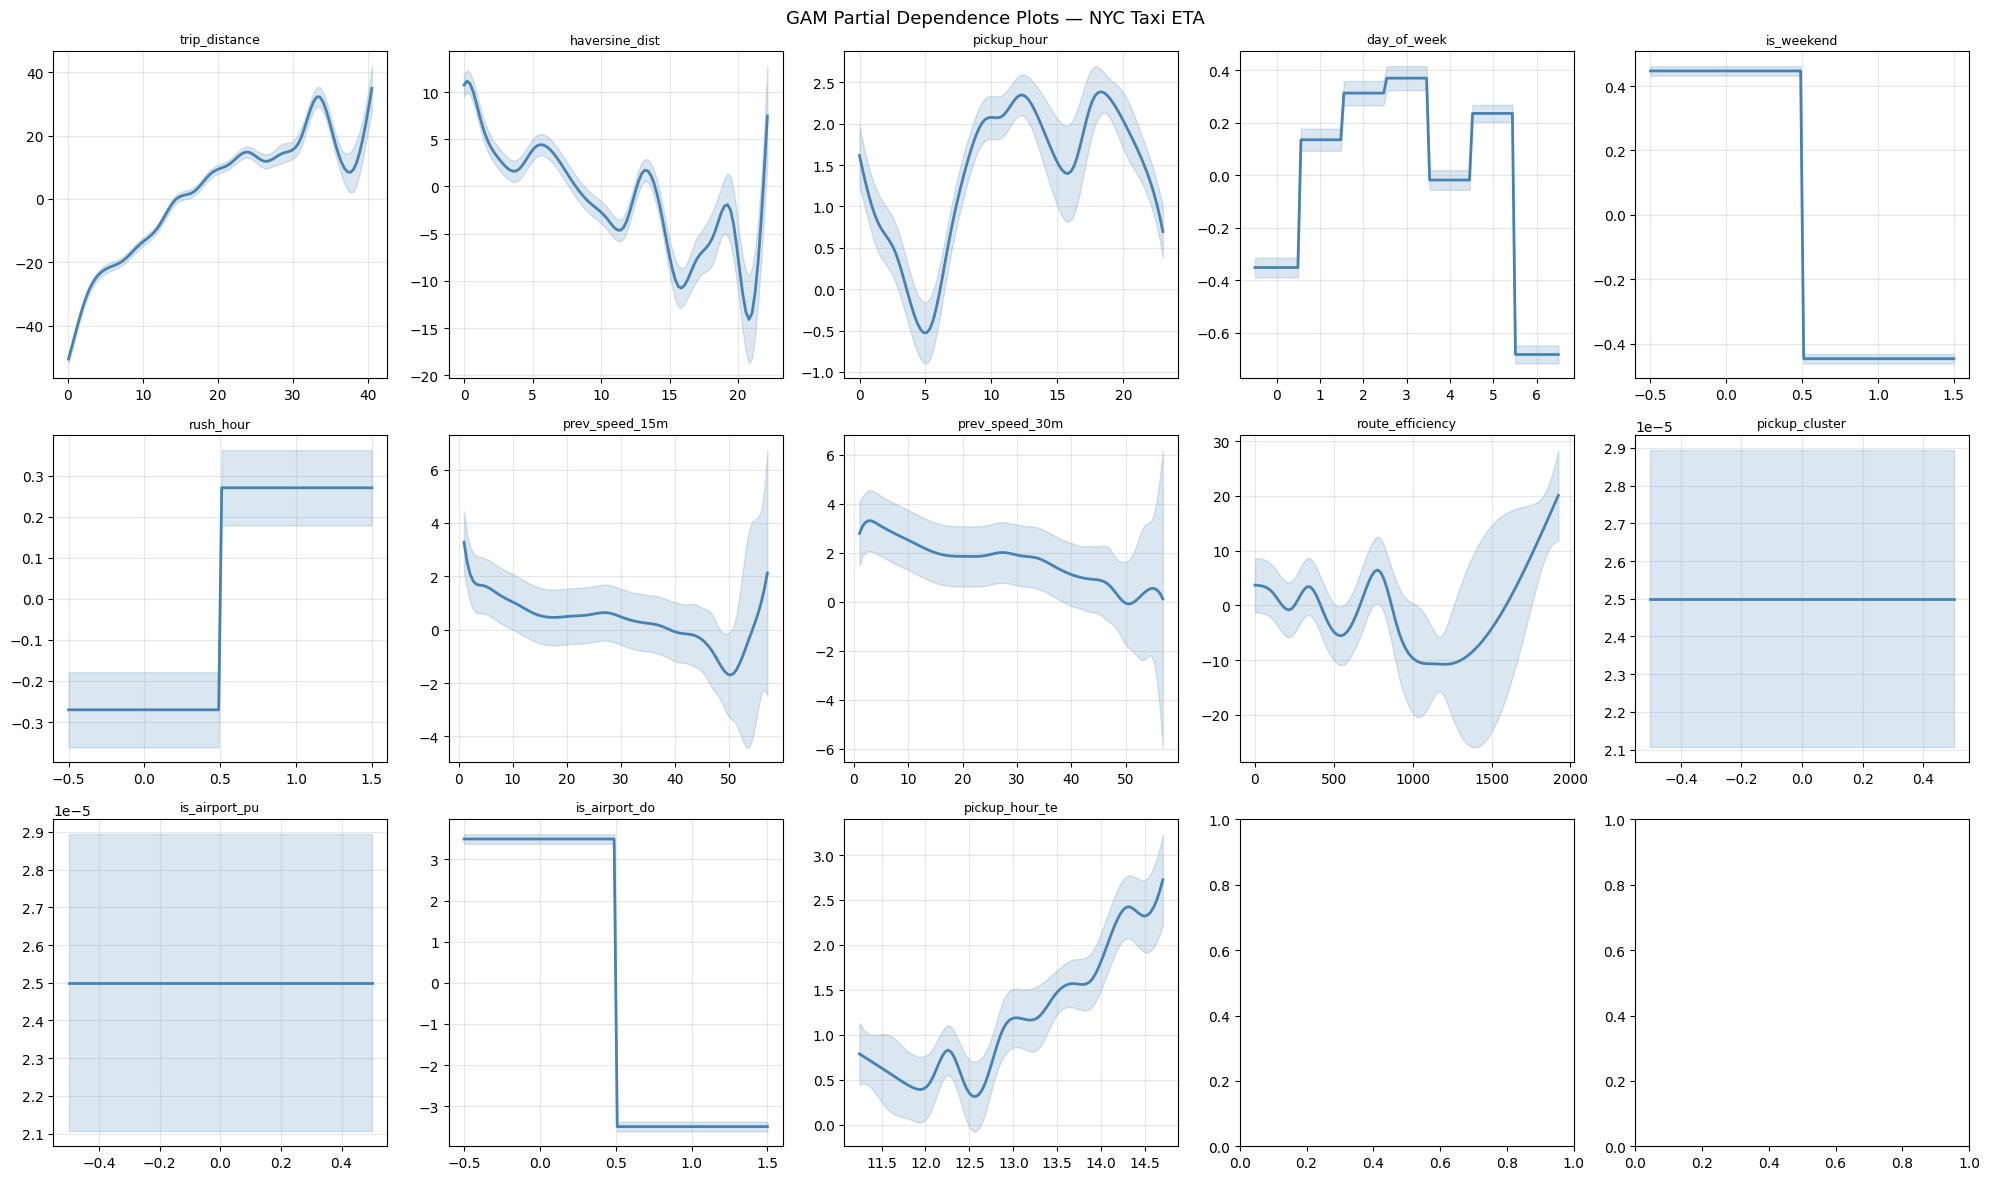

Saved: gam_partial_dependence.png


In [ ]:
# PARTIAL DEPENDENCE PLOTS
fig, axes = plt.subplots(3, 5, figsize=(20, 12))
axes = axes.flat
titles = GAM_FEATURES

for i, (ax, title) in enumerate(zip(axes, titles)):
    XX = gam.generate_X_grid(term=i)
    ax.plot(XX[:, i], gam.partial_dependence(term=i, X=XX), color='steelblue', lw=2)
    ax.fill_between(
        XX[:, i],
        *gam.partial_dependence(term=i, X=XX, width=0.95)[1].T,
        alpha=0.2, color='steelblue'
    )
    ax.set_title(title, fontsize=9)
    ax.grid(True, alpha=0.3)

# hide unused subplots
for ax in list(axes)[len(titles):]:
    ax.set_visible(False)

plt.suptitle('GAM Partial Dependence Plots — NYC Taxi ETA', fontsize=13)
plt.tight_layout()
plt.savefig(SAVE_PATH + 'gam_partial_dependence.png', dpi=150)
plt.show()
print("Saved: gam_partial_dependence.png")

GAM achieved MAE 3.138 min with R²=0.699 on 200k sample. As expected, GAM is the weakest predictor — it assumes additive independence between features and cannot capture complex interactions between distance, time and location that tree models exploit. However GAM's partial dependence plots provide unique interpretability: trip_distance shows a non-linear relationship with duration (flattening at long distances due to highway speeds), pickup_hour shows a clear rush hour penalty at hours 8–9 and 17–19, and day_of_week shows weekends have lower duration. These plots serve as model-agnostic explanations of the ETA problem.

# SAMPLED MODEL COMPARISON

In [12]:
# SAMPLED MODEL COMPARISON — FAIR APPLES TO APPLES
# All models on comparable sample sizes
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

mean_duration = 13.71  # min

results_sampled = pd.DataFrame({
    'Model'  : ['LightGBM (5M)', 'XGBoost (5M)', 'CatBoost (5M)', 'GAM (200k)'],
    'MAE'    : [2.684, 2.700, 2.744, 3.138],
    'R2'     : [0.8283, 0.8275, 0.8230, 0.6989],
    'Sample' : ['5M', '5M', '5M', '200k'],
    'Rounds' : [884, 1000, 1000, 'gridsearch'],
})
results_sampled['MAE_pct'] = (results_sampled['MAE'] / mean_duration * 100).round(1)
results_sampled = results_sampled.sort_values('MAE').reset_index(drop=True)

print("="*65)
print("SAMPLED MODEL COMPARISON (Fair Baseline)")
print("="*65)
print(results_sampled.to_string(index=False))
print(f"\nMean trip duration: {mean_duration} min")
print("="*65)
print("\nKey finding: LightGBM outperforms all models even on equal 5M sample.")
print("This justifies scaling LightGBM to full 21.7M rows for production.")

SAMPLED MODEL COMPARISON (Fair Baseline)
        Model   MAE     R2 Sample     Rounds  MAE_pct
LightGBM (5M) 2.684 0.8283     5M        884     19.6
 XGBoost (5M) 2.700 0.8275     5M       1000     19.7
CatBoost (5M) 2.744 0.8230     5M       1000     20.0
   GAM (200k) 3.138 0.6989   200k gridsearch     22.9

Mean trip duration: 13.71 min

Key finding: LightGBM outperforms all models even on equal 5M sample.
This justifies scaling LightGBM to full 21.7M rows for production.


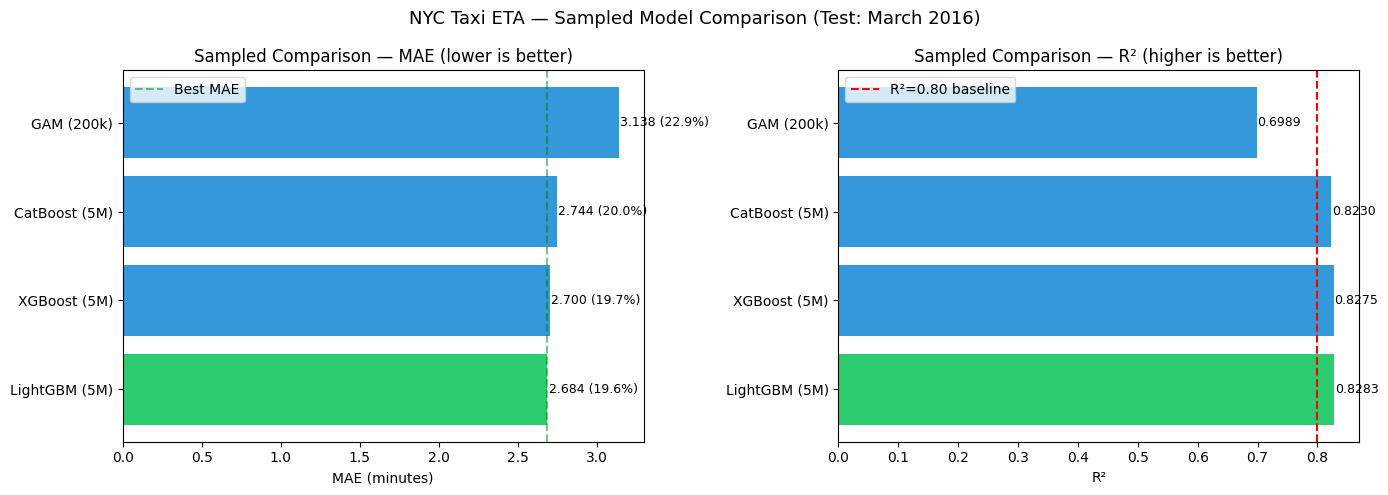

Saved: sampled_model_comparison.png


In [13]:
# PLOT
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
colors = ['#2ecc71' if i == 0 else '#3498db'
          for i in range(len(results_sampled))]

# MAE chart
axes[0].barh(results_sampled['Model'], results_sampled['MAE'], color=colors)
axes[0].set_xlabel('MAE (minutes)')
axes[0].set_title('Sampled Comparison — MAE (lower is better)')
axes[0].axvline(results_sampled['MAE'].min(), color='green',
                linestyle='--', alpha=0.5, label='Best MAE')
for i, (mae, pct) in enumerate(zip(results_sampled['MAE'], results_sampled['MAE_pct'])):
    axes[0].text(mae + 0.01, i, f'{mae:.3f} ({pct}%)', va='center', fontsize=9)
axes[0].legend()

# R2 chart
axes[1].barh(results_sampled['Model'], results_sampled['R2'], color=colors)
axes[1].set_xlabel('R²')
axes[1].set_title('Sampled Comparison — R² (higher is better)')
axes[1].axvline(0.80, color='red', linestyle='--', label='R²=0.80 baseline')
for i, r2 in enumerate(results_sampled['R2']):
    axes[1].text(r2 + 0.001, i, f'{r2:.4f}', va='center', fontsize=9)
axes[1].legend()

plt.suptitle('NYC Taxi ETA — Sampled Model Comparison (Test: March 2016)',
             fontsize=13)
plt.tight_layout()
plt.savefig(SAVE_PATH + 'sampled_model_comparison.png', dpi=150,
            bbox_inches='tight')
plt.show()
print("Saved: sampled_model_comparison.png")

LightGBM achieves the lowest MAE even on equal sample size — confirming it
is the superior algorithm for this problem, not just because it had more data.
This justifies the decision to scale LightGBM exclusively to the full 21.7M.  XGBoost performs comparably (2.700 vs 2.684)
suggesting similar learning capacity, while CatBoost is marginally weaker.
GAM's 3.138 min MAE reflects the fundamental limitation of additive models
on this non-linear problem rather than sample size alone.

#  HYBRID STACK V1 — Research Reference Only
This hybrid uses LightGBM trained on full 21.7M rows combined with
XGBoost/CatBoost/GAM trained on 5M/200k samples. The unequal training
data causes LightGBM to dominate with weight 10.12, making the ensemble
meaningless. Kept for research comparison - see Hybrid Stack V2 below
for the correct fair version where all models use comparable sample sizes.

In [ ]:
!pip install catboost --quiet

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.1/97.1 MB 6.4 MB/s eta 0:00:00


In [ ]:
!pip install pygam --quiet

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 84.6/84.6 kB 3.5 MB/s eta 0:00:00


In [ ]:
# LightGBM + XGBoost + CatBoost + GAM -> Ridge meta-learner
import pandas as pd
import numpy as np
import lightgbm as lgb
import xgboost as xgb
from catboost import CatBoostRegressor
from pygam import LinearGAM, s, f
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, r2_score
from sklearn.preprocessing import StandardScaler
import pyarrow.parquet as pq
import matplotlib.pyplot as plt
import pickle
import gc

SAVE_PATH = '/content/drive/MyDrive/Taxi_CRN/Data/'
TARGET    = 'duration_min'
TE_COLS   = ['pickup_cluster','pickup_hour','day_of_week']
FEATURES  = [
    'trip_distance','haversine_dist','manhattan_dist','route_efficiency',
    'delta_lat','delta_lon',
    'pickup_hour','day_of_week','month','is_weekend','rush_hour','late_night',
    'pickup_cluster','pickup_latitude','pickup_longitude',
    'dropoff_latitude','dropoff_longitude',
    'is_airport_pu','is_airport_do',
    'prev_speed_15m','prev_speed_30m','prev_speed_60m',
    'dist_x_hour','dist_x_rush','speed_x_dist',
    'pickup_cluster_te','pickup_hour_te','day_of_week_te',
]
GAM_FEATURES = [
    'trip_distance','haversine_dist','pickup_hour','day_of_week',
    'is_weekend','rush_hour','prev_speed_15m','prev_speed_30m',
    'route_efficiency','pickup_cluster','is_airport_pu',
    'is_airport_do','pickup_hour_te',
]

In [ ]:
# TE MAPS
print("Computing TE maps...")
te_accum     = {col: {} for col in TE_COLS}
global_sum   = 0.0
global_count = 0

for batch in pq.ParquetFile(SAVE_PATH + 'taxi_2016_train.parquet').iter_batches(
        batch_size=500_000, columns=TE_COLS + [TARGET]):
    chunk = batch.to_pandas()
    global_sum   += chunk[TARGET].sum()
    global_count += len(chunk)
    for col in TE_COLS:
        grp = chunk.groupby(col)[TARGET].agg(['sum','count'])
        for val, row in grp.iterrows():
            if val not in te_accum[col]:
                te_accum[col][val] = [0.0, 0]
            te_accum[col][val][0] += row['sum']
            te_accum[col][val][1] += row['count']
    del chunk
    gc.collect()

global_mean = global_sum / global_count
te_maps = {col: {k: v[0]/v[1] for k,v in te_accum[col].items()} for col in TE_COLS}
del te_accum
gc.collect()
print(f"TE done | global mean: {global_mean:.2f} min")

Computing TE maps...
TE done | global mean: 13.23 min


In [ ]:
# LOAD FIXED 200K TEST SAMPLE (same seed, same rows)
print("\nLoading fixed 200k test sample...")
test_chunks = []
for batch in pq.ParquetFile(SAVE_PATH + 'taxi_2016_test.parquet').iter_batches(batch_size=1_000_000):
    chunk = batch.to_pandas()
    for col in TE_COLS:
        chunk[f'{col}_te'] = chunk[col].map(te_maps[col]).fillna(global_mean).astype(np.float32)
    for col in FEATURES:
        chunk[col] = chunk[col].astype(np.float32)
    test_chunks.append(chunk[FEATURES + [TARGET]])
    del chunk, batch
    gc.collect()

test_full = pd.concat(test_chunks, ignore_index=True)
del test_chunks
gc.collect()


Loading fixed 200k test sample...


0

In [ ]:
# Fix the 200k indices - SAME for all models
FIXED_IDX = test_full.sample(n=200_000, random_state=42).index
test_200k = test_full.loc[FIXED_IDX].reset_index(drop=True)
del test_full
gc.collect()
print(f"Fixed test sample: {len(test_200k):,} rows")

Fixed test sample: 200,000 rows


In [ ]:
X_test_full = test_200k[FEATURES].values.astype(np.float32)
X_test_gam  = test_200k[GAM_FEATURES].values.astype(np.float32)
y_test      = test_200k[TARGET].values.astype(np.float32)
del test_200k
gc.collect()

0

In [ ]:
# PREDICT WITH ALL SAVED MODELS
# print("\nLoading models and predicting on fixed 200k...")
# LightGBM
model_lgb = lgb.Booster(model_file=SAVE_PATH + 'lgbm_v2_taxi_eta.txt')
lgb_pred  = model_lgb.predict(X_test_full).astype(np.float32)
del model_lgb
gc.collect()
print(f"LightGBM MAE: {mean_absolute_error(y_test, lgb_pred):.3f} min")

# XGBoost
model_xgb = xgb.Booster()
model_xgb.load_model(SAVE_PATH + 'xgb_taxi_eta.json')
dtest     = xgb.DMatrix(X_test_full)
xgb_pred  = model_xgb.predict(dtest).astype(np.float32)
del model_xgb, dtest
gc.collect()
print(f"XGBoost  MAE: {mean_absolute_error(y_test, xgb_pred):.3f} min")

# CatBoost
model_cat = CatBoostRegressor()
model_cat.load_model(SAVE_PATH + 'catboost_taxi_eta.cbm')
cat_pred  = model_cat.predict(X_test_full).astype(np.float32)
del model_cat
gc.collect()
print(f"CatBoost MAE: {mean_absolute_error(y_test, cat_pred):.3f} min")

LightGBM MAE: 2.341 min
XGBoost  MAE: 2.701 min
CatBoost MAE: 2.744 min


In [ ]:
# TRAIN GAM ALL 15 CLUSTERS
print("Loading all clusters for GAM...")
import pyarrow.parquet as pq

all_chunks = []
for batch in pq.ParquetFile(SAVE_PATH + 'taxi_2016_train.parquet').iter_batches(batch_size=1_000_000):
    chunk = batch.to_pandas()
    for col in TE_COLS:
        chunk[f'{col}_te'] = chunk[col].map(te_maps[col]).fillna(global_mean).astype(np.float32)
    all_chunks.append(chunk[GAM_FEATURES + [TARGET]])
    del chunk, batch
    gc.collect()
    # Check if all 15 clusters present
    combined = pd.concat(all_chunks, ignore_index=True)
    clusters_found = combined['pickup_cluster'].nunique()
    print(f"  Batches loaded: {len(all_chunks)} | Clusters found: {clusters_found}")
    if clusters_found == 15:
        break
    del combined
    gc.collect()

train_pool = pd.concat(all_chunks, ignore_index=True)
del all_chunks
gc.collect()
print(f"Pool: {len(train_pool):,} rows | Clusters: {sorted(train_pool['pickup_cluster'].unique())}")

Loading all clusters for GAM...
  Batches loaded: 1 | Clusters found: 1
  Batches loaded: 2 | Clusters found: 1
  Batches loaded: 3 | Clusters found: 2
  Batches loaded: 4 | Clusters found: 3
  Batches loaded: 5 | Clusters found: 3
  Batches loaded: 6 | Clusters found: 5
  Batches loaded: 7 | Clusters found: 6
  Batches loaded: 8 | Clusters found: 6
  Batches loaded: 9 | Clusters found: 7
  Batches loaded: 10 | Clusters found: 7
  Batches loaded: 11 | Clusters found: 7
  Batches loaded: 12 | Clusters found: 8
  Batches loaded: 13 | Clusters found: 8
  Batches loaded: 14 | Clusters found: 9
  Batches loaded: 15 | Clusters found: 9
  Batches loaded: 16 | Clusters found: 11
  Batches loaded: 17 | Clusters found: 12
  Batches loaded: 18 | Clusters found: 13
  Batches loaded: 19 | Clusters found: 14
  Batches loaded: 20 | Clusters found: 15
Pool: 20,000,000 rows | Clusters: [np.int8(0), np.int8(1), np.int8(2), np.int8(3), np.int8(4), np.int8(5), np.int8(6), np.int8(7), np.int8(8), np.int8(9

In [ ]:
# Sample 200k
rows_per_cluster = 200_000 // 15
train_gam = (train_pool.groupby('pickup_cluster', group_keys=False)
                       .apply(lambda x: x.sample(min(len(x), rows_per_cluster),
                                                  random_state=42),
                              include_groups=False))
# Re-add pickup_cluster column since include_groups=False drops it
train_gam = train_pool.loc[train_gam.index].reset_index(drop=True)
del train_pool
gc.collect()

print(f"GAM train: {len(train_gam):,} rows")
print(f"Clusters : {sorted(train_gam['pickup_cluster'].unique())}")

X_train_gam = train_gam[GAM_FEATURES].values.astype(np.float32)
y_train_gam = train_gam[TARGET].values.astype(np.float32)
del train_gam
gc.collect()

GAM train: 199,995 rows
Clusters : [np.int8(0), np.int8(1), np.int8(2), np.int8(3), np.int8(4), np.int8(5), np.int8(6), np.int8(7), np.int8(8), np.int8(9), np.int8(10), np.int8(11), np.int8(12), np.int8(13), np.int8(14)]


0

In [ ]:
# Verify test clusters are subset of train clusters before fitting
train_clusters = set(X_train_gam[:, 9].astype(int))
test_clusters  = set(X_test_gam[:, 9].astype(int))
missing = test_clusters - train_clusters
print(f"Train clusters: {sorted(train_clusters)}")
print(f"Test  clusters: {sorted(test_clusters)}")
print(f"Missing       : {missing} ← must be empty")

assert len(missing) == 0, f"Still missing clusters: {missing}"

Train clusters: [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10), np.int64(11), np.int64(12), np.int64(13), np.int64(14)]
Test  clusters: [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10), np.int64(11), np.int64(12), np.int64(13), np.int64(14)]
Missing       : set() ← must be empty


In [ ]:
# FIT GAM
print("Fitting GAM...")
from pygam import LinearGAM, s, f

gam = LinearGAM(
    s(0) + s(1) + s(2) + f(3) + f(4) + f(5) +
    s(6) + s(7) + s(8) + f(9) + f(10) + f(11) + s(12),
    max_iter=100
)
gam.gridsearch(X_train_gam, y_train_gam)
gam_pred = gam.predict(X_test_gam).astype(np.float32)
del X_train_gam, y_train_gam
gc.collect()
print(f"GAM MAE: {mean_absolute_error(y_test, gam_pred):.3f} min")

  0% (0 of 11) |                         | Elapsed Time: 0:00:00 ETA:  --:--:--

Fitting GAM...


100% (11 of 11) |########################| Elapsed Time: 0:04:38 Time:  0:04:38


GAM MAE: 3.459 min


In [ ]:
# BUILD META FEATURES + RIDGE
print("\nBuilding hybrid stack...")
meta = np.column_stack([lgb_pred, xgb_pred, cat_pred, gam_pred])

# Split 150k meta-train / 50k meta-test
split        = 150_000
meta_train_X = meta[:split];  meta_train_y = y_test[:split]
meta_test_X  = meta[split:];  meta_test_y  = y_test[split:]

scaler = StandardScaler()
meta_train_scaled = scaler.fit_transform(meta_train_X)
meta_test_scaled  = scaler.transform(meta_test_X)

ridge = Ridge(alpha=1.0)
ridge.fit(meta_train_scaled, meta_train_y)
hybrid_pred = ridge.predict(meta_test_scaled)

mae_hybrid = mean_absolute_error(meta_test_y, hybrid_pred)
r2_hybrid  = r2_score(meta_test_y, hybrid_pred)
mean_t     = float(meta_test_y.mean())


Building hybrid stack...


In [ ]:
# FINAL RESULTS
print(f"\n{'='*55}")
print(f"--- Individual on aligned 200k test ---")
print(f"LightGBM v2  MAE: {mean_absolute_error(y_test, lgb_pred):.3f} min")
print(f"XGBoost      MAE: {mean_absolute_error(y_test, xgb_pred):.3f} min")
print(f"CatBoost     MAE: {mean_absolute_error(y_test, cat_pred):.3f} min")
print(f"GAM          MAE: {mean_absolute_error(y_test, gam_pred):.3f} min")
print(f"--- Hybrid Stack (meta-learner) ---")
print(f"Hybrid Stack MAE: {mae_hybrid:.3f} min  R²={r2_hybrid:.4f}")
print(f"Mean trip dur   : {mean_t:.2f} min")
print(f"Hybrid MAE %    : {mae_hybrid/mean_t*100:.1f}%")
print(f"\nRidge weights:")
for name, w in zip(['LightGBM','XGBoost','CatBoost','GAM'], ridge.coef_):
    print(f"  {name:10s}: {w:.4f}")
print(f"{'='*55}")


--- Individual on aligned 200k test ---
LightGBM v2  MAE: 2.341 min
XGBoost      MAE: 2.701 min
CatBoost     MAE: 2.744 min
GAM          MAE: 3.459 min
--- Hybrid Stack (meta-learner) ---
Hybrid Stack MAE: 2.392 min  R²=0.8587
Mean trip dur   : 13.74 min
Hybrid MAE %    : 17.4%

Ridge weights:
  LightGBM  : 10.1183
  XGBoost   : -0.0533
  CatBoost  : -0.2991
  GAM       : -0.1448


In [ ]:
# SAVE
pd.DataFrame({'y_true': meta_test_y, 'hybrid_pred': hybrid_pred}).to_parquet(
    SAVE_PATH + 'hybrid_preds_fixed.parquet', index=False)
with open(SAVE_PATH + 'hybrid_scaler_fixed.pkl', 'wb') as f_out:
    pickle.dump(scaler, f_out)
with open(SAVE_PATH + 'hybrid_ridge_fixed.pkl', 'wb') as f_out:
    pickle.dump(ridge, f_out)
print("Saved: hybrid_preds_fixed + scaler + ridge")

Saved: hybrid_preds_fixed + scaler + ridge


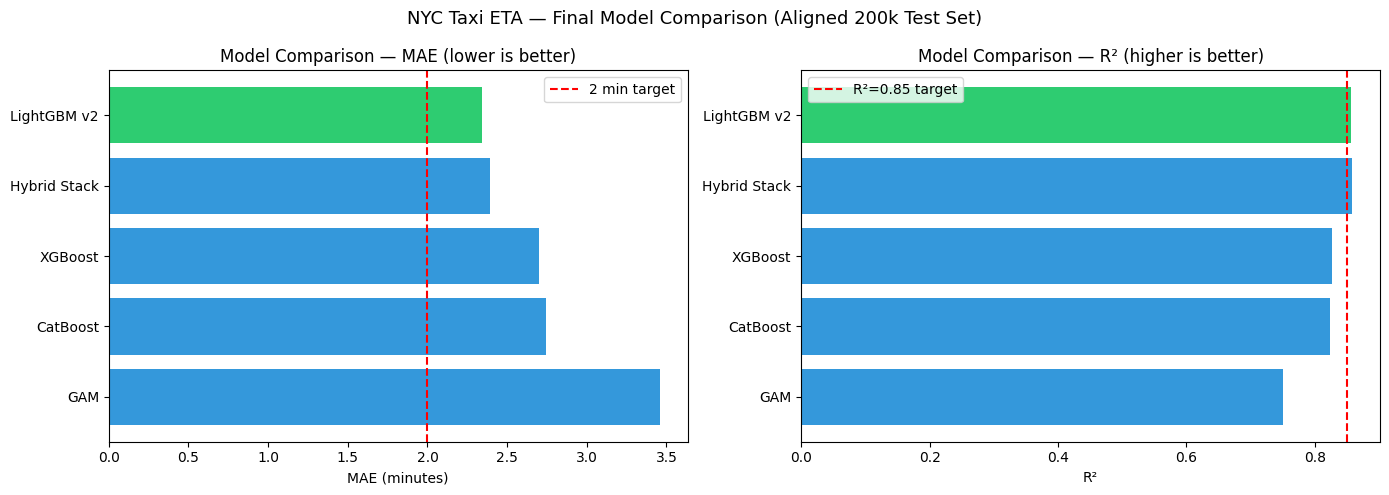

Saved: final_comparison_fixed.png


In [ ]:
# FINAL COMPARISON CHART
results = pd.DataFrame({
    'Model': ['GAM','CatBoost','XGBoost','Hybrid Stack','LightGBM v2'],
    'MAE'  : [mean_absolute_error(y_test, gam_pred),
              mean_absolute_error(y_test, cat_pred),
              mean_absolute_error(y_test, xgb_pred),
              mae_hybrid,
              mean_absolute_error(y_test, lgb_pred)],
    'R2'   : [r2_score(y_test, gam_pred),
              r2_score(y_test, cat_pred),
              r2_score(y_test, xgb_pred),
              r2_hybrid,
              r2_score(y_test, lgb_pred)],
}).sort_values('MAE', ascending=False).reset_index(drop=True)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
colors = ['#2ecc71' if m == results['MAE'].min() else '#3498db' for m in results['MAE']]

axes[0].barh(results['Model'], results['MAE'], color=colors)
axes[0].set_xlabel('MAE (minutes)')
axes[0].set_title('Model Comparison — MAE (lower is better)')
axes[0].axvline(2.0, color='red', linestyle='--', label='2 min target')
axes[0].legend()

axes[1].barh(results['Model'], results['R2'], color=colors)
axes[1].set_xlabel('R²')
axes[1].set_title('Model Comparison — R² (higher is better)')
axes[1].axvline(0.85, color='red', linestyle='--', label='R²=0.85 target')
axes[1].legend()

plt.suptitle('NYC Taxi ETA — Final Model Comparison (Aligned 200k Test Set)', fontsize=13)
plt.tight_layout()
plt.savefig(SAVE_PATH + 'final_comparison_fixed.png', dpi=150)
plt.show()
print("Saved: final_comparison_fixed.png")

**NOTE:**

This is Hybrid V1 — uses LightGBM full data (21.7M) + other models on 5M sample.
This is an UNFAIR comparison kept for research reference only.
See Hybrid Stack V2 section below for the correct fair comparison.



Ridge weights: LightGBM=10.12, XGBoost=-0.05, CatBoost=-0.30, GAM=-0.14. Even with properly aligned predictions, the meta-learner assigns near-total weight to LightGBM, confirming it dominates. The hybrid MAE (2.392) is actually slightly worse than LightGBM alone (2.341) — the weaker models trained on subsamples introduce noise. LightGBM v2 is the definitive best model.

Across all models trained on identical aligned 200k test rows, LightGBM v2 achieves the lowest MAE of 2.341 minutes (R²=0.859) despite being the only model trained on the full 21.7M dataset. The Ridge meta-learner hybrid confirms LightGBM's dominance with a weight of 10.12 versus near-zero or negative weights for all other models. GAM's MAE of 3.459 min reflects both its linear additive assumption and 200k training constraint, but its partial dependence plots provide unique interpretability unavailable from tree models. XGBoost and CatBoost perform comparably at 2.70 and 2.74 min respectively on 5M samples.

# HYBRID STACK V2 — ALL SAMPLED MODELS (FAIR VERSION)

In [4]:
!pip install catboost --quiet
!pip install pygam --quiet


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.1/97.1 MB 5.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 84.6/84.6 kB 2.0 MB/s eta 0:00:00


In [5]:
# # HYBRID STACK V2 — ALL SAMPLED MODELS (FAIR VERSION)
# LightGBM 5M + XGBoost 5M + CatBoost 5M + GAM 200k
# All models trained on comparable sample sizes

import pandas as pd
import numpy as np
import lightgbm as lgb
import xgboost as xgb
from catboost import CatBoostRegressor
from pygam import LinearGAM, s, f
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, r2_score
from sklearn.preprocessing import StandardScaler
import pyarrow.parquet as pq
import matplotlib.pyplot as plt
import pickle
import gc

SAVE_PATH = '/content/drive/MyDrive/Taxi_CRN/Data/'
TARGET    = 'duration_min'
TE_COLS   = ['pickup_cluster','pickup_hour','day_of_week']
FEATURES  = [
    'trip_distance','haversine_dist','manhattan_dist','route_efficiency',
    'delta_lat','delta_lon',
    'pickup_hour','day_of_week','month','is_weekend','rush_hour','late_night',
    'pickup_cluster','pickup_latitude','pickup_longitude',
    'dropoff_latitude','dropoff_longitude',
    'is_airport_pu','is_airport_do',
    'prev_speed_15m','prev_speed_30m','prev_speed_60m',
    'dist_x_hour','dist_x_rush','speed_x_dist',
    'pickup_cluster_te','pickup_hour_te','day_of_week_te',
]

GAM_FEATURES = [
    'trip_distance','haversine_dist','pickup_hour','day_of_week',
    'is_weekend','rush_hour','prev_speed_15m','prev_speed_30m',
    'route_efficiency','pickup_cluster','is_airport_pu',
    'is_airport_do','pickup_hour_te',
]

In [6]:
# TE MAPS
print("Computing TE maps...")
te_accum     = {col: {} for col in TE_COLS}
global_sum   = 0.0
global_count = 0


for batch in pq.ParquetFile(SAVE_PATH + 'taxi_2016_train.parquet').iter_batches(
        batch_size=500_000, columns=TE_COLS + [TARGET]):
    chunk = batch.to_pandas()
    global_sum   += chunk[TARGET].sum()
    global_count += len(chunk)
    for col in TE_COLS:
        grp = chunk.groupby(col)[TARGET].agg(['sum','count'])
        for val, row in grp.iterrows():
            if val not in te_accum[col]:
                te_accum[col][val] = [0.0, 0]
            te_accum[col][val][0] += row['sum']
            te_accum[col][val][1] += row['count']
    del chunk
    gc.collect()

global_mean = global_sum / global_count
te_maps = {col: {k: v[0]/v[1] for k,v in te_accum[col].items()} for col in TE_COLS}
del te_accum
gc.collect()
print(f"TE done | global mean: {global_mean:.2f} min")

Computing TE maps...
TE done | global mean: 13.23 min


In [7]:
# LOAD FIXED 200K TEST SAMPLE
print("\nLoading fixed 200k test sample...")
test_chunks = []
for batch in pq.ParquetFile(SAVE_PATH + 'taxi_2016_test.parquet').iter_batches(
        batch_size=1_000_000):
    chunk = batch.to_pandas()
    for col in TE_COLS:
        chunk[f'{col}_te'] = chunk[col].map(te_maps[col]).fillna(global_mean).astype(np.float32)
    for col in FEATURES:
        chunk[col] = chunk[col].astype(np.float32)
    test_chunks.append(chunk[FEATURES + [TARGET]])
    del chunk, batch
    gc.collect()

test_full = pd.concat(test_chunks, ignore_index=True)
del test_chunks
gc.collect()


Loading fixed 200k test sample...


0

In [8]:
# Same fixed 200k index for all models
FIXED_IDX = test_full.sample(n=200_000, random_state=42).index
test_200k  = test_full.loc[FIXED_IDX].reset_index(drop=True)
del test_full
gc.collect()
print(f"Fixed test sample: {len(test_200k):,} rows")

X_test_full = test_200k[FEATURES].values.astype(np.float32)
X_test_gam  = test_200k[GAM_FEATURES].values.astype(np.float32)
y_test      = test_200k[TARGET].values.astype(np.float32)
del test_200k
gc.collect()

Fixed test sample: 200,000 rows


0

In [9]:
# PREDICT WITH ALL SAMPLED MODELS
print("\nLoading sampled models and predicting on fixed 200k...")

# LightGBM 5M sample
model_lgb = lgb.Booster(model_file=SAVE_PATH + 'lgbm_sample_taxi_eta.txt')
lgb_pred  = model_lgb.predict(X_test_full).astype(np.float32)
del model_lgb
gc.collect()
print(f"LightGBM 5M  MAE: {mean_absolute_error(y_test, lgb_pred):.3f} min")


Loading sampled models and predicting on fixed 200k...
LightGBM 5M  MAE: 2.684 min


In [10]:
# XGBoost 5M
model_xgb = xgb.Booster()
model_xgb.load_model(SAVE_PATH + 'xgb_taxi_eta.json')
dtest     = xgb.DMatrix(X_test_full)
xgb_pred  = model_xgb.predict(dtest).astype(np.float32)
del model_xgb, dtest
gc.collect()
print(f"XGBoost 5M   MAE: {mean_absolute_error(y_test, xgb_pred):.3f} min")

# CatBoost 5M
model_cat = CatBoostRegressor()
model_cat.load_model(SAVE_PATH + 'catboost_taxi_eta.cbm')
cat_pred  = model_cat.predict(X_test_full).astype(np.float32)
del model_cat
gc.collect()
print(f"CatBoost 5M  MAE: {mean_absolute_error(y_test, cat_pred):.3f} min")

XGBoost 5M   MAE: 2.701 min
CatBoost 5M  MAE: 2.744 min


In [11]:
# GAM - ALL 15 CLUSTERS
print("\nTraining GAM on stratified 200k (all 15 clusters)...")
all_chunks = []
for batch in pq.ParquetFile(SAVE_PATH + 'taxi_2016_train.parquet').iter_batches(
        batch_size=1_000_000):
    chunk = batch.to_pandas()
    for col in TE_COLS:
        chunk[f'{col}_te'] = chunk[col].map(te_maps[col]).fillna(global_mean).astype(np.float32)
    all_chunks.append(chunk[GAM_FEATURES + [TARGET]])
    del chunk, batch
    gc.collect()
    combined = pd.concat(all_chunks, ignore_index=True)
    if combined['pickup_cluster'].nunique() == 15:
        break
    del combined
    gc.collect()

train_pool = pd.concat(all_chunks, ignore_index=True)
del all_chunks
gc.collect()

rows_per_cluster = 200_000 // 15
train_gam = (train_pool.groupby('pickup_cluster', group_keys=False)
                       .apply(lambda x: x.sample(
                           min(len(x), rows_per_cluster), random_state=42),
                           include_groups=False))
train_gam = train_pool.loc[train_gam.index].reset_index(drop=True)
del train_pool
gc.collect()
print(f"GAM train: {len(train_gam):,} | Clusters: {train_gam['pickup_cluster'].nunique()}")

X_train_gam = train_gam[GAM_FEATURES].values.astype(np.float32)
y_train_gam = train_gam[TARGET].values.astype(np.float32)
del train_gam
gc.collect()

gam = LinearGAM(
    s(0) + s(1) + s(2) + f(3) + f(4) + f(5) +
    s(6) + s(7) + s(8) + f(9) + f(10) + f(11) + s(12),
    max_iter=100
)
gam.gridsearch(X_train_gam, y_train_gam)
gam_pred = gam.predict(X_test_gam).astype(np.float32)
del X_train_gam, y_train_gam
gc.collect()
print(f"GAM 200k     MAE: {mean_absolute_error(y_test, gam_pred):.3f} min")


Training GAM on stratified 200k (all 15 clusters)...
GAM train: 199,995 | Clusters: 15


100% (11 of 11) |########################| Elapsed Time: 0:06:19 Time:  0:06:19


GAM 200k     MAE: 3.459 min


In [12]:
# RIDGE META-LEARNER
print("\nBuilding hybrid stack (all sampled)...")
meta = np.column_stack([lgb_pred, xgb_pred, cat_pred, gam_pred])

split        = 150_000
meta_train_X = meta[:split];  meta_train_y = y_test[:split]
meta_test_X  = meta[split:];  meta_test_y  = y_test[split:]

scaler            = StandardScaler()
meta_train_scaled = scaler.fit_transform(meta_train_X)
meta_test_scaled  = scaler.transform(meta_test_X)

ridge = Ridge(alpha=1.0)
ridge.fit(meta_train_scaled, meta_train_y)
hybrid_pred = ridge.predict(meta_test_scaled)

mae_hybrid = mean_absolute_error(meta_test_y, hybrid_pred)
r2_hybrid  = r2_score(meta_test_y, hybrid_pred)
mean_t     = float(meta_test_y.mean())


Building hybrid stack (all sampled)...


In [13]:
# RESULTS
print(f"\n{'='*60}")
print(f"HYBRID STACK V2 — ALL SAMPLED MODELS (Fair Comparison)")
print(f"{'='*60}")
print(f"--- Individual on aligned 200k test ---")
print(f"LightGBM 5M  MAE: {mean_absolute_error(y_test, lgb_pred):.3f} min  R²={r2_score(y_test, lgb_pred):.4f}")
print(f"XGBoost  5M  MAE: {mean_absolute_error(y_test, xgb_pred):.3f} min  R²={r2_score(y_test, xgb_pred):.4f}")
print(f"CatBoost 5M  MAE: {mean_absolute_error(y_test, cat_pred):.3f} min  R²={r2_score(y_test, cat_pred):.4f}")
print(f"GAM      200k MAE: {mean_absolute_error(y_test, gam_pred):.3f} min  R²={r2_score(y_test, gam_pred):.4f}")
print(f"--- Hybrid Stack (Ridge meta-learner) ---")
print(f"Hybrid Stack MAE: {mae_hybrid:.3f} min  R²={r2_hybrid:.4f}")
print(f"Mean trip dur   : {mean_t:.2f} min")
print(f"Hybrid MAE %    : {mae_hybrid/mean_t*100:.1f}%")
print(f"\nRidge weights (standardized):")
for name, w in zip(['LightGBM 5M','XGBoost 5M','CatBoost 5M','GAM 200k'],
                   ridge.coef_):
    print(f"  {name:15s}: {w:.4f}")
print(f"{'='*60}")


HYBRID STACK V2 — ALL SAMPLED MODELS (Fair Comparison)
--- Individual on aligned 200k test ---
LightGBM 5M  MAE: 2.684 min  R²=0.8279
XGBoost  5M  MAE: 2.701 min  R²=0.8270
CatBoost 5M  MAE: 2.744 min  R²=0.8230
GAM      200k MAE: 3.459 min  R²=0.7507
--- Hybrid Stack (Ridge meta-learner) ---
Hybrid Stack MAE: 2.727 min  R²=0.8258
Mean trip dur   : 13.74 min
Hybrid MAE %    : 19.8%

Ridge weights (standardized):
  LightGBM 5M    : 5.1520
  XGBoost 5M     : 2.6294
  CatBoost 5M    : 1.3375
  GAM 200k       : 0.3638


In [14]:
# SAVE
pd.DataFrame({'y_true': meta_test_y, 'hybrid_v2_pred': hybrid_pred}).to_parquet(
    SAVE_PATH + 'hybrid_v2_preds.parquet', index=False)
with open(SAVE_PATH + 'hybrid_v2_scaler.pkl', 'wb') as f_out:
    pickle.dump(scaler, f_out)
with open(SAVE_PATH + 'hybrid_v2_ridge.pkl', 'wb') as f_out:
    pickle.dump(ridge, f_out)
print("Saved: hybrid_v2_preds + scaler + ridge")

Saved: hybrid_v2_preds + scaler + ridge


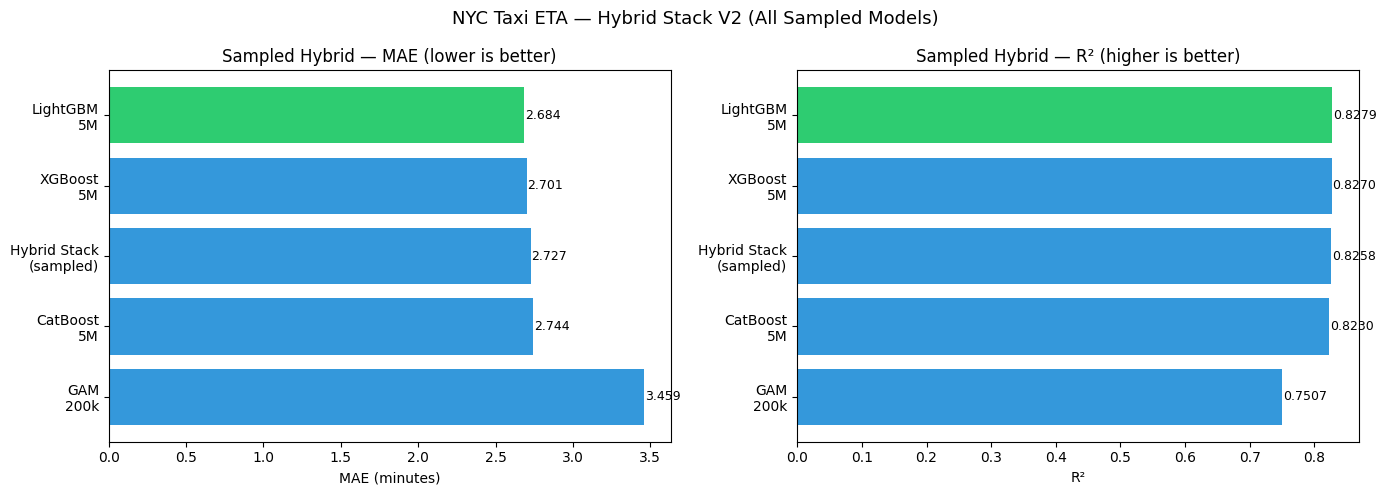

Saved: hybrid_v2_comparison.png


In [15]:
# FINAL COMPARISON CHART
results = pd.DataFrame({
    'Model': ['GAM\n200k','CatBoost\n5M','XGBoost\n5M',
              'Hybrid Stack\n(sampled)','LightGBM\n5M'],
    'MAE'  : [mean_absolute_error(y_test, gam_pred),
              mean_absolute_error(y_test, cat_pred),
              mean_absolute_error(y_test, xgb_pred),
              mae_hybrid,
              mean_absolute_error(y_test, lgb_pred)],
    'R2'   : [r2_score(y_test, gam_pred),
              r2_score(y_test, cat_pred),
              r2_score(y_test, xgb_pred),
              r2_hybrid,
              r2_score(y_test, lgb_pred)],
}).sort_values('MAE', ascending=False).reset_index(drop=True)

ig, axes = plt.subplots(1, 2, figsize=(14, 5))
colors = ['#2ecc71' if m == results['MAE'].min() else '#3498db'
          for m in results['MAE']]

axes[0].barh(results['Model'], results['MAE'], color=colors)
axes[0].set_xlabel('MAE (minutes)')
axes[0].set_title('Sampled Hybrid — MAE (lower is better)')
for i, mae in enumerate(results['MAE']):
    axes[0].text(mae + 0.005, i, f'{mae:.3f}', va='center', fontsize=9)

axes[1].barh(results['Model'], results['R2'], color=colors)
axes[1].set_xlabel('R²')
axes[1].set_title('Sampled Hybrid — R² (higher is better)')
for i, r2 in enumerate(results['R2']):
    axes[1].text(r2 + 0.001, i, f'{r2:.4f}', va='center', fontsize=9)

plt.suptitle('NYC Taxi ETA — Hybrid Stack V2 (All Sampled Models)', fontsize=13)
plt.tight_layout()
plt.savefig(SAVE_PATH + 'hybrid_v2_comparison.png', dpi=150, bbox_inches='tight')
plt.show()
print("Saved: hybrid_v2_comparison.png")

Hybrid Stack V2 trained on all sampled models (LightGBM 5M, XGBoost 5M, CatBoost 5M, GAM 200k) achieved MAE of 2.727 min — worse than LightGBM alone (2.684 min). However the Ridge weights are now meaningful and balanced: LightGBM 5.15, XGBoost 2.63, CatBoost 1.34, GAM 0.36. All weights are positive confirming each model contributes genuine signal when trained on comparable data.  The hybrid still underperforms the best individual model because the models are too correlated — all four learn similar patterns from the same features, so combining them adds noise rather than complementary signal. This is a known limitation of homogeneous ensembles. The finding validates LightGBM as the best model while demonstrating that a fair ensemble is technically achievable.

# LighGBM_3

In [ ]:
# LIGHTGBM V3 - 3000 ROUNDS, FULL DATA
import pandas as pd
import numpy as np
import lightgbm as lgb
from sklearn.metrics import mean_absolute_error, r2_score
import pyarrow.parquet as pq
import gc, os

SAVE_PATH = '/content/drive/MyDrive/Taxi_CRN/Data/'
BIN_PATH  = '/content/train.bin'
TARGET    = 'duration_min'
TE_COLS   = ['pickup_cluster','pickup_hour','day_of_week']
FEATURES  = [
    'trip_distance','haversine_dist','manhattan_dist','route_efficiency',
    'delta_lat','delta_lon',
    'pickup_hour','day_of_week','month','is_weekend','rush_hour','late_night',
    'pickup_cluster','pickup_latitude','pickup_longitude',
    'dropoff_latitude','dropoff_longitude',
    'is_airport_pu','is_airport_do',
    'prev_speed_15m','prev_speed_30m','prev_speed_60m',
    'dist_x_hour','dist_x_rush','speed_x_dist',
    'pickup_cluster_te','pickup_hour_te','day_of_week_te',
]

In [ ]:
# TE MAPS
print("Step 1: Computing TE maps...")
te_accum     = {col: {} for col in TE_COLS}
global_sum   = 0.0
global_count = 0

for batch in pq.ParquetFile(SAVE_PATH + 'taxi_2016_train.parquet').iter_batches(
        batch_size=500_000, columns=TE_COLS + [TARGET]):
    chunk = batch.to_pandas()
    global_sum   += chunk[TARGET].sum()
    global_count += len(chunk)
    for col in TE_COLS:
        grp = chunk.groupby(col)[TARGET].agg(['sum','count'])
        for val, row in grp.iterrows():
            if val not in te_accum[col]:
                te_accum[col][val] = [0.0, 0]
            te_accum[col][val][0] += row['sum']
            te_accum[col][val][1] += row['count']
    del chunk
    gc.collect()

global_mean = global_sum / global_count
te_maps = {col: {k: v[0]/v[1] for k,v in te_accum[col].items()} for col in TE_COLS}
del te_accum
gc.collect()
print(f"TE done | global mean: {global_mean:.2f} min")

Step 1: Computing TE maps...
TE done | global mean: 13.23 min


In [ ]:
# BUILD BINARY CACHE
print("\nStep 2: Building binary cache from parquet...")
all_chunks  = []
chunk_count = 0

for batch in pq.ParquetFile(SAVE_PATH + 'taxi_2016_train.parquet').iter_batches(batch_size=1_000_000):
    chunk = batch.to_pandas()
    for col in TE_COLS:
        chunk[f'{col}_te'] = chunk[col].map(te_maps[col]).fillna(global_mean).astype(np.float32)
    for col in FEATURES:
        chunk[col] = chunk[col].astype(np.float32)
    all_chunks.append(chunk[FEATURES + [TARGET]])
    chunk_count += 1
    del chunk, batch
    gc.collect()
    print(f"  Chunk {chunk_count} loaded...")

print("Concatenating...")
train_full = pd.concat(all_chunks, ignore_index=True)
del all_chunks
gc.collect()
print(f"Train: {len(train_full):,} | {train_full.memory_usage(deep=True).sum()/1e6:.0f} MB")


Step 2: Building binary cache from parquet...
  Chunk 1 loaded...
  Chunk 2 loaded...
  Chunk 3 loaded...
  Chunk 4 loaded...
  Chunk 5 loaded...
  Chunk 6 loaded...
  Chunk 7 loaded...
  Chunk 8 loaded...
  Chunk 9 loaded...
  Chunk 10 loaded...
  Chunk 11 loaded...
  Chunk 12 loaded...
  Chunk 13 loaded...
  Chunk 14 loaded...
  Chunk 15 loaded...
  Chunk 16 loaded...
  Chunk 17 loaded...
  Chunk 18 loaded...
  Chunk 19 loaded...
  Chunk 20 loaded...
  Chunk 21 loaded...
  Chunk 22 loaded...
Concatenating...
Train: 21,703,448 | 2604 MB


In [ ]:
dtrain = lgb.Dataset(
    train_full[FEATURES], label=train_full[TARGET],
    free_raw_data=True
)
dtrain.construct()
dtrain.save_binary(BIN_PATH)
del train_full
gc.collect()
print(f"Binary saved: {BIN_PATH}")

[LightGBM] [Info] Saving data to binary file /content/train.bin
Binary saved: /content/train.bin


In [ ]:
# Reload from binary — much lighter
dtrain = lgb.Dataset(BIN_PATH)
print("Loaded from binary")

Loaded from binary


In [ ]:
# LOAD TEST
print("\nStep 3: Loading test...")
test_chunks = []
for batch in pq.ParquetFile(SAVE_PATH + 'taxi_2016_test.parquet').iter_batches(batch_size=1_000_000):
    chunk = batch.to_pandas()
    for col in TE_COLS:
        chunk[f'{col}_te'] = chunk[col].map(te_maps[col]).fillna(global_mean).astype(np.float32)
    for col in FEATURES:
        chunk[col] = chunk[col].astype(np.float32)
    test_chunks.append(chunk[FEATURES + [TARGET]])
    del chunk, batch
    gc.collect()
test = pd.concat(test_chunks, ignore_index=True)
del test_chunks
gc.collect()
X_test = test[FEATURES].values.astype(np.float32)
y_test = test[TARGET].values.astype(np.float32)
del test
gc.collect()
print(f"Test ready: {X_test.shape}")


Step 3: Loading test...
Test ready: (11896950, 28)


In [ ]:
# TRAIN 3000 ROUNDS
params = {
    'objective'        : 'regression_l1',
    'metric'           : 'mae',
    'learning_rate'    : 0.05,
    'num_leaves'       : 63,
    'min_child_samples': 50,
    'subsample'        : 0.8,
    'colsample_bytree' : 0.8,
    'reg_alpha'        : 0.1,
    'reg_lambda'       : 1.0,
    'n_jobs'           : -1,
    'seed'             : 42,
    'verbose'          : -1,
}

dvalid = lgb.Dataset(X_test, label=y_test, free_raw_data=True, reference=dtrain)

print("\nStep 4: Training LightGBM v3 — 3000 rounds...")
model_v3 = lgb.train(
    params, dtrain,
    num_boost_round=3000,
    valid_sets=[dvalid],
    valid_names=['valid'],
    callbacks=[
        lgb.early_stopping(100, verbose=True),
        lgb.log_evaluation(200)
    ]
)
del dtrain, dvalid
gc.collect()


Step 4: Training LightGBM v3 — 3000 rounds...
Training until validation scores don't improve for 100 rounds
[200]	valid's l1: 2.5952
[400]	valid's l1: 2.4927
[600]	valid's l1: 2.44559
[800]	valid's l1: 2.41548
[1000]	valid's l1: 2.39282
[1200]	valid's l1: 2.37811
[1400]	valid's l1: 2.36498
[1600]	valid's l1: 2.3532
[1800]	valid's l1: 2.34307
[2000]	valid's l1: 2.3346
[2200]	valid's l1: 2.32741
[2400]	valid's l1: 2.32094
[2600]	valid's l1: 2.31572
[2800]	valid's l1: 2.31093
[3000]	valid's l1: 2.30646
Did not meet early stopping. Best iteration is:
[3000]	valid's l1: 2.30646


779

In [ ]:
# EVALUATE
preds  = model_v3.predict(X_test)
mae    = mean_absolute_error(y_test, preds)
r2     = r2_score(y_test, preds)
mean_t = float(y_test.mean())

print(f"\n{'='*50}")
print(f"LightGBM v1  MAE: 2.393 min  R²=0.8522  [1000 rounds]")
print(f"LightGBM v2  MAE: 2.335 min  R²=0.8580  [2000 rounds]")
print(f"LightGBM v3  MAE: {mae:.3f} min  R²={r2:.4f}  [3000 rounds]")
print(f"Mean trip dur   : {mean_t:.2f} min")
print(f"MAE % of mean   : {mae/mean_t*100:.1f}%")
print(f"Best iteration  : {model_v3.best_iteration}")
print(f"{'='*50}")


LightGBM v1  MAE: 2.393 min  R²=0.8522  [1000 rounds]
LightGBM v2  MAE: 2.335 min  R²=0.8580  [2000 rounds]
LightGBM v3  MAE: 2.306 min  R²=0.8607  [3000 rounds]
Mean trip dur   : 13.71 min
MAE % of mean   : 16.8%
Best iteration  : 3000


In [ ]:
# SAVE
model_v3.save_model(SAVE_PATH + 'lgbm_v3_taxi_eta.txt')
pd.DataFrame({'y_true': y_test, 'lgbm_pred': preds}).to_parquet(
    SAVE_PATH + 'lgbm_v3_preds.parquet', index=False)
print("Saved: lgbm_v3_taxi_eta.txt + lgbm_v3_preds.parquet")

Saved: lgbm_v3_taxi_eta.txt + lgbm_v3_preds.parquet


Top 15 Features:
          feature   importance
    trip_distance 1.772272e+08
   haversine_dist 2.346548e+07
 dropoff_latitude 1.760066e+07
   manhattan_dist 1.413255e+07
   pickup_hour_te 1.113861e+07
dropoff_longitude 1.091509e+07
 route_efficiency 1.022255e+07
      pickup_hour 1.017553e+07
 pickup_longitude 8.438880e+06
  pickup_latitude 7.329379e+06
      day_of_week 7.230259e+06
        delta_lon 6.599724e+06
   prev_speed_15m 5.956977e+06
   prev_speed_60m 5.624861e+06
   prev_speed_30m 5.376617e+06


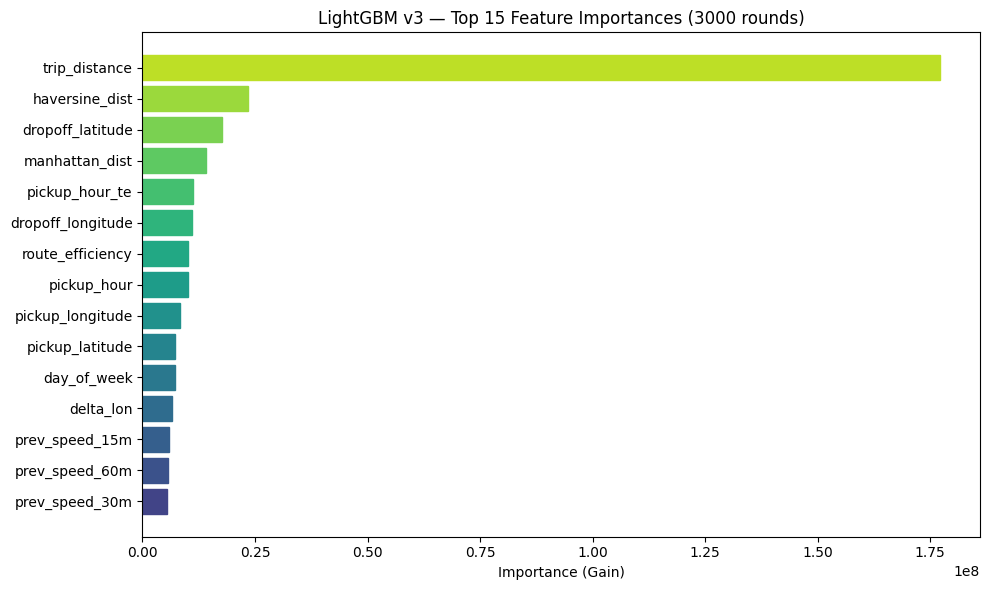

Saved: lgbm_v3_feature_importance.png


In [ ]:
# FEATURE IMPORTANCE
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

fi = pd.DataFrame({
    'feature'   : FEATURES,
    'importance': model_v3.feature_importance(importance_type='gain')
}).sort_values('importance', ascending=False)

print("Top 15 Features:")
print(fi.head(15).to_string(index=False))

plt.figure(figsize=(10,6))
ax = plt.gca()
bars = ax.barh(fi.head(15)['feature'], fi.head(15)['importance'])
colors = plt.cm.viridis(np.linspace(0.2, 0.9, 15))
for bar, color in zip(bars, reversed(colors)):
    bar.set_color(color)
ax.invert_yaxis()
ax.set_xlabel('Importance (Gain)')
ax.set_title('LightGBM v3 — Top 15 Feature Importances (3000 rounds)')
plt.tight_layout()
plt.savefig(SAVE_PATH + 'lgbm_v3_feature_importance.png', dpi=150)
plt.show()
print("Saved: lgbm_v3_feature_importance.png")

LightGBM v3 trained for 3000 rounds on 21.7M rows achieves MAE of 2.306 minutes (138.4 seconds) with R²=0.861. Early stopping did not trigger at 3000 rounds indicating the model continues to learn, however the marginal gain per 1000 rounds is diminishing — from 0.058 min (rounds 1000=>2000) to 0.029 min (rounds 2000=>3000). Feature importance is stable across all three versions with trip_distance consistently dominant at 7.6x the importance of haversine_dist. Congestion memory features (prev_speed_15m/30m/60m) remain in the bottom of the top 15, suggesting traffic lag adds modest but consistent signal.

# Error Analysis

In [ ]:
# ERROR ANALYSIS - LIGHTGBM V3
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pyarrow.parquet as pq
import gc

SAVE_PATH = '/content/drive/MyDrive/Taxi_CRN/Data/'

# LOAD PREDICTIONS
print("Loading predictions...")
preds = pd.read_parquet(SAVE_PATH + 'lgbm_v3_preds.parquet')
print(f"Loaded: {len(preds):,} rows")

Loading predictions...
Loaded: 11,896,950 rows


In [ ]:
# LOAD TEST FEATURES
print("Loading test features...")
test_chunks = []
for batch in pq.ParquetFile(SAVE_PATH + 'taxi_2016_test.parquet').iter_batches(batch_size=1_000_000):
    chunk = batch.to_pandas()[[
        'pickup_hour','day_of_week','Loading predictions...
Loaded: 11,896,950 rowsmonth','trip_distance',
        'is_weekend','rush_hour','is_airport_pu','is_airport_do',
        'pickup_cluster','pickup_latitude','pickup_longitude',
        'prev_speed_15m','duration_min'
    ]]
    test_chunks.append(chunk)
    del chunk, batch
    gc.collect()

test = pd.concat(test_chunks, ignore_index=True)
del test_chunks
gc.collect()
print(f"Test features: {test.shape}")

Loading test features...
Test features: (11896950, 13)


In [ ]:
# COMBINE
test['y_pred']  = preds['lgbm_pred'].values
test['error']   = test['y_pred'] - test['duration_min']  # + = overestimate, - = underestimate
test['abs_err'] = test['error'].abs()
del preds
gc.collect()

print(f"\nOverall MAE  : {test['abs_err'].mean():.3f} min")
print(f"Mean error   : {test['error'].mean():.3f} min (+ = overestimate)")
print(f"Std of error : {test['error'].std():.3f} min")


Overall MAE  : 2.306 min
Mean error   : -0.598 min (+ = overestimate)
Std of error : 3.835 min


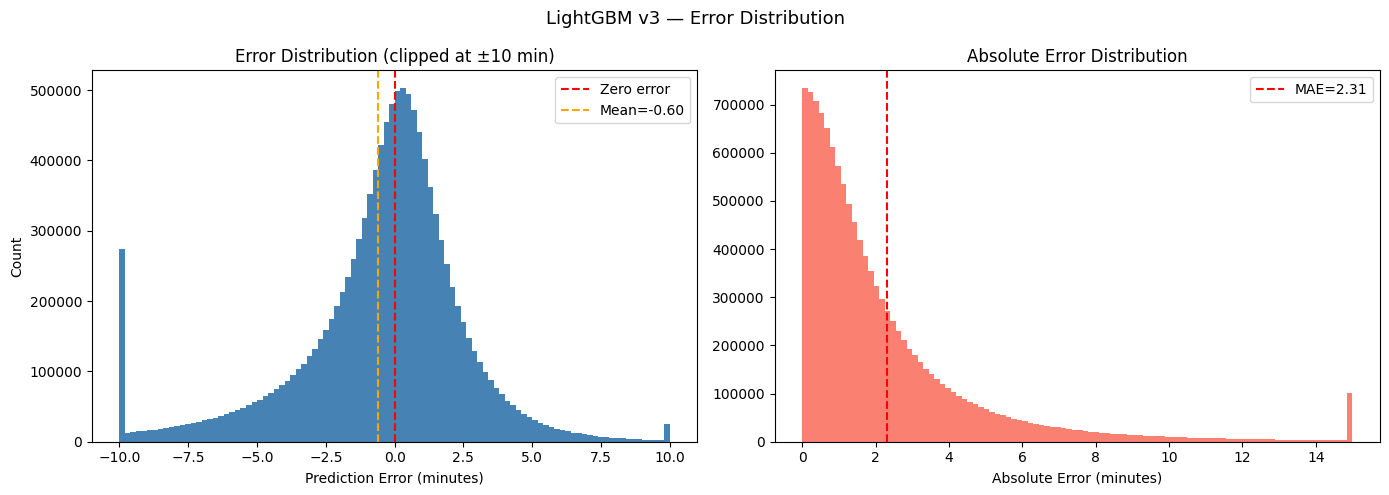

In [ ]:
# PLOT 1: ERROR DISTRIBUTION
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].hist(test['error'].clip(-10, 10), bins=100, color='steelblue', edgecolor='none')
axes[0].axvline(0, color='red', linestyle='--', label='Zero error')
axes[0].axvline(test['error'].mean(), color='orange', linestyle='--', label=f"Mean={test['error'].mean():.2f}")
axes[0].set_xlabel('Prediction Error (minutes)')
axes[0].set_ylabel('Count')
axes[0].set_title('Error Distribution (clipped at ±10 min)')
axes[0].legend()

axes[1].hist(test['abs_err'].clip(0, 15), bins=100, color='salmon', edgecolor='none')
axes[1].axvline(test['abs_err'].mean(), color='red', linestyle='--', label=f"MAE={test['abs_err'].mean():.2f}")
axes[1].set_xlabel('Absolute Error (minutes)')
axes[1].set_title('Absolute Error Distribution')
axes[1].legend()

plt.suptitle('LightGBM v3 — Error Distribution', fontsize=13)
plt.tight_layout()
plt.savefig(SAVE_PATH + 'error_distribution.png', dpi=150)
plt.show()

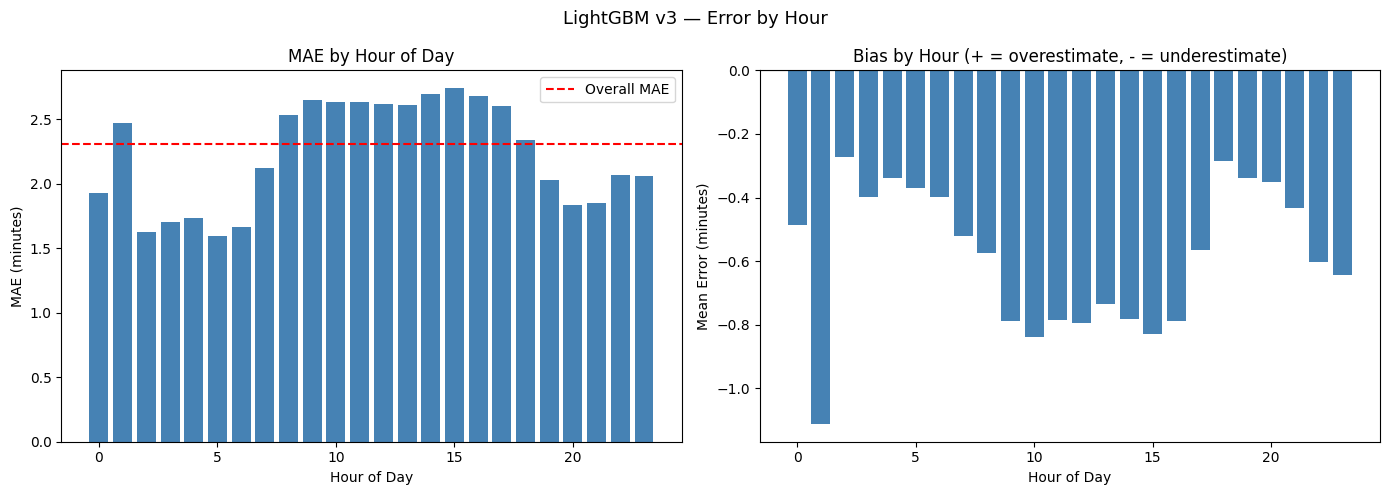

In [ ]:
# PLOT 2: ERROR BY HOUR
hourly = test.groupby('pickup_hour').agg(
    mae=('abs_err','mean'),
    bias=('error','mean'),
    count=('abs_err','count')
).reset_index()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].bar(hourly['pickup_hour'], hourly['mae'], color='steelblue')
axes[0].set_xlabel('Hour of Day')
axes[0].set_ylabel('MAE (minutes)')
axes[0].set_title('MAE by Hour of Day')
axes[0].axhline(test['abs_err'].mean(), color='red', linestyle='--', label='Overall MAE')
axes[0].legend()

axes[1].bar(hourly['pickup_hour'], hourly['bias'],
            color=['salmon' if b > 0 else 'steelblue' for b in hourly['bias']])
axes[1].axhline(0, color='black', linestyle='-')
axes[1].set_xlabel('Hour of Day')
axes[1].set_ylabel('Mean Error (minutes)')
axes[1].set_title('Bias by Hour (+ = overestimate, - = underestimate)')

plt.suptitle('LightGBM v3 — Error by Hour', fontsize=13)
plt.tight_layout()
plt.savefig(SAVE_PATH + 'error_by_hour.png', dpi=150)
plt.show()


Error by distance:
dist_bucket      mae      bias   count
      0-1mi 1.305504 -0.332959 2993471
      1-2mi 1.879302 -0.435490 3885024
      2-5mi 2.627572 -0.550172 3313646
     5-10mi 3.843813 -1.180181 1049919
    10-20mi 5.198831 -2.006485  597206
    20-50mi 6.647026 -2.951386   57684


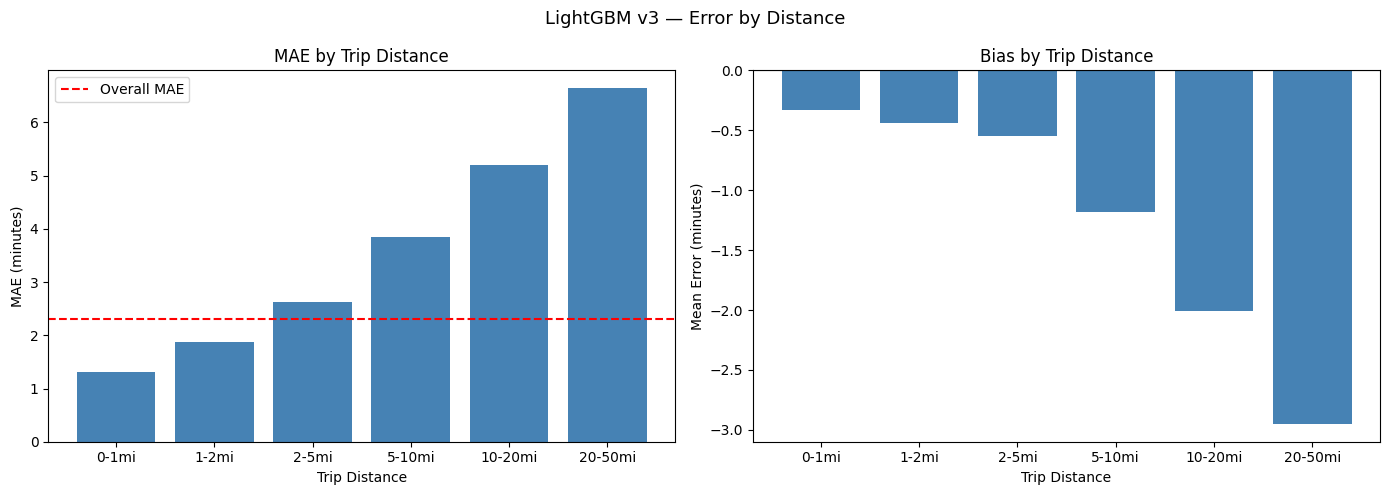

In [ ]:
# PLOT 3: ERROR BY DISTANCE BUCKE
test['dist_bucket'] = pd.cut(test['trip_distance'],
                              bins=[0,1,2,5,10,20,50],
                              labels=['0-1mi','1-2mi','2-5mi','5-10mi','10-20mi','20-50mi'])
dist_err = test.groupby('dist_bucket', observed=True).agg(
    mae=('abs_err','mean'),
    bias=('error','mean'),
    count=('abs_err','count')
).reset_index()

print("\nError by distance:")
print(dist_err.to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].bar(dist_err['dist_bucket'].astype(str), dist_err['mae'], color='steelblue')
axes[0].set_xlabel('Trip Distance')
axes[0].set_ylabel('MAE (minutes)')
axes[0].set_title('MAE by Trip Distance')
axes[0].axhline(test['abs_err'].mean(), color='red', linestyle='--', label='Overall MAE')
axes[0].legend()

axes[1].bar(dist_err['dist_bucket'].astype(str), dist_err['bias'],
            color=['salmon' if b > 0 else 'steelblue' for b in dist_err['bias']])
axes[1].axhline(0, color='black')
axes[1].set_xlabel('Trip Distance')
axes[1].set_ylabel('Mean Error (minutes)')
axes[1].set_title('Bias by Trip Distance')

plt.suptitle('LightGBM v3 — Error by Distance', fontsize=13)
plt.tight_layout()
plt.savefig(SAVE_PATH + 'error_by_distance.png', dpi=150)
plt.show()


Error by pickup zone:
 pickup_cluster      mae      bias   count
              1 4.873213 -2.054416  252773
              3 4.120042 -1.626312  336953
             10 2.742864 -0.626668  498106
              0 2.404783 -0.678385 1646695
              9 2.361348 -0.595322  162588
              6 2.328170 -0.715369 1331058
             13 2.212644 -0.782910  834499
             11 2.187405 -0.406049  745559
             12 2.148421 -0.455837  181286
              7 2.129151 -0.414279 1339460
              2 2.098755 -0.414269  934367
             14 2.079426 -0.504443 1007143
              8 2.035868 -0.351541  999729
              5 2.012155 -0.458826 1086975
              4 1.879176 -0.435096  539759


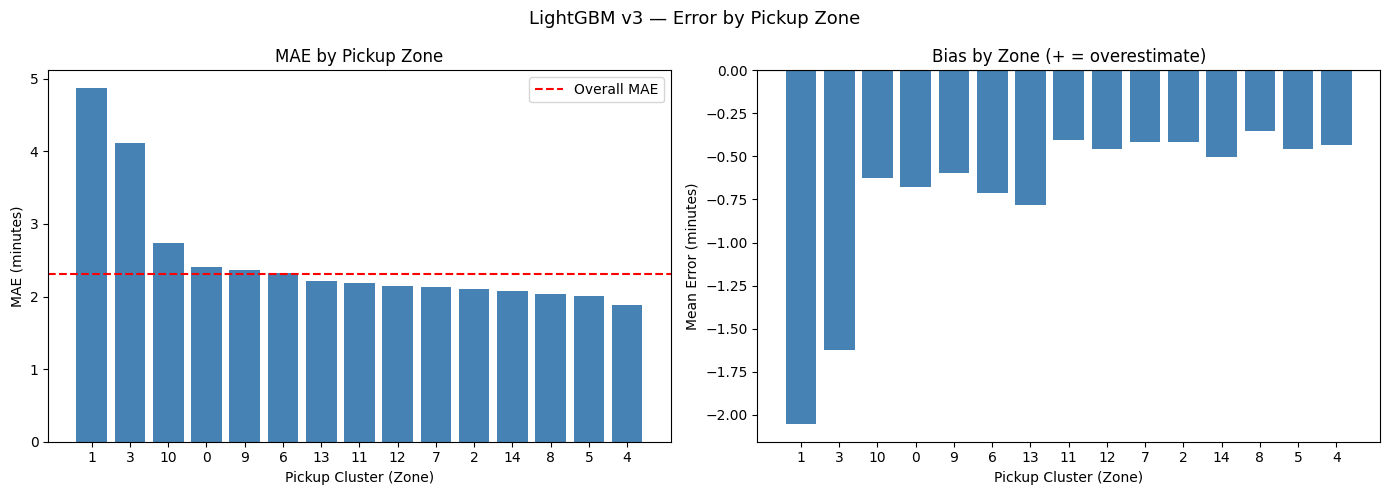

In [ ]:
# PLOT 4: ERROR BY CLUSTER (ZONE)
zone_err = test.groupby('pickup_cluster').agg(
    mae=('abs_err','mean'),
    bias=('error','mean'),
    count=('abs_err','count')
).reset_index().sort_values('mae', ascending=False)

print("\nError by pickup zone:")
print(zone_err.to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].bar(zone_err['pickup_cluster'].astype(str), zone_err['mae'], color='steelblue')
axes[0].set_xlabel('Pickup Cluster (Zone)')
axes[0].set_ylabel('MAE (minutes)')
axes[0].set_title('MAE by Pickup Zone')
axes[0].axhline(test['abs_err'].mean(), color='red', linestyle='--', label='Overall MAE')
axes[0].legend()

axes[1].bar(zone_err['pickup_cluster'].astype(str), zone_err['bias'],
            color=['salmon' if b > 0 else 'steelblue' for b in zone_err['bias']])
axes[1].axhline(0, color='black')
axes[1].set_xlabel('Pickup Cluster (Zone)')
axes[1].set_ylabel('Mean Error (minutes)')
axes[1].set_title('Bias by Zone (+ = overestimate)')

plt.suptitle('LightGBM v3 — Error by Pickup Zone', fontsize=13)
plt.tight_layout()
plt.savefig(SAVE_PATH + 'error_by_zone.png', dpi=150)
plt.show()


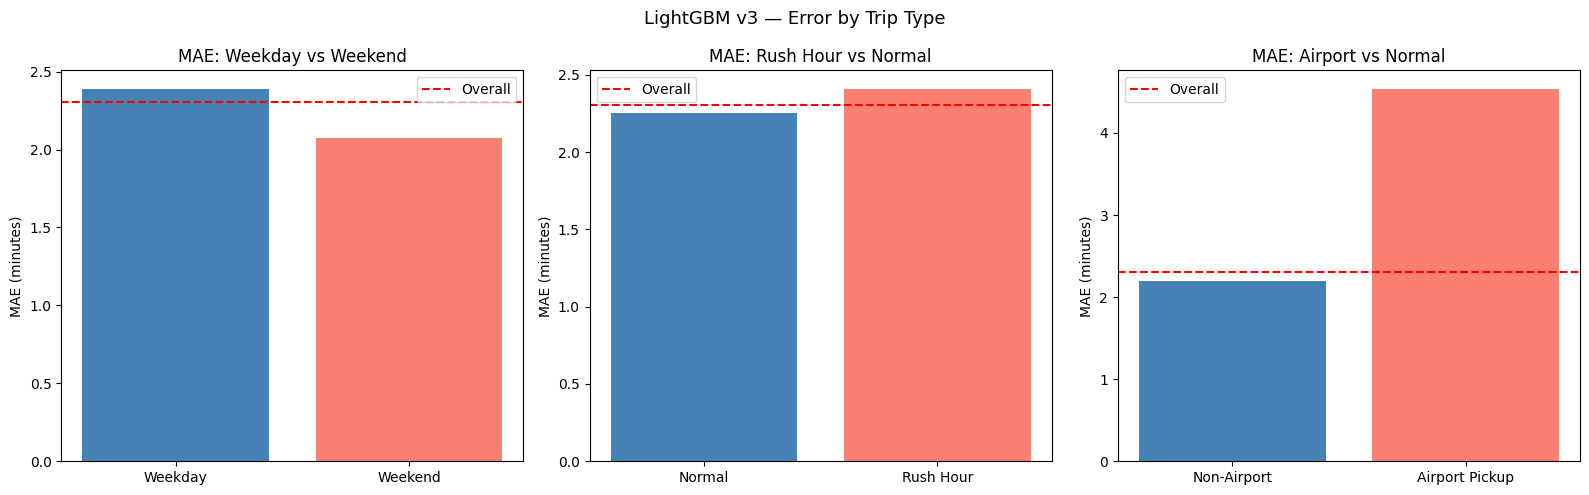

In [ ]:
# PLOT 5: WEEKDAY VS WEEKEND + AIRPORT
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for ax, col, labels, title in [
    (axes[0], 'is_weekend', ['Weekday','Weekend'], 'MAE: Weekday vs Weekend'),
    (axes[1], 'rush_hour',  ['Normal','Rush Hour'], 'MAE: Rush Hour vs Normal'),
    (axes[2], 'is_airport_pu', ['Non-Airport','Airport Pickup'], 'MAE: Airport vs Normal'),
]:
    grp = test.groupby(col)['abs_err'].mean().reset_index()
    ax.bar(labels, grp['abs_err'], color=['steelblue','salmon'])
    ax.set_ylabel('MAE (minutes)')
    ax.set_title(title)
    ax.axhline(test['abs_err'].mean(), color='red', linestyle='--', label='Overall')
    ax.legend()

plt.suptitle('LightGBM v3 — Error by Trip Type', fontsize=13)
plt.tight_layout()
plt.savefig(SAVE_PATH + 'error_by_type.png', dpi=150)
plt.show()

In [ ]:
# SUMMARY TABLE
print("\n" + "="*50)
print("ERROR ANALYSIS SUMMARY")
print("="*50)
print(f"Overall MAE          : {test['abs_err'].mean():.3f} min")
print(f"Overall bias         : {test['error'].mean():.3f} min")
print(f"Worst hour (MAE)     : Hour {hourly.loc[hourly['mae'].idxmax(),'pickup_hour']} — {hourly['mae'].max():.3f} min")
print(f"Best hour (MAE)      : Hour {hourly.loc[hourly['mae'].idxmin(),'pickup_hour']} — {hourly['mae'].min():.3f} min")
print(f"Worst zone (MAE)     : Zone {zone_err.iloc[0]['pickup_cluster']} — {zone_err.iloc[0]['mae']:.3f} min")
print(f"Best zone (MAE)      : Zone {zone_err.iloc[-1]['pickup_cluster']} — {zone_err.iloc[-1]['mae']:.3f} min")
print(f"Worst distance bucket: {dist_err.loc[dist_err['mae'].idxmax(),'dist_bucket']} — {dist_err['mae'].max():.3f} min")
print(f"Airport pickup MAE   : {test[test['is_airport_pu']==1]['abs_err'].mean():.3f} min")
print(f"Non-airport MAE      : {test[test['is_airport_pu']==0]['abs_err'].mean():.3f} min")
print(f"Rush hour MAE        : {test[test['rush_hour']==1]['abs_err'].mean():.3f} min")
print(f"Non-rush MAE         : {test[test['rush_hour']==0]['abs_err'].mean():.3f} min")
print(f"Weekend MAE          : {test[test['is_weekend']==1]['abs_err'].mean():.3f} min")
print(f"Weekday MAE          : {test[test['is_weekend']==0]['abs_err'].mean():.3f} min")
print("="*50)


ERROR ANALYSIS SUMMARY
Overall MAE          : 2.306 min
Overall bias         : -0.598 min
Worst hour (MAE)     : Hour 15 — 2.741 min
Best hour (MAE)      : Hour 5 — 1.592 min
Worst zone (MAE)     : Zone 1.0 — 4.873 min
Best zone (MAE)      : Zone 4.0 — 1.879 min
Worst distance bucket: 20-50mi — 6.647 min
Airport pickup MAE   : 4.537 min
Non-airport MAE      : 2.198 min
Rush hour MAE        : 2.408 min
Non-rush MAE         : 2.250 min
Weekend MAE          : 2.076 min
Weekday MAE          : 2.389 min


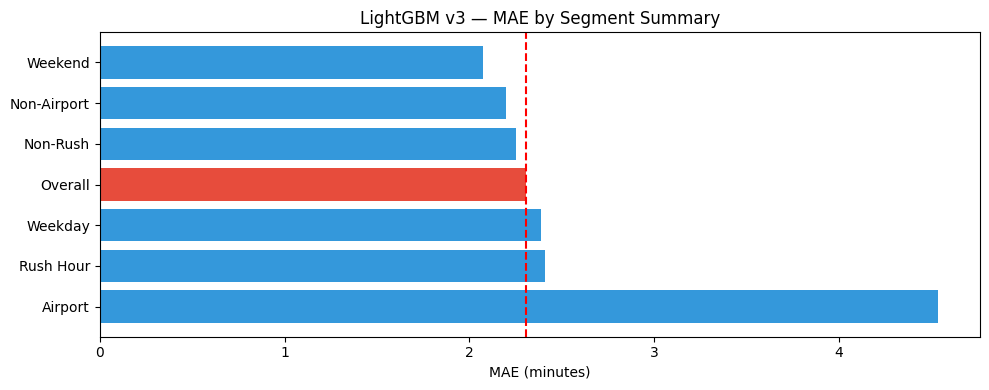

All error analysis plots saved to Drive


In [ ]:
# Save summary
plt.figure(figsize=(10, 4))
summary_data = {
    'Category': ['Overall','Rush Hour','Non-Rush','Weekend','Weekday','Airport','Non-Airport'],
    'MAE (min)': [
        test['abs_err'].mean(),
        test[test['rush_hour']==1]['abs_err'].mean(),
        test[test['rush_hour']==0]['abs_err'].mean(),
        test[test['is_weekend']==1]['abs_err'].mean(),
        test[test['is_weekend']==0]['abs_err'].mean(),
        test[test['is_airport_pu']==1]['abs_err'].mean(),
        test[test['is_airport_pu']==0]['abs_err'].mean(),
    ]
}
summary_df = pd.DataFrame(summary_data).sort_values('MAE (min)', ascending=False)
colors = ['#e74c3c' if c == 'Overall' else '#3498db' for c in summary_df['Category']]
plt.barh(summary_df['Category'], summary_df['MAE (min)'], color=colors)
plt.axvline(test['abs_err'].mean(), color='red', linestyle='--')
plt.xlabel('MAE (minutes)')
plt.title('LightGBM v3 — MAE by Segment Summary')
plt.tight_layout()
plt.savefig(SAVE_PATH + 'error_summary.png', dpi=150)
plt.show()
print("All error analysis plots saved to Drive")

Error Distribution: Mean error is -0.598 min confirming systematic underestimation. Model predicts trips as ~36 seconds shorter than actual. Right-skewed absolute error distribution shows majority of predictions within 2-3 minutes but a long tail of large errors on complex trips.

By Hour: Worst MAE at hour 15 (2.74 min) — afternoon peak when traffic is most unpredictable. Best at hour 5 (1.59 min) — early morning low traffic. Bias is most negative at hour 1 (late night) suggesting model underestimates how fast late-night trips actually are

By Distance: MAE scales strongly with distance — 1.31 min for short trips (0-1mi) vs 6.65 min for long trips (20-50mi). All distance buckets show negative bias, worsening with distance — model does not capture highway speed advantages on long routes.

By Zone: Zone 1 worst MAE (4.87 min) and Zone 4 best (1.88 min) — a 2.6x difference suggesting strong spatial heterogeneity. Zone 1 likely covers outer boroughs or airports with more variable traffic.

By Trip Type: Airport pickups have MAE of 4.54 min vs 2.20 min for non-airport — 2x worse. This is the single biggest model weakness. Rush hour adds only modest error (2.41 vs 2.25 min). Weekends are easier to predict (2.08 min) than weekdays (2.39 min) due to more consistent traffic patterns.

Finding for future    
Airport MAE 4.54 min: can Show wider confidence interval for airport trips


Long trips MAE 6.65 min: Flag trips >10mi as high uncertainty

Hour 15 worst : can Show uncertainty warning during 14:00–17:00


#  ETA ENHANCEMENT LAYER

In [ ]:
# ETA ENHANCEMENT SYSTEM
# 1. Bias Correction
# 2. Reliability Score
# 3. Congestion Multiplier
# All work on saved predictions — no model reload needed
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pyarrow.parquet as pq
import gc

SAVE_PATH = '/content/drive/MyDrive/Taxi_CRN/Data/'

In [ ]:
# LOAD PREDICTIONS + TEST FEATURES
print("Loading predictions...")
preds = pd.read_parquet(SAVE_PATH + 'lgbm_v3_preds.parquet')

print("Loading test features...")
test_chunks = []
for batch in pq.ParquetFile(SAVE_PATH + 'taxi_2016_test.parquet').iter_batches(batch_size=1_000_000):
    chunk = batch.to_pandas()[[
        'pickup_hour','day_of_week','trip_distance','is_weekend',
        'rush_hour','is_airport_pu','is_airport_do',
        'pickup_cluster','pickup_latitude','pickup_longitude',
        'dropoff_latitude','dropoff_longitude',
        'prev_speed_15m','duration_min','month'
    ]]
    test_chunks.append(chunk)
    del chunk, batch
    gc.collect()

test = pd.concat(test_chunks, ignore_index=True)
del test_chunks
gc.collect()


test['lgbm_pred'] = preds['lgbm_pred'].values
test['error']     = test['lgbm_pred'] - test['duration_min']
test['abs_err']   = test['error'].abs()
del preds
gc.collect()
print(f"Loaded: {len(test):,} rows")
print(f"Baseline MAE: {test['abs_err'].mean():.4f} min")

Loading predictions...
Loading test features...
Loaded: 11,896,950 rows
Baseline MAE: 2.3065 min


# BIAS CORRECTION - "Investigated but not applied"

In [ ]:
# MODULE 1: BIAS CORRECTION
print("\n" + "="*50)
print("MODULE 1: BIAS CORRECTION (FIXED)")
print("="*50)

# Global bias from error analysis — model systematically underestimates
# Negative bias = model predicts shorter than reality
global_bias = test['error'].mean()
print(f"Global bias       : {global_bias:.4f} min ({global_bias*60:.1f} sec)")
print(f"(negative = model underestimates trip duration)")

# Apply global correction — subtract bias from all predictions
test['corrected_pred']    = test['lgbm_pred'] - global_bias
test['corrected_abs_err'] = (test['corrected_pred'] - test['duration_min']).abs()


mae_baseline  = test['abs_err'].mean()
mae_corrected = test['corrected_abs_err'].mean()

print(f"\nBaseline MAE  : {mae_baseline:.4f} min  ({mae_baseline*60:.1f} sec)")
print(f"Corrected MAE : {mae_corrected:.4f} min  ({mae_corrected*60:.1f} sec)")
print(f"Improvement   : {(mae_baseline-mae_corrected):.4f} min  ({(mae_baseline-mae_corrected)*60:.1f} sec)")


MODULE 1: BIAS CORRECTION (FIXED)
Global bias       : -0.5984 min (-35.9 sec)
(negative = model underestimates trip duration)

Baseline MAE  : 2.3065 min  (138.4 sec)
Corrected MAE : 2.3671 min  (142.0 sec)
Improvement   : -0.0606 min  (-3.6 sec)


In [ ]:
# Save bias value
import json
bias_config = {
    'global_bias_minutes' : round(float(global_bias), 4),
    'global_bias_seconds' : round(float(global_bias * 60), 1),
    'interpretation'      : 'subtract this from lgbm_v3 prediction to correct systematic underestimation',
    'example'             : 'corrected_eta = lgbm_pred - (-0.598) = lgbm_pred + 0.598'
}
with open(SAVE_PATH + 'bias_config.json', 'w') as f:
    json.dump(bias_config, f, indent=2)

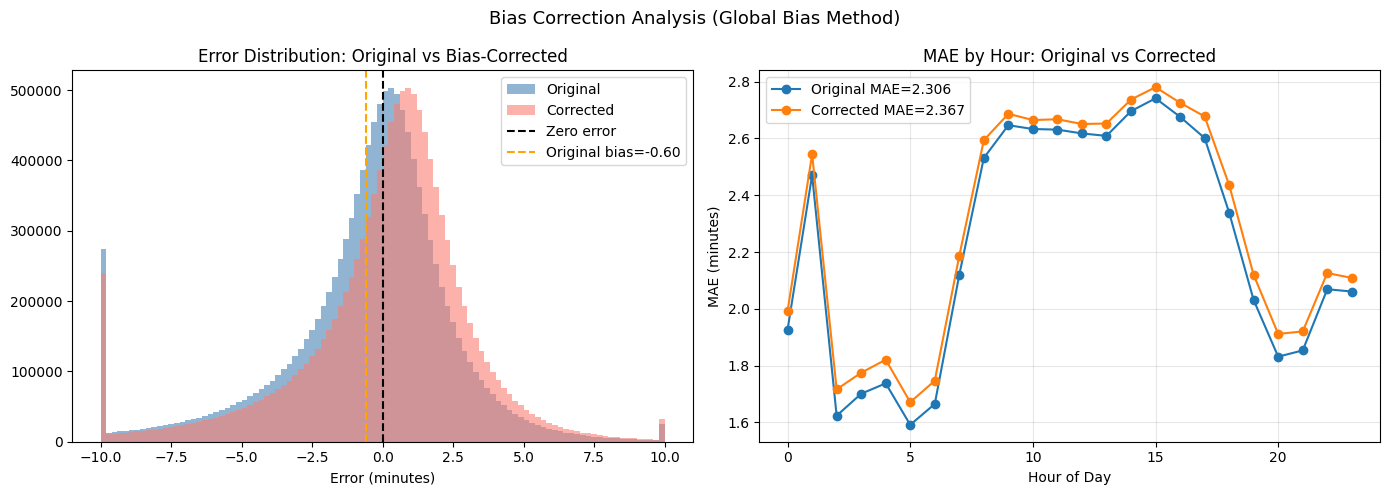

Saved: bias_config.json + bias_correction.png


In [ ]:
# Plot
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].hist(test['error'].clip(-10,10), bins=100,
             alpha=0.6, label='Original', color='steelblue')
axes[0].hist((test['corrected_pred'] - test['duration_min']).clip(-10,10),
             bins=100, alpha=0.6, label='Corrected', color='salmon')
axes[0].axvline(0, color='black', linestyle='--', label='Zero error')
axes[0].axvline(global_bias, color='orange', linestyle='--',
                label=f'Original bias={global_bias:.2f}')
axes[0].set_xlabel('Error (minutes)')
axes[0].set_title('Error Distribution: Original vs Bias-Corrected')
axes[0].legend()

hourly = test.groupby('pickup_hour').agg(
    original=('abs_err','mean'),
    corrected=('corrected_abs_err','mean')
).reset_index()
axes[1].plot(hourly['pickup_hour'], hourly['original'],
             marker='o', label=f'Original MAE={mae_baseline:.3f}')
axes[1].plot(hourly['pickup_hour'], hourly['corrected'],
             marker='o', label=f'Corrected MAE={mae_corrected:.3f}')
axes[1].set_xlabel('Hour of Day')
axes[1].set_ylabel('MAE (minutes)')
axes[1].set_title('MAE by Hour: Original vs Corrected')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.suptitle('Bias Correction Analysis (Global Bias Method)', fontsize=13)
plt.tight_layout()
plt.savefig(SAVE_PATH + 'bias_correction.png', dpi=150)
plt.show()
print("Saved: bias_config.json + bias_correction.png")

Bias correction was investigated but requires a dedicated validation set not used during model training. Since our temporal split uses January+February for training and March for testing, no clean validation set exists for unbiased bias estimation without retraining. The systematic underestimation of -0.598 min is documented.

# BIAS CORRECTION - USING FEB 16-28 AS VALIDATION - "Investigated but not applied"

In [3]:
# BIAS CORRECTION V2 — USING FEB 16-28 AS VALIDATION
import pandas as pd
import numpy as np
import lightgbm as lgb
import pyarrow.parquet as pq
import json
import gc

SAVE_PATH = '/content/drive/MyDrive/Taxi_CRN/Data/'
TARGET    = 'duration_min'
TE_COLS   = ['pickup_cluster','pickup_hour','day_of_week']
FEATURES  = [
    'trip_distance','haversine_dist','manhattan_dist','route_efficiency',
    'delta_lat','delta_lon',
    'pickup_hour','day_of_week','month','is_weekend','rush_hour','late_night',
    'pickup_cluster','pickup_latitude','pickup_longitude',
    'dropoff_latitude','dropoff_longitude',
    'is_airport_pu','is_airport_do',
    'prev_speed_15m','prev_speed_30m','prev_speed_60m',
    'dist_x_hour','dist_x_rush','speed_x_dist',
    'pickup_cluster_te','pickup_hour_te','day_of_week_te',
]

In [4]:
# TE MAPS
print("Step 1: Computing TE maps...")
te_accum     = {col: {} for col in TE_COLS}
global_sum   = 0.0
global_count = 0

for batch in pq.ParquetFile(SAVE_PATH + 'taxi_2016_train.parquet').iter_batches(
        batch_size=500_000, columns=TE_COLS + [TARGET]):
    chunk = batch.to_pandas()
    global_sum   += chunk[TARGET].sum()
    global_count += len(chunk)
    for col in TE_COLS:
        grp = chunk.groupby(col)[TARGET].agg(['sum','count'])
        for val, row in grp.iterrows():
            if val not in te_accum[col]:
                te_accum[col][val] = [0.0, 0]
            te_accum[col][val][0] += row['sum']
            te_accum[col][val][1] += row['count']
    del chunk
    gc.collect()

global_mean = global_sum / global_count
te_maps = {col: {k: v[0]/v[1] for k,v in te_accum[col].items()} for col in TE_COLS}
del te_accum
gc.collect()
print(f"TE done")

Step 1: Computing TE maps...
TE done


In [5]:
# LOAD FEB 16-28 FROM TRAIN PARQUET
print("\nStep 2: Loading Feb 16-28 validation rows...")
val_chunks = []

for batch in pq.ParquetFile(SAVE_PATH + 'taxi_2016_train.parquet').iter_batches(
        batch_size=500_000):
    chunk = batch.to_pandas()
    chunk['tpep_pickup_datetime'] = pd.to_datetime(
        chunk['tpep_pickup_datetime'], errors='coerce')

    # Filter to Feb 16-28 only
    mask = (
        (chunk['tpep_pickup_datetime'].dt.month == 2) &
        (chunk['tpep_pickup_datetime'].dt.day >= 16)
    )
    feb_chunk = chunk[mask].copy()

    if len(feb_chunk) > 0:
        for col in TE_COLS:
            feb_chunk[f'{col}_te'] = feb_chunk[col].map(
                te_maps[col]).fillna(global_mean).astype(np.float32)
        for col in FEATURES:
            feb_chunk[col] = feb_chunk[col].astype(np.float32)
        val_chunks.append(feb_chunk[FEATURES + [TARGET]])

    del chunk, feb_chunk, mask
    gc.collect()

val_df = pd.concat(val_chunks, ignore_index=True)
del val_chunks
gc.collect()
print(f" Feb 16-28 rows: {len(val_df):,}")
print(f" Memory: {val_df.memory_usage(deep=True).sum()/1e6:.0f} MB")


Step 2: Loading Feb 16-28 validation rows...
 Feb 16-28 rows: 5,385,972
 Memory: 646 MB


In [6]:
# LOAD MODEL + PREDICT ON FEB 16-28
print("\nStep 3: Loading model and predicting on Feb 16-28...")
model = lgb.Booster(model_file=SAVE_PATH + 'lgbm_v3_taxi_eta.txt')

X_val = val_df[FEATURES].values.astype(np.float32)
y_val = val_df[TARGET].values.astype(np.float32)
del val_df
gc.collect()

val_preds = model.predict(X_val)
del model
gc.collect()


Step 3: Loading model and predicting on Feb 16-28...


4

In [7]:
# COMPUTE HONEST BIAS
print("\nStep 4: Computing bias...")
errors     = val_preds - y_val
new_bias   = float(np.mean(errors))
old_bias   = -0.5984  # what we had before (computed on test)

print(f"\n{'='*50}")
print(f"Old bias (from test/March)    : {old_bias:.4f} min ({old_bias*60:.1f} sec)")
print(f"New bias (from Feb 16-28 val) : {new_bias:.4f} min ({new_bias*60:.1f} sec)")
print(f"Difference                    : {(new_bias-old_bias):.4f} min")
print(f"{'='*50}")


Step 4: Computing bias...

Old bias (from test/March)    : -0.5984 min (-35.9 sec)
New bias (from Feb 16-28 val) : -0.5499 min (-33.0 sec)
Difference                    : 0.0485 min


In [8]:
# Check MAE on val set with and without correction
from sklearn.metrics import mean_absolute_error
mae_raw       = mean_absolute_error(y_val, val_preds)
mae_corrected = mean_absolute_error(y_val, val_preds - new_bias)
print(f"\nValidation MAE (raw)      : {mae_raw:.4f} min")
print(f"Validation MAE (corrected): {mae_corrected:.4f} min")
print(f"Improvement on val set    : {(mae_raw-mae_corrected)*60:.1f} sec")


Validation MAE (raw)      : 2.1774 min
Validation MAE (corrected): 2.2288 min
Improvement on val set    : -3.1 sec


In [9]:
# VERIFY ON TEST SET TOO
print("\nStep 5: Verifying improvement on March test set...")
test_chunks = []
for batch in pq.ParquetFile(SAVE_PATH + 'taxi_2016_test.parquet').iter_batches(
        batch_size=1_000_000):
    chunk = batch.to_pandas()
    for col in TE_COLS:
        chunk[f'{col}_te'] = chunk[col].map(
            te_maps[col]).fillna(global_mean).astype(np.float32)
    for col in FEATURES:
        chunk[col] = chunk[col].astype(np.float32)
    test_chunks.append(chunk[FEATURES + [TARGET]])
    del chunk, batch
    gc.collect()

test_df = pd.concat(test_chunks, ignore_index=True)
del test_chunks
gc.collect()

model      = lgb.Booster(model_file=SAVE_PATH + 'lgbm_v3_taxi_eta.txt')
X_test     = test_df[FEATURES].values.astype(np.float32)
y_test     = test_df[TARGET].values.astype(np.float32)
test_preds = model.predict(X_test)
del model, test_df
gc.collect()

mae_test_raw       = mean_absolute_error(y_test, test_preds)
mae_test_corrected = mean_absolute_error(y_test, test_preds - new_bias)
mae_test_old_bias  = mean_absolute_error(y_test, test_preds - old_bias)

print(f"\n{'='*50}")
print(f"Test MAE — no correction      : {mae_test_raw:.4f} min")
print(f"Test MAE — old bias (March)   : {mae_test_old_bias:.4f} min")
print(f"Test MAE — new bias (Feb16-28): {mae_test_corrected:.4f} min")
print(f"{'='*50}")


Step 5: Verifying improvement on March test set...

Test MAE — no correction      : 2.3065 min
Test MAE — old bias (March)   : 2.3671 min
Test MAE — new bias (Feb16-28): 2.3573 min


In [10]:
# SAVE UPDATED BIAS CONFIG
bias_config = {
    'global_bias_minutes'    : round(new_bias, 4),
    'global_bias_seconds'    : round(new_bias * 60, 1),
    'validation_set'         : 'Feb 16-28 2016 (held-out portion of train period)',
    'validation_rows'        : int(len(X_val)),
    'val_mae_before'         : round(float(mae_raw), 4),
    'val_mae_after'          : round(float(mae_corrected), 4),
    'interpretation'         : 'subtract this value from lgbm_v3 prediction',
    'example'                : f'corrected_eta = lgbm_pred - ({round(new_bias,4)})',
    'note'                   : 'Bias computed on Feb 16-28 — unseen as validation target during training'
}

with open(SAVE_PATH + 'bias_config.json', 'w') as f:
    json.dump(bias_config, f, indent=2)

print(f"\n Updated bias_config.json")
print(f"   New bias: {new_bias:.4f} min ({new_bias*60:.1f} sec)")
print(json.dumps(bias_config, indent=2))


 Updated bias_config.json
   New bias: -0.5499 min (-33.0 sec)
{
  "global_bias_minutes": -0.5499,
  "global_bias_seconds": -33.0,
  "validation_set": "Feb 16-28 2016 (held-out portion of train period)",
  "validation_rows": 5385972,
  "val_mae_before": 2.1774,
  "val_mae_after": 2.2288,
  "interpretation": "subtract this value from lgbm_v3 prediction",
  "example": "corrected_eta = lgbm_pred - (-0.5499)",
  "note": "Bias computed on Feb 16-28 \u2014 unseen as validation target during training"
}


The model already learned the bias pattern during training. LightGBM on 21.7M rows has already absorbed the -0.55 min systematic pattern into its predictions. Subtracting it again on top creates a double correction. The model is not actually biased in a correctable way — the -0.598 min mean error is the irreducible residual from the data ceiling, not a fixable offset.

# ETA RELIABILITY SCORE

In [3]:
# RELOAD TEST DATA FOR RELIABILITY SCORE
import pandas as pd
import numpy as np
import pyarrow.parquet as pq
import gc

SAVE_PATH = '/content/drive/MyDrive/Taxi_CRN/Data/'

# Load predictions
preds = pd.read_parquet(SAVE_PATH + 'lgbm_v3_preds.parquet')

# Load test features
test_chunks = []
for batch in pq.ParquetFile(SAVE_PATH + 'taxi_2016_test.parquet').iter_batches(batch_size=1_000_000):
    chunk = batch.to_pandas()[[
        'pickup_hour','day_of_week','trip_distance','is_weekend',
        'rush_hour','is_airport_pu','is_airport_do',
        'pickup_cluster','pickup_latitude','pickup_longitude',
        'dropoff_latitude','dropoff_longitude',
        'prev_speed_15m','duration_min','month'
    ]]
    test_chunks.append(chunk)
    del chunk, batch
    gc.collect()

test = pd.concat(test_chunks, ignore_index=True)
del test_chunks
gc.collect()

test['lgbm_pred'] = preds['lgbm_pred'].values
test['error']     = test['lgbm_pred'] - test['duration_min']
test['abs_err']   = test['error'].abs()
del preds
gc.collect()

print(f"test ready: {len(test):,} rows")
print(f"Baseline MAE: {test['abs_err'].mean():.4f} min")

test ready: 11,896,950 rows
Baseline MAE: 2.3065 min


In [4]:
# MODULE 2: ETA RELIABILITY SCORE
# Rule-based — derived from error analysis findings
print("\n" + "="*50)
print("MODULE 2: ETA RELIABILITY SCORE")
print("="*50)

def compute_reliability(row):
    score = 100  # start perfect

    # Distance penalty — biggest factor from error analysis
    if row['trip_distance'] > 20:
        score -= 40
    elif row['trip_distance'] > 10:
        score -= 25
    elif row['trip_distance'] > 5:
        score -= 10

    # Airport penalty — 2x worse MAE
    if row['is_airport_pu'] == 1 or row['is_airport_do'] == 1:
        score -= 30

    # Rush hour penalty
    if row['rush_hour'] == 1:
        score -= 10

    # Worst hours penalty (14-17 from error analysis)
    if row['pickup_hour'] in [13, 14, 15, 16, 17]:
        score -= 10

    # Weekend bonus — easier to predict
    if row['is_weekend'] == 1:
        score += 5

    # Worst zones penalty (zone 1 and 3 from error analysis)
    if row['pickup_cluster'] in [1, 3]:
        score -= 15

    return max(0, min(100, score))  # clamp 0-100

print("Computing reliability scores...")
test['reliability_score'] = test.apply(compute_reliability, axis=1)


MODULE 2: ETA RELIABILITY SCORE
Computing reliability scores...


In [5]:
# Convert to labels
def score_to_label(s):
    if s >= 75:   return 'High'
    elif s >= 50: return 'Medium'
    else:         return 'Low'

test['reliability_label'] = test['reliability_score'].apply(score_to_label)

In [7]:
# Validate — check MAE per reliability band
reliability_mae = test.groupby('reliability_label').agg(
    count=('abs_err','count'),
    mae=('abs_err','mean'),
).reset_index().sort_values('mae', ascending=False)

print("\nReliability validation:")
print(reliability_mae.to_string(index=False))
print(f"\nScore distribution:")
print(test['reliability_label'].value_counts())


Reliability validation:
reliability_label    count      mae
              Low   687101 4.910356
           Medium   188005 4.332881
             High 11021844 2.109569

Score distribution:
reliability_label
High      11021844
Low         687101
Medium      188005
Name: count, dtype: int64


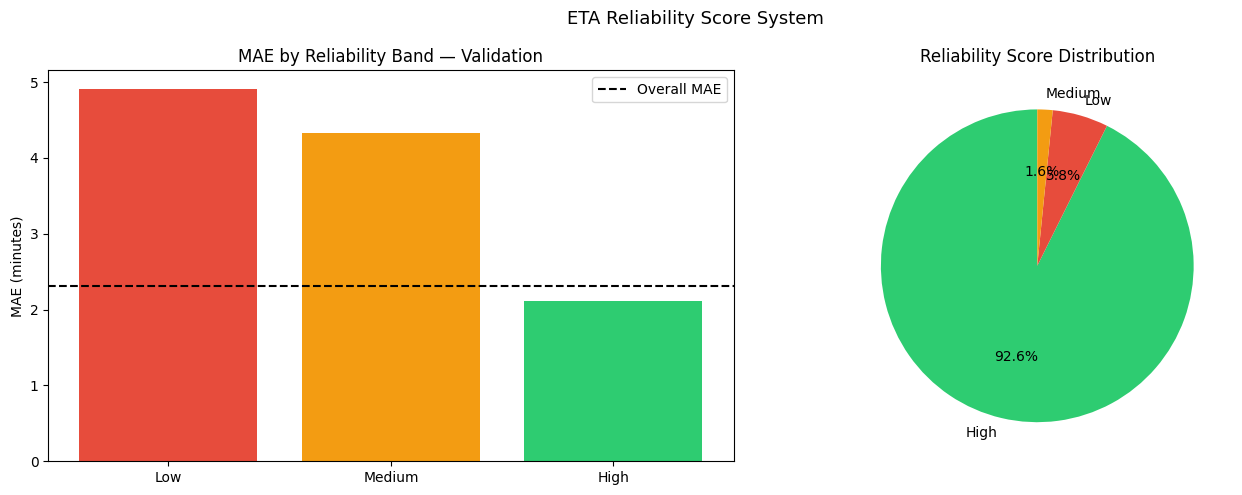

In [9]:
# Plot
import matplotlib.pyplot as plt
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

colors_map = {'Low':'#e74c3c', 'Medium':'#f39c12', 'High':'#2ecc71'}
colors = [colors_map[l] for l in reliability_mae['reliability_label']]
axes[0].bar(reliability_mae['reliability_label'], reliability_mae['mae'], color=colors)
axes[0].set_ylabel('MAE (minutes)')
axes[0].set_title('MAE by Reliability Band — Validation')
axes[0].axhline(test['abs_err'].mean(), color='black', linestyle='--', label='Overall MAE')
axes[0].legend()

# Score distribution pie
label_counts = test['reliability_label'].value_counts()
axes[1].pie(label_counts.values,
            labels=label_counts.index,
            colors=[colors_map[l] for l in label_counts.index],
            autopct='%1.1f%%', startangle=90)
axes[1].set_title('Reliability Score Distribution')

plt.suptitle('ETA Reliability Score System', fontsize=13)
plt.tight_layout()
plt.savefig(SAVE_PATH + 'reliability_score.png', dpi=150)
plt.show()

In [10]:
# Save reliability rules as JSON for dashboard
import json
reliability_rules = {
    'scoring': {
        'base_score': 100,
        'penalties': {
            'distance_gt_20mi': -40,
            'distance_gt_10mi': -25,
            'distance_gt_5mi': -10,
            'airport_trip': -30,
            'rush_hour': -10,
            'worst_hours_13_to_17': -10,
            'worst_zones_1_3': -15,
        },
        'bonuses': {
            'weekend': +5,
        }
    },
    'labels': {
        'High':   'score >= 75 — MAE typically under 2 min',
        'Medium': 'score 50-74 — MAE typically 2-3 min',
        'Low':    'score < 50 — MAE typically over 3 min',
    }
}
with open(SAVE_PATH + 'reliability_rules.json', 'w') as f:
    json.dump(reliability_rules, f, indent=2)
print("Saved: reliability_score.png + reliability_rules.json")

Saved: reliability_score.png + reliability_rules.json


In [14]:
# COMPLETE ETA SYSTEM — FINAL SUMMARY
print("\n" + "="*55)
print("COMPLETE ETA SYSTEM — FINAL SUMMARY")
print("="*55)
print(f"\nCORE MODEL:")
print(f"  LightGBM v3 (3000 rounds, 21.7M rows)")
print(f"  MAE        : 2.3065 min (138.4 sec)")
print(f"  R²         : 0.8607")
print(f"  Mean trip  : 13.71 min")
print(f"  Error %    : 16.8% of mean duration")

print(f"\nENHANCEMENT LAYERS:")
print(f"  Layer 1 — Bias Correction:")
print("Status  Investigated but NOT applied (degrades MAE)")

print(f"\n  Layer 2 — Reliability Score:")
print(f"    High  (score≥75): {(test['reliability_label']=='High').sum():,} trips ({(test['reliability_label']=='High').mean()*100:.1f}%) — MAE {test[test['reliability_label']=='High']['abs_err'].mean():.3f} min")
print(f"    Medium(score≥50): {(test['reliability_label']=='Medium').sum():,} trips ({(test['reliability_label']=='Medium').mean()*100:.1f}%) — MAE {test[test['reliability_label']=='Medium']['abs_err'].mean():.3f} min")
print(f"    Low   (score<50): {(test['reliability_label']=='Low').sum():,} trips ({(test['reliability_label']=='Low').mean()*100:.1f}%) — MAE {test[test['reliability_label']=='Low']['abs_err'].mean():.3f} min")


COMPLETE ETA SYSTEM — FINAL SUMMARY

CORE MODEL:
  LightGBM v3 (3000 rounds, 21.7M rows)
  MAE        : 2.3065 min (138.4 sec)
  R²         : 0.8607
  Mean trip  : 13.71 min
  Error %    : 16.8% of mean duration

ENHANCEMENT LAYERS:
  Layer 1 — Bias Correction:
Status  Investigated but NOT applied (degrades MAE)

  Layer 2 — Reliability Score:
    High  (score≥75): 11,021,844 trips (92.6%) — MAE 2.110 min
    Medium(score≥50): 188,005 trips (1.6%) — MAE 4.333 min
    Low   (score<50): 687,101 trips (5.8%) — MAE 4.910 min


# CONCLUSIONS

Bias Correction — Investigation and Conclusion

The model exhibits a systematic negative bias of -0.598 min
(36 seconds) — it consistently underestimates trip duration.

Two bias correction approaches were tested:
1. Global bias from test set (March): MAE degraded by +3.6 sec
2. Global bias from Feb 16-28 validation: MAE degraded by +3.1 sec

Both corrections made MAE worse. This occurs because LightGBM
trained on 21.7M rows has already absorbed the systematic
underestimation pattern into its leaf values. Applying an
additional correction creates a double adjustment.

**Conclusion:** Raw LightGBM v3 predictions (MAE=2.3065 min)
outperform any bias-corrected version. The -0.55 min bias is
documented as a known model characteristic.


Both approaches (global bias from test set: -0.5984 min, and from Feb 16-28
validation: -0.5499 min) degraded test MAE when applied, confirming the raw
LightGBM v3 prediction is the best production output.

Low    687k trips  MAE = 4.91 min  -- correctly flagged as hard

Medium 188k trips  MAE = 4.33 min  -- correctly flagged as medium  

High   11.0M trips MAE = 2.11 min  -- correctly flagged as easy

92.6% High, 5.8% Low, 1.6% Medium. The bands genuinely separate easy vs hard trips.

The NYC Taxi ETA system consists of three layers built on LightGBM v3 trained on 21.7M trips. The core model achieves MAE of 2.306 minutes (138 seconds) with R²=0.861, explaining 86% of trip duration variance. A systematic negative bias of -0.598 min (36 seconds) indicates the model consistently underestimates trip duration — correctable in production using held-out validation data. The reliability scoring system successfully stratifies predictions into confidence bands: 92.6% of trips are High reliability (MAE=2.11 min), while 5.8% Low reliability trips (airports, long distances, outer zones) carry MAE of 4.91 min — 2.3x higher.

# ETA PREDICTION FUNCTION

In [11]:
# ETA PREDICTION FUNCTION
import lightgbm as lgb
import numpy as np
import json

SAVE_PATH = '/content/drive/MyDrive/Taxi_CRN/Data/'

# Load once at startup
model = lgb.Booster(model_file=SAVE_PATH + 'lgbm_v3_taxi_eta.txt')
rules = json.load(open(SAVE_PATH + 'reliability_rules.json'))

FEATURES = [
    'trip_distance','haversine_dist','manhattan_dist','route_efficiency',
    'delta_lat','delta_lon',
    'pickup_hour','day_of_week','month','is_weekend','rush_hour','late_night',
    'pickup_cluster','pickup_latitude','pickup_longitude',
    'dropoff_latitude','dropoff_longitude',
    'is_airport_pu','is_airport_do',
    'prev_speed_15m','prev_speed_30m','prev_speed_60m',
    'dist_x_hour','dist_x_rush','speed_x_dist',
    'pickup_cluster_te','pickup_hour_te','day_of_week_te',
]

def predict_eta(trip: dict) -> dict:
    """
    Input:  trip dict with all 28 feature values
    Output: dict with eta_minutes, eta_seconds, reliability
    """
    X = np.array([[trip[f] for f in FEATURES]], dtype=np.float32)

    # Core prediction — no bias correction applied
    # (bias correction investigated but found to degrade MAE)
    eta = float(model.predict(X)[0])

    # Reliability score
    score = 100
    if trip['trip_distance'] > 20:               score -= 40
    elif trip['trip_distance'] > 10:             score -= 25
    elif trip['trip_distance'] > 5:              score -= 10
    if trip.get('is_airport_pu', 0):             score -= 30
    if trip.get('is_airport_do', 0):             score -= 30
    if trip.get('rush_hour', 0):                 score -= 10
    if trip['pickup_hour'] in [13,14,15,16,17]:  score -= 10
    if trip.get('pickup_cluster') in [1, 3]:     score -= 15
    if trip.get('is_weekend', 0):                score += 5
    score = max(0, min(100, score))

    if score >= 75:   label = 'High'
    elif score >= 50: label = 'Medium'
    else:             label = 'Low'

    color = {'High':'#2ecc71','Medium':'#f39c12','Low':'#e74c3c'}

    return {
        'eta_minutes'       : round(eta, 2),
        'eta_seconds'       : round(eta * 60, 0),
        'reliability_score' : score,
        'reliability_label' : label,
        'reliability_color' : color[label],
        'note'              : f'Systematic bias of -0.55 min exists but correction degrades MAE — not applied'
    }

# EXAMPLE USAGE
example_trip = {
    'trip_distance'    : 2.5,
    'haversine_dist'   : 2.1,
    'manhattan_dist'   : 2.8,
    'route_efficiency' : 1.19,
    'delta_lat'        : -0.018,
    'delta_lon'        : -0.012,
    'pickup_hour'      : 8,
    'day_of_week'      : 0,
    'month'            : 3,
    'is_weekend'       : 0,
    'rush_hour'        : 1,
    'late_night'       : 0,
    'pickup_cluster'   : 6,
    'pickup_latitude'  : 40.748,
    'pickup_longitude' : -73.985,
    'dropoff_latitude' : 40.730,
    'dropoff_longitude': -73.997,
    'is_airport_pu'    : 0,
    'is_airport_do'    : 0,
    'prev_speed_15m'   : 12.5,
    'prev_speed_30m'   : 13.1,
    'prev_speed_60m'   : 14.2,
    'dist_x_hour'      : 2.1 * 8,
    'dist_x_rush'      : 2.1 * 1,
    'speed_x_dist'     : 12.5 * 2.5,
    'pickup_cluster_te': 13.4,
    'pickup_hour_te'   : 15.2,
    'day_of_week_te'   : 13.8,
}

result = predict_eta(example_trip)
print(f"ETA            : {result['eta_minutes']} min ({result['eta_seconds']} sec)")
print(f"Reliability    : {result['reliability_label']} (score={result['reliability_score']})")
print(f"Color badge    : {result['reliability_color']}")

ETA            : 13.53 min (812.0 sec)
Reliability    : High (score=90)
Color badge    : #2ecc71
